In [1]:
from pathlib import Path
import os

# Resolver la raíz desde el notebook, la raíz del repositorio o una ruta explícita.
def localizar_proyecto():
    base = Path(os.environ.get("IA_PROJECT_ROOT", Path.cwd())).resolve()
    for candidata in [base, *base.parents]:
        if (candidata / "data/processed/enaho_personas_2025.csv").is_file():
            return candidata
    raise FileNotFoundError("No se encontró la carpeta de entrega con data/processed")

RAIZ_PROYECTO = localizar_proyecto()
os.environ.setdefault("OMP_NUM_THREADS", "4")
print("Proyecto:", RAIZ_PROYECTO)


Proyecto: D:\Proyectos Grandes Curos 2026-2\Examen de Inteligencia Artificial\Entrega_Final_IA



# Proyecto IA: Brecha Digital y Rendimiento Escolar en el Perú

## 1. Identificación e inspección de fuentes

### 1.1. Identificación de las fuentes de información

Se realiza el reconocimiento de los archivos originales de ENAHO y ESCALE 2025. El objetivo es verificar su disponibilidad, formato y organización antes de iniciar la limpieza y la integración de las tablas.

Esta etapa permite identificar posibles diferencias entre los archivos proporcionados y las estructuras descritas en la guía de evaluación.


### Alcance de la reproducción distribuida

La ejecución utiliza los extractos íntegros de 2025 incluidos en `data/processed`,
los ZIP originales compactos de ESCALE y dos cachés de columnas ENAHO con año,
llaves, grado y factores. Los cachés se extraen de las fuentes panel sin imputación
ni alteración de valores. Se reproducen las integraciones, las diez configuraciones,
el clustering, la evaluación y SHAP desde un kernel limpio. La obtención de los
microdatos completos de varios gigabytes se documenta por separado.


### 1.1.1. Diseño analítico y trazabilidad

Los resultados experimentales de referencia corresponden al corte 2025 extraído de
los archivos ENAHO panel 2021–2025. Se conservan las salidas originales de las diez
configuraciones supervisadas, el clustering y la evaluación final. La reproducción del
análisis utiliza la misma semilla, los mismos registros y las mismas particiones.

Las extensiones descriptivas ponderadas y por área se presentan separadamente y no
sustituyen X, y ni los predictores del modelo definitivo. Las nuevas ejecuciones
escriben tablas, figuras y modelo en `resultados/reproducido`, manteniendo las
evidencias originales de `resultados`. Los CSV presentes se reutilizan tras comprobar
estructura, corte temporal, cantidades y llaves; su coherencia con la fuente completa
no se infiere únicamente de esas verificaciones.


In [2]:

# Importar bibliotecas para trabajar con rutas y archivos
from pathlib import Path
import pandas as pd

# Definir la ubicación principal del proyecto
carpeta = Path(
    str(RAIZ_PROYECTO)
)

# Comprobar que la carpeta existe
print("Carpeta encontrada:", carpeta.exists())
print("Ubicación:", carpeta)

# Buscar los archivos de datos, incluso en subcarpetas
extensiones = {".csv", ".zip", ".dbf"}

archivos = sorted([
    archivo for archivo in carpeta.rglob("*")
    if archivo.is_file()
    and archivo.suffix.lower() in extensiones
])

# Construir una tabla con el inventario encontrado
inventario = pd.DataFrame([
    {
        "Archivo": archivo.name,
        "Formato": archivo.suffix.lower(),
        "Tamaño (MB)": round(
            archivo.stat().st_size / (1024 ** 2), 2
        ),
        "Ubicación relativa": str(archivo.relative_to(carpeta))
    }
    for archivo in archivos
])

# Mostrar los resultados
print("\nINVENTARIO DE DATOS")
display(inventario)

print("Total de archivos encontrados:", len(archivos))


Carpeta encontrada: True
Ubicación: D:\Proyectos Grandes Curos 2026-2\Examen de Inteligencia Artificial\Entrega_Final_IA

INVENTARIO DE DATOS


,Archivo,Formato,Tamaño (MB),Ubicación relativa
0,clasificacion_actualizada_2025.csv,.csv,6.51,data\processed\clasificacion_actualizada_2025.csv
1,dataset_enaho_escale_2025.csv,.csv,6.51,data\processed\dataset_enaho_escale_2025.csv
2,dataset_integrado_preliminar_2025.csv,.csv,7.12,data\processed\dataset_integrado_preliminar_20...
3,enaho_educacion_2025.csv,.csv,5.41,data\processed\enaho_educacion_2025.csv
4,enaho_personas_2025.csv,.csv,5.28,data\processed\enaho_personas_2025.csv
5,enaho_sumaria_2025.csv,.csv,2.62,data\processed\enaho_sumaria_2025.csv
6,enaho_vivienda_2025.csv,.csv,1.75,data\processed\enaho_vivienda_2025.csv
7,maestro_actualizado_2025.csv,.csv,7.75,data\processed\maestro_actualizado_2025.csv
8,00_Padlocal.zip,.zip,2.39,data\raw\00_Padlocal.zip
9,00_Padron.zip,.zip,10.72,data\raw\00_Padron.zip


Total de archivos encontrados: 25



### 1.1.2. Interpretación del inventario inicial

Se identificaron 18 archivos distribuidos entre formatos CSV y ZIP. Los datos de ENAHO incluyen módulos de vivienda, características individuales, educación, salud, empleo y sumarias económicas.

Para el objetivo de esta investigación se priorizarán los módulos 100, 200, 300 y Sumaria, además de los registros educativos de ESCALE.

Los archivos ENAHO corresponden a una estructura panel 2021–2025, por lo que será necesario verificar las variables específicas de 2025 antes de realizar las uniones.

Debido al tamaño de los microdatos, se evitará cargar columnas innecesarias durante el procesamiento.



### 1.2. Verificación de integridad de archivos comprimidos

Se examina la estructura de los paquetes ZIP para identificar los archivos internos y verificar que su formato sea válido.

Este procedimiento permite detectar errores de descarga antes de comenzar la lectura de los microdatos, conservando intactas las fuentes originales.


In [3]:

# Importar herramientas para verificar archivos ZIP
from zipfile import ZipFile, is_zipfile, BadZipFile

# Seleccionar únicamente los archivos .zip del inventario
archivos_zip = [
    archivo for archivo in archivos
    if archivo.suffix.lower() == ".zip"
]

print("AUDITORÍA DE ARCHIVOS COMPRIMIDOS")
print("=" * 60)

# Examinar cada ZIP sin extraer su contenido
for ruta_zip in archivos_zip:

    print(f"\nArchivo: {ruta_zip.name}")

    # Comprobar que el formato ZIP sea válido
    if not is_zipfile(ruta_zip):
        print("Estado: NO es un archivo ZIP válido")
        continue

    try:
        # Consultar el índice interno del archivo comprimido
        with ZipFile(ruta_zip) as comprimido:

            # Obtener nombres de archivos, excluyendo carpetas
            nombres = [
                nombre for nombre in comprimido.namelist()
                if not nombre.endswith("/")
            ]

            print("Estado: ZIP válido")
            print("Archivos internos:", len(nombres))

            # Mostrar una muestra de hasta 8 archivos internos
            for nombre in nombres[:8]:
                print("  -", nombre)

    except (BadZipFile, OSError) as error:
        print("Error de lectura:", error)

print("\nVerificación terminada.")


AUDITORÍA DE ARCHIVOS COMPRIMIDOS

Archivo: 00_Padlocal.zip
Estado: ZIP válido
Archivos internos: 1
  - Padlocal.dbf

Archivo: 00_Padron.zip
Estado: ZIP válido
Archivos internos: 1
  - Padron.dbf

Verificación terminada.



### 1.3. Inspección estructural de los microdatos ENAHO

Se examinan los encabezados de los módulos de vivienda, población, educación y sumaria económica para identificar las variables disponibles del año 2025.

Debido a que los archivos corresponden a una estructura panel y presentan tamaños elevados, se inspeccionarán inicialmente sus encabezados sin cargar todos los registros en memoria.

Se verificará la presencia de identificadores de vivienda, hogar, persona, ubicación geográfica y variables socioeducativas necesarias para la integración posterior.


In [4]:

# Importar herramientas para inspeccionar archivos CSV
import csv
from pathlib import Path
import pandas as pd

# Definir la ubicación principal de los datasets
carpeta = Path(
    str(RAIZ_PROYECTO)
)

# Identificar los cuatro módulos principales del estudio
modulos = {
    "Vivienda y hogar": "enaho_vivienda_2025.csv",
    "Miembros del hogar": "enaho_personas_2025.csv",
    "Educación y TIC": "enaho_educacion_2025.csv",
    "Sumaria económica": "enaho_sumaria_2025.csv"
}

# Identificadores que necesitamos para relacionar tablas
llaves = ["AÑO", "CONGLOME", "VIVIENDA",
          "HOGAR", "CODPERSO", "UBIGEO"]

# Variables importantes descritas en la guía
variables = [
    "P1121", "P1144", "P207", "P208A",
    "P300A", "P306", "P307", "P308A",
    "P308B", "P314A", "P314B", "P316",
    "POBREZA", "GASHOG2D", "INGHOG2D",
    "FACTOR07"
]

resultados = []

# Examinar cada módulo de manera independiente
for descripcion, nombre_archivo in modulos.items():

    # Localizar el CSV dentro de las subcarpetas
    ruta = next(
        (p for p in carpeta.rglob("*.csv")
         if p.name.lower() == nombre_archivo.lower()),
        None
    )

    if ruta is None:
        print(f"\nNo encontrado: {nombre_archivo}")
        continue

    # Leer únicamente la primera línea del archivo
    # UTF-8-SIG permite manejar la marca BOM
    with open(ruta, "r", encoding="utf-8-sig", newline="") as f:
        lector = csv.reader(f)
        columnas = next(lector)

    # Normalizar nombres solo para la inspección
    columnas_normalizadas = [
        col.strip().upper() for col in columnas
    ]

    # Reconocer variables correspondientes a 2025
    columnas_2025 = [
        col for col in columnas_normalizadas
        if col.endswith("_25")
    ]

    # Localizar llaves y variables de interés
    encontradas = [
        col for col in columnas_normalizadas
        if any(
            col == nombre or col.startswith(nombre + "_")
            for nombre in llaves + variables
        )
    ]

    # Guardar el resumen estructural
    resultados.append({
        "Módulo": descripcion,
        "Columnas totales": len(columnas),
        "Columnas _25": len(columnas_2025),
        "Variables relevantes": len(encontradas)
    })

    print("\n" + "=" * 65)
    print("MÓDULO:", descripcion)
    print("Columnas totales:", len(columnas))
    print("Columnas 2025:", len(columnas_2025))
    print("Primeras 12 columnas:", columnas_normalizadas[:12])
    print("Variables relevantes:", encontradas[:35])

# Construir tabla comparativa
resumen = pd.DataFrame(resultados)

print("\nRESUMEN DE ESTRUCTURA ENAHO")
display(resumen)



MÓDULO: Vivienda y hogar
Columnas totales: 10
Columnas 2025: 9
Primeras 12 columnas: ['NUMPANH', 'AÑO_25', 'CONGLOME_25', 'VIVIENDA_25', 'HOGAR_25', 'UBIGEO_25', 'DOMINIO_25', 'ESTRATO_25', 'P1121_25', 'P1144_25']
Variables relevantes: ['AÑO_25', 'CONGLOME_25', 'VIVIENDA_25', 'HOGAR_25', 'UBIGEO_25', 'P1121_25', 'P1144_25']

MÓDULO: Miembros del hogar
Columnas totales: 10
Columnas 2025: 9
Primeras 12 columnas: ['NUMPER', 'NUMPANH_25', 'AÑO_25', 'CONGLOME_25', 'VIVIENDA_25', 'HOGAR_25', 'CODPERSO_25', 'UBIGEO_25', 'P207_25', 'P208A_25']
Variables relevantes: ['AÑO_25', 'CONGLOME_25', 'VIVIENDA_25', 'HOGAR_25', 'CODPERSO_25', 'UBIGEO_25', 'P207_25', 'P208A_25']

MÓDULO: Educación y TIC
Columnas totales: 14
Columnas 2025: 13
Primeras 12 columnas: ['NUMPER', 'NUMPANH_25', 'AÑO_25', 'CONGLOME_25', 'VIVIENDA_25', 'HOGAR_25', 'CODPERSO_25', 'UBIGEO_25', 'P300A_25', 'P306_25', 'P307_25', 'P308A_25']
Variables relevantes: ['AÑO_25', 'CONGLOME_25', 'VIVIENDA_25', 'HOGAR_25', 'CODPERSO_25', 'UBI

,Módulo,Columnas totales,Columnas _25,Variables relevantes
0,Vivienda y hogar,10,9,7
1,Miembros del hogar,10,9,8
2,Educación y TIC,14,13,12
3,Sumaria económica,10,9,9



### 1.4. Lectura selectiva de variables correspondientes a 2025

Se realiza una lectura preliminar de los cuatro módulos principales de ENAHO, seleccionando los identificadores y las variables socioeconómicas y educativas correspondientes a 2025.

Dada la estructura longitudinal de los archivos, se conservan inicialmente los identificadores originales del panel y las columnas del año de estudio. Se utiliza una lectura limitada para verificar su estructura sin comprometer la memoria disponible.

Esta fase es exploratoria; todavía no se aplican filtros definitivos, imputaciones ni uniones entre tablas.


In [5]:

# Importar las bibliotecas necesarias
from pathlib import Path
import pandas as pd

# Carpeta donde están almacenados los datasets
carpeta = Path(
    str(RAIZ_PROYECTO)
)

# Definir archivos y variables relevantes de cada módulo
configuracion = {
    "Vivienda": {
        "archivo": "enaho_vivienda_2025.csv",
        "columnas": [
            "NUMPANH", "AÑO_25", "CONGLOME_25",
            "VIVIENDA_25", "HOGAR_25", "UBIGEO_25",
            "DOMINIO_25", "ESTRATO_25",
            "P1121_25", "P1144_25"
        ]
    },

    "Personas": {
        "archivo": "enaho_personas_2025.csv",
        "columnas": [
            "NUMPER", "NUMPANH_25", "AÑO_25",
            "CONGLOME_25", "VIVIENDA_25",
            "HOGAR_25", "CODPERSO_25",
            "UBIGEO_25", "P207_25", "P208A_25"
        ]
    },

    "Educacion": {
        "archivo": "enaho_educacion_2025.csv",
        "columnas": [
            "NUMPER", "NUMPANH_25", "AÑO_25",
            "CONGLOME_25", "VIVIENDA_25",
            "HOGAR_25", "CODPERSO_25",
            "UBIGEO_25", "P300A_25",
            "P306_25", "P307_25",
            "P308A_25", "P308B_25",
            "P314A_25", "P314B_25", "P316_25"
        ]
    },

    "Sumaria": {
        "archivo": "enaho_sumaria_2025.csv",
        "columnas": [
            "NUMPANH", "AÑO_25",
            "CONGLOME_25", "VIVIENDA_25",
            "HOGAR_25", "UBIGEO_25",
            "POBREZA_25", "INGHOG2D_25",
            "GASHOG2D_25", "FACTOR07_25"
        ]
    }
}

# Almacenar pequeñas muestras de cada módulo
muestras = {}

# Revisar cada CSV de forma independiente
for modulo, datos in configuracion.items():

    # Buscar la ubicación real del archivo
    ruta = next(
        (
            p for p in carpeta.rglob("*.csv")
            if p.name.lower() == datos["archivo"].lower()
        ),
        None
    )

    if ruta is None:
        print(f"\nNo se encontró el módulo: {modulo}")
        continue

    # Preparar las columnas que queremos examinar
    columnas_objetivo = set(datos["columnas"])

    # Leer solo 8 registros y las columnas seleccionadas
    # UTF-8-SIG interpreta correctamente los encabezados con BOM
    # dtype=str conserva los ceros a la izquierda
    df = pd.read_csv(
        ruta,
        encoding="utf-8-sig",
        dtype=str,
        nrows=8,
        usecols=lambda c: c.strip().upper() in columnas_objetivo,
        na_values=["", " ", "  ", "    ", "      "],
        low_memory=False
    )

    # Normalizar nombres de columnas de la muestra
    df.columns = df.columns.str.strip().str.upper()

    # Identificar variables presentes y ausentes
    presentes = [
        c for c in datos["columnas"] if c in df.columns
    ]

    ausentes = [
        c for c in datos["columnas"] if c not in df.columns
    ]

    # Conservar la muestra para las siguientes comprobaciones
    muestras[modulo] = df

    print("\n" + "=" * 65)
    print("MÓDULO:", modulo)
    print("Columnas encontradas:", len(presentes))
    print("Variables ausentes:", ausentes)

    # Mostrar los primeros registros de forma transpuesta
    # Así podemos leer mejor los nombres de las variables
    display(df.head(3).T)

print("\nLECTURA PRELIMINAR FINALIZADA")



MÓDULO: Vivienda
Columnas encontradas: 10
Variables ausentes: []


,0,1,2
NUMPANH,4972,4973,4974
AÑO_25,2025,2025,2025
CONGLOME_25,015014,015014,015014
VIVIENDA_25,010,025,039
HOGAR_25,11,11,11
UBIGEO_25,010101,010101,010101
DOMINIO_25,4,4,4
ESTRATO_25,4,4,4
P1121_25,1,1,1
P1144_25,1,1,1



MÓDULO: Personas
Columnas encontradas: 10
Variables ausentes: []


,0,1,2
NUMPER,388417,388411,388412
NUMPANH_25,149536,149535,149535
AÑO_25,2025,2025,2025
CONGLOME_25,015001,015001,015001
VIVIENDA_25,069,029,029
HOGAR_25,11,11,11
CODPERSO_25,04,02,03
UBIGEO_25,010101,010101,010101
P207_25,2,1,2
P208A_25,85,33,3



MÓDULO: Educacion
Columnas encontradas: 14
Variables ausentes: ['P314B_25', 'P316_25']


,0,1,2
NUMPER,15189,15190,15191
NUMPANH_25,6453,6453,6454
AÑO_25,2025,2025,2025
CONGLOME_25,015623,015623,015623
VIVIENDA_25,001,001,005
HOGAR_25,11,11,11
CODPERSO_25,01,02,01
UBIGEO_25,040103,040103,040103
P300A_25,4,4,1
P306_25,2,2,2



MÓDULO: Sumaria
Columnas encontradas: 10
Variables ausentes: []


,0,1,2
NUMPANH,149537,149538,149535
AÑO_25,2025,2025,2025
CONGLOME_25,015001,015001,015001
VIVIENDA_25,089,113,029
HOGAR_25,11,11,11
UBIGEO_25,010101,010101,010101
INGHOG2D_25,50429.7265625,104950.6171875,23209.0078125
GASHOG2D_25,48684.7265625,65974.875,23898.47265625
POBREZA_25,3,3,3
FACTOR07_25,184.864181518555,184.864181518555,184.864181518555



LECTURA PRELIMINAR FINALIZADA



## 2. Preparación, integración y validación ENAHO 2025

### 2.1. Selección temporal y reducción de variables

Los archivos ENAHO presentan una estructura longitudinal correspondiente al periodo 2021–2025.

Para desarrollar el análisis se seleccionarán los registros que contienen información del año 2025, conservando los identificadores relacionales y las variables pertinentes al problema educativo y digital.

Se aplicará una estrategia de lectura por bloques para reducir el consumo de memoria RAM, manteniendo intactos los archivos originales.

La selección de registros del panel no supone automáticamente equivalencia con la muestra anual ENAHO 2025; dicha limitación será considerada en la interpretación del estudio.


In [6]:
# ============================================================
# VALIDACIÓN DE CSV PROCESADOS ANTES DE SU REUTILIZACIÓN
# ============================================================

from pathlib import Path
import pandas as pd

def validar_csv_procesado(ruta, columnas_esperadas, llaves, filas_esperadas):
    # Conservar los identificadores como texto y normalizar solo una copia.
    tabla_validada = pd.read_csv(ruta, encoding="utf-8-sig", dtype="string")
    tabla_validada.columns = tabla_validada.columns.str.strip().str.upper()
    esperadas = [str(c).strip().upper() for c in columnas_esperadas]
    if len(tabla_validada.columns) != len(esperadas) or set(tabla_validada.columns) != set(esperadas):
        raise ValueError(f"Estructura distinta de la esperada: {Path(ruta).name}")
    if len(tabla_validada) != filas_esperadas:
        raise ValueError(f"Cantidad de registros distinta: {Path(ruta).name}")
    for columna in llaves:
        tabla_validada[columna] = tabla_validada[columna].str.strip().replace("", pd.NA)
    if tabla_validada[llaves].isna().any().any():
        raise ValueError(f"Llaves incompletas: {Path(ruta).name}")
    if tabla_validada.duplicated(llaves).any():
        raise ValueError(f"Llaves repetidas: {Path(ruta).name}")
    longitudes = {"CONGLOME_25": 6, "VIVIENDA_25": 3,
                  "HOGAR_25": 2, "CODPERSO_25": 2}
    for columna in llaves:
        patron = rf"\d{{{longitudes[columna]}}}"
        if not tabla_validada[columna].str.fullmatch(patron, na=False).all():
            raise ValueError(f"Formato inválido en {columna}: {Path(ruta).name}")
    for columna in tabla_validada.columns:
        if columna.startswith("AÑO_25"):
            valores_anio = tabla_validada[columna].str.strip()
            presentes_anio = valores_anio.notna() & valores_anio.ne("")
            if columna in ["AÑO_25", "AÑO_25_P200"] and not presentes_anio.all():
                raise ValueError(f"Año principal ausente: {Path(ruta).name}")
            if not valores_anio.loc[presentes_anio].isin(["2025", "2025.0"]).all():
                raise ValueError(f"Corte temporal inconsistente: {Path(ruta).name}")
        if columna.startswith("UBIGEO_25"):
            valores = tabla_validada[columna].str.strip()
            presentes = valores.notna() & valores.ne("")
            if not valores.loc[presentes].str.fullmatch(r"\d{6}", na=False).all():
                raise ValueError(f"UBIGEO inválido: {Path(ruta).name}")
    return tabla_validada


In [7]:
# ============================================================
# EXTRACCIÓN O REUTILIZACIÓN VALIDADA DEL CORTE 2025
# ============================================================

from pathlib import Path
import pandas as pd

raiz = Path(str(RAIZ_PROYECTO))
salida = raiz / "data" / "processed"
salida.mkdir(parents=True, exist_ok=True)
rutas_2025 = {}
resumen_extraccion = []
filas_referencia = {"Vivienda": 44599, "Personas": 115145,
                    "Educacion": 106958, "Sumaria": 33702}

for modulo, datos in configuracion.items():
    destino = salida / f"enaho_{modulo.lower()}_2025.csv"
    # Dos nombres genéricos de TIC no existen como campos únicos en este panel.
    columnas_esperadas = [c for c in datos["columnas"]
                          if c not in {"P314B_25", "P316_25"}]
    llaves = ["CONGLOME_25", "VIVIENDA_25", "HOGAR_25"]
    if modulo in ["Personas", "Educacion"]:
        llaves.append("CODPERSO_25")
    bloques_validos = 0
    if destino.exists():
        datos_reutilizados = validar_csv_procesado(
            destino, columnas_esperadas, llaves, filas_referencia[modulo]
        )
        total_2025 = len(datos_reutilizados)
        origen = "CSV existente validado"
        print(f"\nReutilizando {modulo}: {total_2025:,} registros")
    else:
        ruta = next((p for p in raiz.rglob("*.csv")
                     if p.name.lower() == datos["archivo"].lower()), None)
        if ruta is None:
            raise FileNotFoundError(f"No se encontró la fuente de {modulo}")
        cabecera = pd.read_csv(ruta, encoding="utf-8-sig", nrows=0)
        disponibles = [str(c).strip().upper() for c in cabecera.columns]
        orden_fuente = [c for c in disponibles if c in set(columnas_esperadas)]
        if set(orden_fuente) != set(columnas_esperadas):
            raise ValueError(f"La fuente de {modulo} no contiene las columnas requeridas")
        # La escritura exclusiva impide reemplazar cualquier CSV preexistente.
        total_2025 = 0
        with destino.open("x", encoding="utf-8-sig", newline="") as archivo_destino:
            lector = pd.read_csv(
                ruta, encoding="utf-8-sig", dtype="string",
                usecols=lambda c: c.strip().upper() in set(columnas_esperadas),
                chunksize=10000, na_values=["", " ", "  ", "     "]
            )
            for bloque in lector:
                bloque.columns = bloque.columns.str.strip().str.upper()
                anio = bloque["AÑO_25"].str.strip()
                datos_2025 = bloque.loc[anio.isin(["2025", "2025.0"])].copy()
                if datos_2025.empty:
                    continue
                for columna in llaves + ["UBIGEO_25"]:
                    datos_2025[columna] = datos_2025[columna].str.strip().replace("", pd.NA)
                datos_2025 = datos_2025[orden_fuente]
                datos_2025.to_csv(archivo_destino, header=(bloques_validos == 0), index=False)
                total_2025 += len(datos_2025)
                bloques_validos += 1
        validar_csv_procesado(destino, columnas_esperadas, llaves, filas_referencia[modulo])
        origen = "Generación exclusiva desde fuente"
        print(f"\nGenerado {modulo}: {total_2025:,} registros")
    rutas_2025[modulo] = destino
    resumen_extraccion.append({"Módulo": modulo, "Registros 2025": total_2025,
                              "Bloques guardados": bloques_validos, "Origen": origen})

tabla_extraccion = pd.DataFrame(resumen_extraccion)
print("\nRESUMEN DE EXTRACCIÓN Y REUTILIZACIÓN")
display(tabla_extraccion)



Reutilizando Vivienda: 44,599 registros



Reutilizando Personas: 115,145 registros



Reutilizando Educacion: 106,958 registros



Reutilizando Sumaria: 33,702 registros

RESUMEN DE EXTRACCIÓN Y REUTILIZACIÓN


,Módulo,Registros 2025,Bloques guardados,Origen
0,Vivienda,44599,0,CSV existente validado
1,Personas,115145,0,CSV existente validado
2,Educacion,106958,0,CSV existente validado
3,Sumaria,33702,0,CSV existente validado


In [8]:
# Resumen de los archivos procesados reutilizados en el corte de referencia.
display(tabla_extraccion)


,Módulo,Registros 2025,Bloques guardados,Origen
0,Vivienda,44599,0,CSV existente validado
1,Personas,115145,0,CSV existente validado
2,Educacion,106958,0,CSV existente validado
3,Sumaria,33702,0,CSV existente validado



### 2.2. Análisis exploratorio de calidad de los datos (EDA)

Se examinan los cuatro módulos ENAHO correspondientes al año 2025 para determinar su calidad antes de la integración.

El diagnóstico comprende:

- Cantidad de registros y variables.
- Porcentaje de valores faltantes.
- Identificación de registros duplicados.
- Validación de llaves de hogar y persona.
- Identificación de la población escolar de 6 a 17 años.

Los resultados servirán para fundamentar las decisiones de limpieza y evitar pérdidas innecesarias de información.


In [9]:

# Importar bibliotecas para análisis de datos
import pandas as pd
from pathlib import Path

# Ubicar la carpeta de archivos procesados
carpeta_datos = Path(
    str(RAIZ_PROYECTO / 'data/processed')
)

# Relacionar cada módulo con su archivo procesado
archivos_enaho = {
    "Vivienda": "enaho_vivienda_2025.csv",
    "Personas": "enaho_personas_2025.csv",
    "Educacion": "enaho_educacion_2025.csv",
    "Sumaria": "enaho_sumaria_2025.csv"
}

# Almacenar cada tabla de manera independiente
datos_enaho = {}

for modulo, archivo in archivos_enaho.items():

    # Leer solo los CSV reducidos, no los originales gigantes
    df = pd.read_csv(
        carpeta_datos / archivo,
        encoding="utf-8-sig",
        dtype="string"
    )

    # Conservar encabezados uniformes
    df.columns = df.columns.str.strip().str.upper()

    # Guardar el DataFrame correspondiente
    datos_enaho[modulo] = df

    print(f"{modulo}: {df.shape[0]:,} filas y {df.shape[1]} columnas")

print("\nLos cuatro módulos están disponibles para el EDA.")


Vivienda: 44,599 filas y 10 columnas


Personas: 115,145 filas y 10 columnas


Educacion: 106,958 filas y 14 columnas
Sumaria: 33,702 filas y 10 columnas

Los cuatro módulos están disponibles para el EDA.


In [10]:

# ==================================================
# DIAGNÓSTICO DE CALIDAD DE LOS CUATRO MÓDULOS
# ==================================================

resultados_eda = []

for modulo, df in datos_enaho.items():

    # Definir las llaves según el nivel de cada módulo
    llaves = [
        "CONGLOME_25",
        "VIVIENDA_25",
        "HOGAR_25"
    ]

    # Los módulos personales requieren además CODPERSO
    if modulo in ["Personas", "Educacion"]:
        llaves.append("CODPERSO_25")

    # Verificar qué llaves existen realmente
    llaves_presentes = all(c in df.columns for c in llaves)

    if llaves_presentes:

        # Identificar registros con llaves completas
        completos = df.dropna(subset=llaves)

        # Detectar repeticiones de identificadores
        duplicados_llave = completos.duplicated(
            subset=llaves
        ).sum()

        faltantes_llave = len(df) - len(completos)

    else:
        duplicados_llave = pd.NA
        faltantes_llave = pd.NA

    # Calcular indicadores de calidad
    resultados_eda.append({
        "Módulo": modulo,
        "Filas": len(df),
        "Columnas": len(df.columns),
        "Nulos (%)": round(
            df.isna().mean().mean() * 100, 2
        ),
        "Filas duplicadas": int(df.duplicated().sum()),
        "Llaves incompletas": faltantes_llave,
        "Llaves repetidas": duplicados_llave
    })

# Presentar la auditoría en una tabla
tabla_eda = pd.DataFrame(resultados_eda)

display(tabla_eda)

# Mostrar las seis columnas con más valores faltantes
for modulo, df in datos_enaho.items():

    print(f"\nVALORES FALTANTES: {modulo}")

    porcentaje = (
        df.isna().mean() * 100
    ).sort_values(ascending=False)

    display(
        porcentaje.head(6)
        .round(2)
        .to_frame("Porcentaje de nulos")
    )


,Módulo,Filas,Columnas,Nulos (%),Filas duplicadas,Llaves incompletas,Llaves repetidas
0,Vivienda,44599,10,4.89,0,0,0
1,Personas,115145,10,0.78,0,0,0
2,Educacion,106958,14,16.35,0,0,0
3,Sumaria,33702,10,0.00,0,0,0



VALORES FALTANTES: Vivienda


,Porcentaje de nulos
P1144_25,24.43
P1121_25,24.43
AÑO_25,0.00
NUMPANH,0.00
CONGLOME_25,0.00
VIVIENDA_25,0.00



VALORES FALTANTES: Personas


,Porcentaje de nulos
P208A_25,3.88
P207_25,3.88
NUMPANH_25,0.00
NUMPER,0.00
AÑO_25,0.00
CONGLOME_25,0.00



VALORES FALTANTES: Educacion


,Porcentaje de nulos
P308B_25,72.48
P307_25,72.48
P308A_25,72.48
P314A_25,6.58
P306_25,2.45
P300A_25,2.45



VALORES FALTANTES: Sumaria


,Porcentaje de nulos
NUMPANH,0.0
AÑO_25,0.0
CONGLOME_25,0.0
VIVIENDA_25,0.0
HOGAR_25,0.0
UBIGEO_25,0.0


In [11]:

# Obtener el módulo de características personales
personas = datos_enaho["Personas"]

# Convertir la edad a formato numérico para realizar comparaciones
edad = pd.to_numeric(
    personas["P208A_25"],
    errors="coerce"
)

# Identificar estudiantes potenciales entre 6 y 17 años
filtro_escolar = edad.between(6, 17)

# Crear una tabla independiente sin modificar los datos originales
personas_escolares = personas.loc[filtro_escolar].copy()

# Mostrar los resultados del filtrado
print("Registros del módulo Personas:", len(personas))
print("Personas de 6 a 17 años:", len(personas_escolares))

print("\nDistribución de edades:")

# Presentar frecuencias por edad
frecuencias = (
    edad[filtro_escolar]
    .value_counts()
    .sort_index()
)

display(frecuencias.to_frame("Cantidad"))


Registros del módulo Personas: 115145
Personas de 6 a 17 años: 24195

Distribución de edades:


,Cantidad
P208A_25,
6,1641
7,1746
8,1873
9,1883
10,2011
11,2087
12,2206
13,2077
14,2234



### 2.3. Integración de características personales y educativas

Se relacionan los registros de personas de 6 a 17 años con la información del módulo educativo mediante los identificadores de conglomerado, vivienda, hogar y persona correspondientes a 2025.

Antes de aceptar la unión, se verificará la unicidad de las llaves, la cantidad de coincidencias y la consistencia del UBIGEO.

Se emplea una unión izquierda para conservar inicialmente la población objetivo y permitir la identificación de registros sin información educativa correspondiente.


In [12]:

# ============================================================
# 2.5 INTEGRACIÓN DE PERSONAS Y EDUCACIÓN
# ============================================================

# Definir los identificadores de una persona dentro de su hogar
llaves_persona = [
    "CONGLOME_25",
    "VIVIENDA_25",
    "HOGAR_25",
    "CODPERSO_25"
]

# Crear copias para no modificar las tablas originales
df_personas = personas_escolares.copy()
df_educacion = datos_enaho["Educacion"].copy()

# Normalizar espacios en los identificadores
for df in [df_personas, df_educacion]:
    for columna in llaves_persona:
        df[columna] = df[columna].str.strip()

# Comprobar que todas las llaves estén completas
for nombre, df in [
    ("Personas", df_personas),
    ("Educación", df_educacion)
]:
    nulos_llave = df[llaves_persona].isna().any(axis=1).sum()
    duplicados = df.duplicated(subset=llaves_persona).sum()

    print(f"{nombre}:")
    print("  Llaves incompletas:", nulos_llave)
    print("  Llaves duplicadas:", duplicados)

    # Detener la integración si existe una ambigüedad
    if nulos_llave > 0 or duplicados > 0:
        raise ValueError(
            f"Es necesario revisar las llaves de {nombre}"
        )

# Relacionar las tablas preservando la población escolar
# validate evita uniones que multipliquen indebidamente filas
df_personas_educacion = df_personas.merge(
    df_educacion,
    on=llaves_persona,
    how="left",
    validate="one_to_one",
    indicator=True,
    suffixes=("_P200", "_P300")
)

# Auditar la cantidad de coincidencias
print("\nRESULTADOS DE LA INTEGRACIÓN")
print("Registros resultantes:", len(df_personas_educacion))

print("\nEstado del cruce:")
print(df_personas_educacion["_merge"].value_counts())

# Comprobar consistencia geográfica entre módulos coincidentes
coincidencias = df_personas_educacion[
    df_personas_educacion["_merge"] == "both"
]

ubigeos_distintos = (
    coincidencias["UBIGEO_25_P200"]
    .ne(coincidencias["UBIGEO_25_P300"])
    .fillna(False)
    .sum()
)

print("\nUBIGEOS distintos entre módulos:", ubigeos_distintos)

# Mostrar únicamente una muestra del resultado integrado
display(df_personas_educacion.head(5))


Personas:


  Llaves incompletas: 0
  Llaves duplicadas: 0
Educación:
  Llaves incompletas: 0
  Llaves duplicadas: 0



RESULTADOS DE LA INTEGRACIÓN
Registros resultantes: 24195

Estado del cruce:
_merge
both          23668
left_only       527
right_only        0
Name: count, dtype: int64

UBIGEOS distintos entre módulos: 0


,NUMPER_P200,NUMPANH_25_P200,AÑO_25_P200,CONGLOME_25,VIVIENDA_25,HOGAR_25,CODPERSO_25,UBIGEO_25_P200,P207_25,P208A_25,...,NUMPANH_25_P300,AÑO_25_P300,UBIGEO_25_P300,P300A_25,P306_25,P307_25,P308A_25,P308B_25,P314A_25,_merge
0,388423,149538,2025,015001,113,11,03,010101,2,16,...,149538,2025,010101,4,1,1,3,5,1,both
1,388427,149539,2025,015001,130,11,03,010101,1,9,...,149539,2025,010101,4,1,1,2,0,2,both
2,388424,149538,2025,015001,113,11,04,010101,2,13,...,149538,2025,010101,4,1,1,3,2,1,both
3,388432,149542,2025,015003,041,11,04,010101,1,17,...,149542,2025,010101,4,2,<NA>,<NA>,<NA>,1,both
4,388441,149548,2025,015003,116,11,04,010101,2,9,...,149548,2025,010101,4,1,1,2,0,1,both



### 2.4. Integración de información socioeconómica y condiciones del hogar

Se incorporan las características de vivienda y las variables económicas de ENAHO a la población de 6 a 17 años.

Las uniones se realizan mediante los identificadores de conglomerado, vivienda y hogar correspondientes a 2025.

Se verifica la unicidad de las llaves y se utiliza una relación muchos-a-uno, ya que varios integrantes pueden pertenecer a un mismo hogar. También se registra la cantidad de coincidencias para evaluar la cobertura de las fuentes.


In [13]:

# ==========================================================
# 2.6 INTEGRACIÓN DE VIVIENDA Y SUMARIA
# ==========================================================

# Identificadores que permiten reconocer cada hogar
llaves_hogar = [
    "CONGLOME_25",
    "VIVIENDA_25",
    "HOGAR_25"
]

# Crear el dataset maestro preliminar
maestro = df_personas_educacion.copy()

# Incorporar las dos fuentes a nivel de hogar
for nombre in ["Vivienda", "Sumaria"]:

    # Trabajar sobre una copia de los datos originales
    tabla_hogar = datos_enaho[nombre].copy()

    # Normalizar espacios en los identificadores
    for columna in llaves_hogar:
        tabla_hogar[columna] = (
            tabla_hogar[columna].str.strip()
        )

    # Revisar llaves incompletas
    nulos = tabla_hogar[llaves_hogar].isna().any(axis=1).sum()

    # Revisar identificadores duplicados
    duplicados = tabla_hogar.duplicated(
        subset=llaves_hogar
    ).sum()

    print(f"\nVerificando {nombre}")
    print("Llaves incompletas:", nulos)
    print("Llaves repetidas:", duplicados)

    # Evitar uniones ambiguas
    if nulos > 0 or duplicados > 0:
        raise ValueError(
            f"Revisar identificadores del módulo {nombre}"
        )

    # Registrar cantidad de filas antes de integrar
    filas_antes = len(maestro)

    # Agregar características del hogar a cada persona
    maestro = maestro.merge(
        tabla_hogar,
        on=llaves_hogar,
        how="left",
        validate="many_to_one",
        indicator=f"_cruce_{nombre.lower()}",
        suffixes=("", f"_{nombre.upper()}")
    )

    # Confirmar que no se multiplicaron los registros
    assert len(maestro) == filas_antes

    # Evaluar coincidencias con el módulo
    print(f"\nResultado de unión con {nombre}:")
    print(
        maestro[f"_cruce_{nombre.lower()}"]
        .value_counts()
    )

    print("Registros conservados:", len(maestro))

# Mostrar dimensiones del dataset integrado
print("\nDIMENSIONES DEL DATASET MAESTRO PRELIMINAR")
print("Filas:", maestro.shape[0])
print("Columnas:", maestro.shape[1])

display(maestro.head(5))



Verificando Vivienda
Llaves incompletas: 0
Llaves repetidas: 0



Resultado de unión con Vivienda:
_cruce_vivienda
both          24195
left_only         0
right_only        0
Name: count, dtype: int64
Registros conservados: 24195

Verificando Sumaria
Llaves incompletas: 0
Llaves repetidas: 0



Resultado de unión con Sumaria:
_cruce_sumaria
both          24195
left_only         0
right_only        0
Name: count, dtype: int64
Registros conservados: 24195

DIMENSIONES DEL DATASET MAESTRO PRELIMINAR
Filas: 24195
Columnas: 37


,NUMPER_P200,NUMPANH_25_P200,AÑO_25_P200,CONGLOME_25,VIVIENDA_25,HOGAR_25,CODPERSO_25,UBIGEO_25_P200,P207_25,P208A_25,...,P1144_25,_cruce_vivienda,NUMPANH_SUMARIA,AÑO_25_SUMARIA,UBIGEO_25_SUMARIA,INGHOG2D_25,GASHOG2D_25,POBREZA_25,FACTOR07_25,_cruce_sumaria
0,388423,149538,2025,015001,113,11,03,010101,2,16,...,1,both,149538,2025,010101,104950.6171875,65974.875,3,184.864181518555,both
1,388427,149539,2025,015001,130,11,03,010101,1,9,...,1,both,149539,2025,010101,82377.640625,49647.0390625,3,184.864181518555,both
2,388424,149538,2025,015001,113,11,04,010101,2,13,...,1,both,149538,2025,010101,104950.6171875,65974.875,3,184.864181518555,both
3,388432,149542,2025,015003,041,11,04,010101,1,17,...,1,both,149542,2025,010101,40769,35428.78515625,3,84.8905944824219,both
4,388441,149548,2025,015003,116,11,04,010101,2,9,...,1,both,149548,2025,010101,24952,41025.21484375,3,84.8905944824219,both



### 2.5. Validación de consistencia geográfica entre módulos

Se verifica que los registros integrados conserven la misma identificación distrital en los módulos de personas, educación, vivienda y sumaria.

Esta comprobación permite detectar posibles inconsistencias geográficas antes de incorporar las variables contextuales de ESCALE mediante el UBIGEO.


In [14]:

# ==========================================================
# 2.7 VALIDACIÓN GEOGRÁFICA DE LOS MÓDULOS ENAHO
# ==========================================================

import pandas as pd

# Identificar las columnas UBIGEO existentes en el dataset
columnas_geo = [
    col for col in maestro.columns
    if "UBIGEO" in col.upper()
]

print("COLUMNAS GEOGRÁFICAS ENCONTRADAS:")
print(columnas_geo)

# Asociar cada módulo con su columna geográfica real
columnas_ubigeo = {
    "Personas": "UBIGEO_25_P200",
    "Educacion": "UBIGEO_25_P300",
    "Vivienda": "UBIGEO_25",
    "Sumaria": "UBIGEO_25_SUMARIA"
}

# Comprobar que existen las columnas necesarias
for modulo, columna in columnas_ubigeo.items():
    if columna not in maestro.columns:
        raise KeyError(
            f"No se encontró la columna {columna} del módulo {modulo}"
        )

# Utilizar el UBIGEO de Personas como referencia
ubigeo_base = (
    maestro["UBIGEO_25_P200"]
    .astype("string")
    .str.strip()
)

resultados_geo = []

# Comparar los demás módulos con Personas
for modulo in ["Educacion", "Vivienda", "Sumaria"]:

    columna = columnas_ubigeo[modulo]

    # Obtener los códigos geográficos del módulo
    ubigeo_actual = (
        maestro[columna]
        .astype("string")
        .str.strip()
    )

    # Comparar únicamente registros con ambos códigos
    comparables = (
        ubigeo_base.notna() & ubigeo_actual.notna()
    )

    # Contar registros sin comparación posible
    sin_comparacion = (~comparables).sum()

    # Identificar diferencias reales entre los códigos
    diferencias = (
        ubigeo_base[comparables] != ubigeo_actual[comparables]
    ).sum()

    resultados_geo.append({
        "Modulo": modulo,
        "Sin comparacion": int(sin_comparacion),
        "UBIGEO diferentes": int(diferencias)
    })

# Presentar resultados
auditoria_geo = pd.DataFrame(resultados_geo)

print("\nRESULTADOS DE VALIDACIÓN GEOGRÁFICA")
display(auditoria_geo)

# Mostrar el resultado de la validación
if auditoria_geo["UBIGEO diferentes"].sum() == 0:
    print("No se detectaron diferencias entre los UBIGEO comparables.")
else:
    print("Se identificaron inconsistencias geográficas.")


COLUMNAS GEOGRÁFICAS ENCONTRADAS:
['UBIGEO_25_P200', 'UBIGEO_25_P300', 'UBIGEO_25', 'UBIGEO_25_SUMARIA']



RESULTADOS DE VALIDACIÓN GEOGRÁFICA


,Modulo,Sin comparacion,UBIGEO diferentes
0,Educacion,527,0
1,Vivienda,0,0
2,Sumaria,0,0


No se detectaron diferencias entre los UBIGEO comparables.



## 3. Integración ESCALE y validación educativa

### 3.1. Lectura y reconocimiento de archivos DBF

Se examinan las bases del Padrón de Instituciones Educativas y de Locales Escolares del MINEDU para identificar su estructura y los atributos disponibles.

Se verificará la correspondencia entre los nombres de las variables descritos en la guía y los campos reales de las bases.

Posteriormente, la información escolar será agregada a nivel distrital para su integración con los microdatos de ENAHO mediante el código UBIGEO.


In [15]:
import importlib.util
assert importlib.util.find_spec('dbfread') is not None, "Instale las dependencias de requirements.txt"


In [16]:

# ============================================================
# 3.2. INSPECCIÓN DE BASES ESCALE 2025
# ============================================================

from pathlib import Path
from zipfile import ZipFile
from shutil import copyfileobj
from itertools import islice
from dbfread import DBF
import pandas as pd

# Definir la ubicación de nuestro proyecto
raiz = Path(
    str(RAIZ_PROYECTO)
)

# Preparar carpeta para copias temporales de trabajo
carpeta_intermedia = raiz / "data" / "interim"
carpeta_intermedia.mkdir(parents=True, exist_ok=True)

# Identificar las dos bases principales de ESCALE
bases_escale = {
    "Padron": ("00_Padron.zip", "Padron.dbf"),
    "Padlocal": ("00_Padlocal.zip", "Padlocal.dbf")
}

tablas_dbf = {}

for nombre, (nombre_zip, nombre_dbf) in bases_escale.items():

    # Localizar el archivo comprimido original
    ruta_zip = next(
        (p for p in raiz.rglob(nombre_zip) if p.is_file()),
        None
    )

    if ruta_zip is None:
        raise FileNotFoundError(f"No se encontró {nombre_zip}")

    # Definir dónde guardar la copia de trabajo
    destino = carpeta_intermedia / nombre_dbf

    # Extraer únicamente si todavía no existe la copia
    if not destino.exists():

        with ZipFile(ruta_zip) as comprimido:

            # Buscar el archivo DBF dentro del ZIP
            interno = next(
                (
                    n for n in comprimido.namelist()
                    if Path(n).name.lower() == nombre_dbf.lower()
                ),
                None
            )

            if interno is None:
                raise FileNotFoundError(
                    f"No se encontró {nombre_dbf} dentro del ZIP"
                )

            # Copiar el contenido sin modificar el original
            with comprimido.open(interno) as origen:
                with destino.open("xb") as salida:
                    copyfileobj(origen, salida)

    # Abrir el DBF con lectura diferida
    tabla = DBF(
        str(destino),
        encoding="latin1",
        char_decode_errors="ignore",
        load=False
    )

    tablas_dbf[nombre] = tabla

    # Mostrar dimensiones y campos originales
    print("\n" + "=" * 65)
    print("BASE:", nombre)
    print("Registros:", len(tabla))
    print("Columnas:", len(tabla.field_names))
    print("Nombres de columnas:")
    print(tabla.field_names)

    # Mostrar solamente tres registros
    muestra = pd.DataFrame(list(islice(tabla, 3)))

    print("\nMUESTRA DE REGISTROS")
    display(muestra.T)

print("\nINSPECCIÓN ESCALE FINALIZADA")



BASE: Padron
Registros: 112724
Columnas: 59
Nombres de columnas:
['CODINST', 'COD_MOD', 'ANEXO', 'CODLOCAL', 'CEN_EDU', 'NIV_MOD', 'D_NIV_MOD', 'D_FORMA', 'TIPSSEXO', 'D_TIPSSEXO', 'GESTION', 'D_GESTION', 'GES_DEP', 'D_GES_DEP', 'DIRECTOR', 'TELEFONO', 'EMAIL', 'PAGWEB', 'DIR_CEN', 'LOCALIDAD', 'CODCP_INEI', 'CODCCPP', 'CEN_POB', 'AREA_CENSO', 'DAREACENSO', 'CODGEO', 'D_DPTO', 'D_PROV', 'D_DIST', 'D_REGION', 'CODOOII', 'D_DREUGEL', 'NLAT_IE', 'NLONG_IE', 'TIPOPROG', 'D_TIPOPROG', 'COD_TUR', 'D_COD_TUR', 'NRORUC', 'RZSOCIAL', 'PROMOTOR', 'ESTADO', 'D_ESTADO', 'FECHAREG', 'FECHA_ACT', 'GRAD_2000', 'ZFRONTERA', 'PAIS_COLID', 'VRAEM', 'INTE_VRAEM', 'TALUM', 'TALUM_HOM', 'TALUM_MUJ', 'TDOC', 'TSEC', 'COD_CAR', 'D_COD_CAR', 'IMPUTADO', 'DES_IMPUTA']

MUESTRA DE REGISTROS


,0,1,2
CODINST,24953981,25273230,20414731
COD_MOD,0415547,0415638,0415646
ANEXO,0,0,0
CODLOCAL,016100,015172,015186
CEN_EDU,123,122,233
NIV_MOD,A2,A2,A2
D_NIV_MOD,Inicial - Jardín,Inicial - Jardín,Inicial - Jardín
D_FORMA,Escolarizada,Escolarizada,Escolarizada
TIPSSEXO,3,3,3
D_TIPSSEXO,Mixto,Mixto,Mixto



BASE: Padlocal
Registros: 69642
Columnas: 19
Nombres de columnas:
['CODLOCAL', 'DIR_CEN', 'LOCALIDAD', 'CODCP_INEI', 'CODCCPP', 'CEN_POB', 'CODGEO', 'D_DPTO', 'D_PROV', 'D_DIST', 'D_REGION', 'CODOOII', 'D_DREUGEL', 'ESTADO', 'D_ESTADO', 'CLOC_L1', 'AREA_LOC', 'GES_LOC', 'TIP_ENVIO']

MUESTRA DE REGISTROS


,0,1,2
CODLOCAL,016100,015172,015186
DIR_CEN,JIRON TERESA GONZALES DE FANNY 543,JIRON 28 DE JULIO S/N,JIRON AMADEO FIGUEROA S/N
LOCALIDAD,NICRUPAMPA,HUARUPAMPA,
CODCP_INEI,0201050001,0201010001,
CODCCPP,129688,114517,610619
CEN_POB,CENTENARIO,HUARUPAMPA,LA SOLEDAD
CODGEO,020105,020101,020101
D_DPTO,ANCASH,ANCASH,ANCASH
D_PROV,HUARAZ,HUARAZ,HUARAZ
D_DIST,INDEPENDENCIA,HUARAZ,HUARAZ



INSPECCIÓN ESCALE FINALIZADA



### 3.2. Limpieza y agregación de indicadores escolares

Se seleccionan los registros activos de instituciones educativas y locales escolares de ESCALE.

Se identifican las instituciones de educación inicial, primaria y secundaria, se convierten las variables cuantitativas a formato numérico y se construyen indicadores por distrito.

Entre los indicadores se incluyen el número de servicios educativos, locales escolares, total de alumnos y docentes, ratio alumnos/docente, proporción de gestión pública y coordenadas medias válidas.

La agregación evita relaciones muchos-a-muchos al integrar ESCALE con los microdatos de ENAHO.


In [17]:

# ============================================================
# 3.3 LIMPIEZA Y AGREGACIÓN DE DATOS ESCALE
# ============================================================

import pandas as pd

# Seleccionar únicamente las columnas necesarias de los DBF
campos_padron = [
    "CODGEO", "COD_MOD", "CODLOCAL",
    "D_NIV_MOD", "DAREACENSO", "D_GESTION",
    "ESTADO", "TALUM", "TDOC", "TSEC",
    "NLAT_IE", "NLONG_IE"
]

campos_local = [
    "CODGEO", "CODLOCAL", "ESTADO"
]

# Cargar únicamente los campos elegidos
# No se almacenan las 59 columnas completas
padron = pd.DataFrame.from_records(
    (
        {c: registro.get(c) for c in campos_padron}
        for registro in tablas_dbf["Padron"]
    ),
    columns=campos_padron
)

padlocal = pd.DataFrame.from_records(
    (
        {c: registro.get(c) for c in campos_local}
        for registro in tablas_dbf["Padlocal"]
    ),
    columns=campos_local
)

# Estandarizar los códigos distritales
for df in [padron, padlocal]:

    df["CODGEO"] = (
        df["CODGEO"]
        .astype("string")
        .str.strip()
        .str.zfill(6)
    )

    df["ESTADO"] = (
        df["ESTADO"]
        .astype("string")
        .str.strip()
    )

# Identificar las modalidades escolares disponibles
print("NIVELES EDUCATIVOS MÁS FRECUENTES:")
display(padron["D_NIV_MOD"].value_counts().head(20))

# Seleccionar instituciones activas
# y niveles inicial, primaria o secundaria
nivel = padron["D_NIV_MOD"].astype("string").str.strip()

filtro_nivel = nivel.str.startswith(
    ("Inicial", "Primaria", "Secundaria"),
    na=False
)

filtro_activo = padron["ESTADO"].eq("1")

escuelas = padron.loc[
    filtro_nivel & filtro_activo
].copy()

# Conservar distritos con códigos válidos
escuelas = escuelas.loc[
    escuelas["CODGEO"].str.fullmatch(r"\d{6}", na=False)
].copy()

# Convertir las variables numéricas
for columna in ["TALUM", "TDOC", "TSEC",
                "NLAT_IE", "NLONG_IE"]:

    escuelas[columna] = pd.to_numeric(
        escuelas[columna],
        errors="coerce"
    )

# Tratar valores negativos de conteos como inválidos
for columna in ["TALUM", "TDOC", "TSEC"]:
    escuelas.loc[
        escuelas[columna] < 0, columna
    ] = float("nan")

# Excluir coordenadas fuera del rango geográfico
# aproximado del territorio peruano
escuelas.loc[
    ~escuelas["NLAT_IE"].between(-19, 0),
    "NLAT_IE"
] = float("nan")

escuelas.loc[
    ~escuelas["NLONG_IE"].between(-82, -68),
    "NLONG_IE"
] = float("nan")

# Identificar instituciones públicas y privadas
gestion = escuelas["D_GESTION"].astype("string").str.strip()

escuelas["ES_PUBLICA"] = (
    gestion.str.startswith("Pública", na=False).astype(int)
)

escuelas["ES_PRIVADA"] = (
    gestion.str.startswith("Privada", na=False).astype(int)
)

# Agregar indicadores por distrito
escale_distrital = escuelas.groupby(
    "CODGEO", as_index=False
).agg(
    servicios_educativos=("COD_MOD", "nunique"),
    alumnos_distrito=("TALUM", "sum"),
    docentes_distrito=("TDOC", "sum"),
    secciones_distrito=("TSEC", "sum"),
    colegios_publicos=("ES_PUBLICA", "sum"),
    colegios_privados=("ES_PRIVADA", "sum"),
    latitud_media=("NLAT_IE", "mean"),
    longitud_media=("NLONG_IE", "mean")
)

# Calcular ratio de alumnos por docente
# No dividir por cero
escale_distrital["ratio_alumnos_docente"] = (
    escale_distrital["alumnos_distrito"]
    / escale_distrital["docentes_distrito"].replace(0, float("nan"))
)

# Calcular proporción de gestión pública
total_gestion = (
    escale_distrital["colegios_publicos"]
    + escale_distrital["colegios_privados"]
)

escale_distrital["proporcion_publicos"] = (
    escale_distrital["colegios_publicos"]
    / total_gestion.replace(0, float("nan"))
)

# Contar locales activos únicos por distrito
locales_activos = padlocal.loc[
    (padlocal["ESTADO"] == "1")
    & padlocal["CODGEO"].str.fullmatch(r"\d{6}", na=False)
].copy()

conteo_locales = (
    locales_activos.groupby("CODGEO")["CODLOCAL"]
    .nunique()
    .reset_index(name="locales_escolares")
)

# Añadir la información de Padlocal a los distritos
escale_distrital = escale_distrital.merge(
    conteo_locales,
    on="CODGEO",
    how="left",
    validate="one_to_one"
)

print("\nRESUMEN DE ESCALE")
print("Registros originales de Padrón:", len(padron))
print("Instituciones seleccionadas:", len(escuelas))
print("Distritos agregados:", len(escale_distrital))
print("Localidades escolares en Padlocal:", len(padlocal))

display(escale_distrital.head())


NIVELES EDUCATIVOS MÁS FRECUENTES:


D_NIV_MOD
Primaria                                   38338
Inicial - Jardín                           33221
Inicial - Programa no escolarizado         17668
Secundaria                                 15700
Inicial - Cuna-jardín                       1802
Técnico Productiva                          1633
Básica Alternativa-Avanzado                 1522
Básica Alternativa-Inicial e Intermedio      854
Instituto Superior Tecnológico               769
Básica Especial-Primaria                     467
Básica Especial-Inicial                      368
Instituto Superior Pedagógico                133
Básica Especial                              130
Escuela Superior Pedagógica                   50
Escuela Formación Artística                   32
Inicial - Cuna                                23
Escuela Superior Tecnológica                  14
Name: count, dtype: int64


RESUMEN DE ESCALE
Registros originales de Padrón: 112724
Instituciones seleccionadas: 106752
Distritos agregados: 1892
Localidades escolares en Padlocal: 69642


,CODGEO,servicios_educativos,alumnos_distrito,docentes_distrito,secciones_distrito,colegios_publicos,colegios_privados,latitud_media,longitud_media,ratio_alumnos_docente,proporcion_publicos,locales_escolares
0,010101,60,10406.0,599.0,470.0,51,9,-6.231162,-77.867021,17.372287,0.85,44.0
1,010102,4,14.0,4.0,9.0,4,0,-6.006375,-77.726734,3.500000,1.00,4.0
2,010103,21,397.0,37.0,77.0,21,0,-6.813159,-77.974352,10.729730,1.00,14.0
3,010104,7,120.0,16.0,26.0,7,0,-6.265156,-77.701966,7.500000,1.00,5.0
4,010105,11,75.0,10.0,40.0,11,0,-6.090543,-77.778191,7.500000,1.00,8.0



### 3.3. Integración final de microdatos ENAHO y ESCALE

Se unen los registros de personas de 6 a 17 años con los indicadores escolares distritales calculados a partir del Padrón y Padlocal del MINEDU.

La relación se establece mediante el código distrital UBIGEO, comprobando que la integración conserve una observación por persona y registrando los casos sin correspondencia geográfica.

Se obtiene una versión preliminar del dataset maestro integrado, sobre el cual continuarán las comprobaciones de calidad y la preparación para Machine Learning.


In [18]:

# ============================================================
# 3.4 INTEGRACIÓN FINAL ENAHO + ESCALE
# ============================================================

# Crear copia de la tabla ENAHO previamente integrada
dataset_maestro = maestro.copy()

# Estandarizar la llave geográfica de Personas
dataset_maestro["UBIGEO_25_P200"] = (
    dataset_maestro["UBIGEO_25_P200"]
    .astype("string")
    .str.strip()
    .str.zfill(6)
)

# Incorporar los indicadores escolares por distrito
dataset_maestro = dataset_maestro.merge(
    escale_distrital,
    left_on="UBIGEO_25_P200",
    right_on="CODGEO",
    how="left",
    validate="many_to_one",
    indicator="_cruce_escale"
)

# Mostrar resultados de correspondencia
print("RESULTADO DEL CRUCE ENAHO + ESCALE")
print(dataset_maestro["_cruce_escale"].value_counts())

print("\nDIMENSIONES DEL DATASET MAESTRO")
print("Personas:", dataset_maestro.shape[0])
print("Variables:", dataset_maestro.shape[1])

# Verificar que la cantidad de personas no cambió
assert len(dataset_maestro) == 24195, (
    "La cantidad de personas cambió inesperadamente"
)

# Identificar registros sin indicadores escolares
sin_escale = (
    dataset_maestro["_cruce_escale"] == "left_only"
).sum()

print("\nPersonas sin correspondencia ESCALE:", sin_escale)

# Guardar una versión preliminar sin sobrescribir
# el dataset final que prepararemos después de limpiar
destino_preliminar = (
    carpeta_datos / "dataset_integrado_preliminar_2025.csv"
)

if destino_preliminar.exists():
    validar_csv_procesado(
        destino_preliminar, list(dataset_maestro.columns), llaves_persona, len(dataset_maestro)
    )
    print("\nEl archivo preliminar existente fue validado; no se sobrescribió.")
else:
    dataset_maestro.to_csv(
        destino_preliminar,
        index=False,
        encoding="utf-8-sig"
    )
    print("\nDataset preliminar guardado:")
    print(destino_preliminar)

# Mostrar algunas columnas útiles para comprobar el cruce
display(dataset_maestro[
    [
        "P208A_25",
        "UBIGEO_25_P200",
        "P1144_25",
        "POBREZA_25",
        "servicios_educativos",
        "ratio_alumnos_docente",
        "proporcion_publicos",
        "_cruce_escale"
    ]
].head(10))


RESULTADO DEL CRUCE ENAHO + ESCALE
_cruce_escale
both          24195
left_only         0
right_only        0
Name: count, dtype: int64

DIMENSIONES DEL DATASET MAESTRO
Personas: 24195
Variables: 50

Personas sin correspondencia ESCALE: 0



El archivo preliminar existente fue validado; no se sobrescribió.


,P208A_25,UBIGEO_25_P200,P1144_25,POBREZA_25,servicios_educativos,ratio_alumnos_docente,proporcion_publicos,_cruce_escale
0,16,010101,1,3,60,17.372287,0.85,both
1,9,010101,1,3,60,17.372287,0.85,both
2,13,010101,1,3,60,17.372287,0.85,both
3,17,010101,1,3,60,17.372287,0.85,both
4,9,010101,1,3,60,17.372287,0.85,both
5,12,010101,1,3,60,17.372287,0.85,both
6,11,010101,1,3,60,17.372287,0.85,both
7,6,010101,1,3,60,17.372287,0.85,both
8,14,010101,1,3,60,17.372287,0.85,both
9,6,010101,1,3,60,17.372287,0.85,both



### 3.4. Auditoría de calidad y consistencia del dataset integrado

Antes de realizar el modelado, se evalúa la calidad de las variables educativas, socioeconómicas y escolares del dataset maestro ENAHO–ESCALE 2025.

Se examinan las distribuciones de respuestas, los valores faltantes, la cobertura de los módulos y la coherencia de los indicadores escolares.

Se presta especial atención a los códigos de preguntas educativas utilizados para construir la variable objetivo de rezago escolar y a la pertinencia de los niveles educativos incluidos en la agregación distrital.

No se eliminan ni imputan valores durante esta auditoría.


In [19]:

# ============================================================
# 3.5.1 AUDITORÍA DE VARIABLES ENAHO
# ============================================================

# Utilizar el dataset integrado sin modificarlo
df_auditoria = dataset_maestro.copy()

# Variables relevantes para nuestro proyecto
variables_revisar = [
    "P208A_25",    # Edad
    "P306_25",     # Variable educativa
    "P307_25",     # Variable educativa
    "P308A_25",    # Nivel educativo
    "P308B_25",    # Grado educativo
    "P314A_25",    # Uso de Internet / TIC
    "P1144_25",    # Servicio del hogar
    "POBREZA_25"   # Condición socioeconómica
]

# Revisar las distribuciones sin interpretar todavía
# los códigos como respuestas definitivas
for variable in variables_revisar:

    if variable not in df_auditoria.columns:
        print(f"\nNo existe la columna: {variable}")
        continue

    serie = (
        df_auditoria[variable]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )

    porcentaje_nulos = serie.isna().mean() * 100

    print("\n" + "=" * 55)
    print("VARIABLE:", variable)
    print(f"Valores faltantes: {porcentaje_nulos:.2f}%")

    # Mostrar hasta 15 categorías y sus cantidades
    display(
        serie.value_counts(dropna=False)
        .head(15)
        .to_frame("Cantidad")
    )

# Revisar cobertura del módulo educativo
print("\nCOBERTURA DE INFORMACIÓN EDUCATIVA")
print(df_auditoria["_merge"].value_counts())



VARIABLE: P208A_25
Valores faltantes: 0.00%


,Cantidad
P208A_25,
14,2234
15,2207
12,2206
16,2173
11,2087
13,2077
17,2057
10,2011
9,1883



VARIABLE: P306_25
Valores faltantes: 2.38%


,Cantidad
P306_25,
1,20278
2,3340
<NA>,577



VARIABLE: P307_25
Valores faltantes: 16.19%


...


VARIABLE: P1144_25
Valores faltantes: 0.00%


,Cantidad
P1144_25,
1,23008
0,1187



VARIABLE: POBREZA_25
Valores faltantes: 0.00%


,Cantidad
POBREZA_25,
3,16936
2,5753
1,1506



COBERTURA DE INFORMACIÓN EDUCATIVA
_merge
both          23668
left_only       527
right_only        0
Name: count, dtype: int64


In [20]:

# ============================================================
# 3.5.2 AUDITORÍA DE INDICADORES ESCOLARES
# ============================================================

# Revisar qué niveles quedaron en la selección anterior
print("NIVELES INCLUIDOS ACTUALMENTE")
display(
    escuelas["D_NIV_MOD"]
    .value_counts(dropna=False)
    .to_frame("Servicios")
)

# Revisar datos faltantes y valores cero
print("\nCALIDAD DE VARIABLES CUANTITATIVAS")

indicadores = ["TALUM", "TDOC", "TSEC"]

resumen_calidad = []

for variable in indicadores:

    resumen_calidad.append({
        "Variable": variable,
        "Nulos": int(escuelas[variable].isna().sum()),
        "Ceros": int((escuelas[variable] == 0).sum()),
        "Negativos": int((escuelas[variable] < 0).sum()),
        "Máximo": escuelas[variable].max()
    })

display(pd.DataFrame(resumen_calidad))

# Identificar servicios con estudiantes,
# pero sin docentes registrados
casos_revisar = escuelas.loc[
    (escuelas["TALUM"] > 0) &
    (
        escuelas["TDOC"].isna() |
        (escuelas["TDOC"] == 0)
    )
]

print("\nServicios con alumnos pero sin docentes registrados:")
print(len(casos_revisar))

# Examinar cómo se distribuyen los ratios distritales
print("\nDISTRIBUCIÓN DEL RATIO ALUMNOS/DOCENTE")

display(
    escale_distrital["ratio_alumnos_docente"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99])
    .to_frame("Valor")
)

# Mostrar distritos con ratios más altos para investigar
print("\nDISTRITOS CON RATIOS MÁS ALTOS")

display(
    escale_distrital[
        ["CODGEO", "alumnos_distrito",
         "docentes_distrito", "ratio_alumnos_docente"]
    ]
    .sort_values(
        "ratio_alumnos_docente",
        ascending=False
    )
    .head(10)
)


NIVELES INCLUIDOS ACTUALMENTE


,Servicios
D_NIV_MOD,
Primaria,38338
Inicial - Jardín,33221
Inicial - Programa no escolarizado,17668
Secundaria,15700
Inicial - Cuna-jardín,1802
Inicial - Cuna,23



CALIDAD DE VARIABLES CUANTITATIVAS


,Variable,Nulos,Ceros,Negativos,Máximo
0,TALUM,0,0,0,3711.0
1,TDOC,0,17668,0,221.0
2,TSEC,0,0,0,134.0



Servicios con alumnos pero sin docentes registrados:
17668

DISTRIBUCIÓN DEL RATIO ALUMNOS/DOCENTE


,Valor
count,1891.000000
mean,11.040454
std,4.212264
min,2.294118
25%,7.856376
50%,10.371486
75%,14.132409
95%,18.546524
99%,20.596678
max,26.166667



DISTRITOS CON RATIOS MÁS ALTOS


,CODGEO,alumnos_distrito,docentes_distrito,ratio_alumnos_docente
349,040115,157.0,6.0,26.166667
1548,180302,265.0,11.0,24.090909
1253,131202,15848.0,692.0,22.901734
1011,110108,10533.0,460.0,22.897826
372,040301,1703.0,76.0,22.407895
1016,110113,1111.0,50.0,22.220000
1519,170102,12250.0,553.0,22.151899
376,040305,833.0,38.0,21.921053
1008,110105,2206.0,103.0,21.417476
1821,220910,7294.0,344.0,21.203488



### 3.5. Recuperación y validación del grado escolar

Se incorpora la variable P308C_25 del módulo ENAHO 300, correspondiente al grado de estudios.

Se recupera mediante lectura por bloques y se relaciona con el dataset maestro utilizando las llaves compuestas de persona.

Esta corrección permite distinguir el año de estudios del grado escolar y evita definir incorrectamente la variable objetivo de rezago escolar.


In [21]:

# ======================================================
# DIAGNÓSTICO DEL ARCHIVO ORIGINAL ENAHO 300
# ======================================================

import pandas as pd
from pathlib import Path

# Localizar el archivo original de Educación
ruta_educacion = next(
    (raiz / "data/raw").glob("grados_educativos_2025.csv"),
    None
)

if ruta_educacion is None:
    raise FileNotFoundError("No se encontró el archivo ENAHO 300")

print("ARCHIVO ENCONTRADO:")
print(ruta_educacion)

# Revisar el separador de la primera línea
# Sin cargar el CSV completo en memoria
with open(ruta_educacion, "r", encoding="utf-8-sig") as f:
    primera_linea = f.readline()

separadores = [",", ";", "\t", "|"]

for sep in separadores:
    print(
        f"Separador {repr(sep)}:",
        primera_linea.count(sep),
        "apariciones"
    )

# Identificar el separador más frecuente
separador = max(
    separadores,
    key=primera_linea.count
)

# Leer solamente el encabezado
encabezado = pd.read_csv(
    ruta_educacion,
    encoding="utf-8-sig",
    sep=separador,
    nrows=0
)

# Normalizar los nombres para comprobarlos
columnas_reales = [
    str(c).strip().upper()
    for c in encabezado.columns
]

print("\nTOTAL DE COLUMNAS:", len(columnas_reales))

print("\nPRIMERAS 15 COLUMNAS:")
print(columnas_reales[:15])

print("\nVARIABLES P308 ENCONTRADAS:")
print([
    c for c in columnas_reales
    if "P308" in c and c.endswith("_25")
])

print("\nIDENTIFICADORES DE 2025:")
print([
    c for c in columnas_reales
    if c in {
        "AÑO_25", "CONGLOME_25",
        "VIVIENDA_25", "HOGAR_25",
        "CODPERSO_25", "UBIGEO_25"
    }
])


ARCHIVO ENCONTRADO:
D:\Proyectos Grandes Curos 2026-2\Examen de Inteligencia Artificial\Entrega_Final_IA\data\raw\grados_educativos_2025.csv
Separador ',': 6 apariciones
Separador ';': 0 apariciones
Separador '\t': 0 apariciones
Separador '|': 0 apariciones

TOTAL DE COLUMNAS: 7

PRIMERAS 15 COLUMNAS:
['AÑO_25', 'CONGLOME_25', 'VIVIENDA_25', 'HOGAR_25', 'CODPERSO_25', 'P308C_25', 'P308D_25']

VARIABLES P308 ENCONTRADAS:
['P308C_25', 'P308D_25']

IDENTIFICADORES DE 2025:
['AÑO_25', 'CONGLOME_25', 'VIVIENDA_25', 'HOGAR_25', 'CODPERSO_25']


In [22]:

# ============================================================
# 3.6 RECUPERACIÓN CORREGIDA DE VARIABLES EDUCATIVAS
# ============================================================

import pandas as pd

# Llaves que identifican a cada persona
llaves_persona = [
    "CONGLOME_25", "VIVIENDA_25",
    "HOGAR_25", "CODPERSO_25"
]

# Variables adicionales que recuperaremos
variables_extra = ["P308C_25", "P308D_25"]

campos = ["AÑO_25"] + llaves_persona + variables_extra
campos_set = set(campos)

# 1. Leer solamente los encabezados
cabecera = pd.read_csv(
    ruta_educacion,
    sep=",",
    encoding="utf-8-sig",
    nrows=0
)

# 2. Normalizar encabezados a mayúsculas
columnas_normalizadas = {
    str(c).strip().upper()
    for c in cabecera.columns
}

# 3. Comprobar si existen las columnas solicitadas
faltantes = campos_set - columnas_normalizadas

print("Columnas faltantes:", faltantes)

if faltantes:
    raise ValueError(f"Faltan columnas: {faltantes}")

print("Encabezados verificados correctamente.")

# 4. Leer el archivo original por bloques
bloques_grados = []

for bloque in pd.read_csv(
    ruta_educacion,
    sep=",",
    encoding="utf-8-sig",
    dtype="string",
    usecols=lambda c: c.strip().upper() in campos_set,
    chunksize=10000
):

    # Normalizar los nombres también en cada bloque
    bloque.columns = bloque.columns.str.strip().str.upper()

    # Conservar solamente registros del año 2025
    filtro = bloque["AÑO_25"].str.strip().eq("2025").fillna(False)

    seleccion = bloque.loc[
        filtro,
        llaves_persona + variables_extra
    ].copy()

    if not seleccion.empty:
        bloques_grados.append(seleccion)

# 5. Reunir los bloques obtenidos
grados_2025 = pd.concat(
    bloques_grados,
    ignore_index=True
)

# Normalizar las llaves sin perder ceros a la izquierda
for columna in llaves_persona:
    grados_2025[columna] = (
        grados_2025[columna]
        .str.strip()
        .replace("", pd.NA)
    )

# 6. Comprobar calidad de los identificadores
duplicados = grados_2025.duplicated(llaves_persona).sum()
incompletas = grados_2025[llaves_persona].isna().any(axis=1).sum()

print("\nRegistros educativos recuperados:", len(grados_2025))
print("Llaves duplicadas:", duplicados)
print("Llaves incompletas:", incompletas)

if duplicados or incompletas:
    raise ValueError("Revisar las llaves antes de unir")

# 7. Crear una nueva tabla sin modificar el maestro original
maestro_con_grado = dataset_maestro.merge(
    grados_2025,
    on=llaves_persona,
    how="left",
    validate="one_to_one",
    indicator="_cruce_grado"
)

# Comprobar que se conservaron todas las personas
assert len(maestro_con_grado) == 24195

print("\nRESULTADO DE LA UNIÓN:")
print(maestro_con_grado["_cruce_grado"].value_counts())

# 8. Mostrar los valores de las variables recuperadas
print("\nDISTRIBUCIÓN DE P308C_25:")
display(
    maestro_con_grado["P308C_25"]
    .value_counts(dropna=False)
    .to_frame("Cantidad")
)

print("\nNIVEL EDUCATIVO VS. P308C_25:")
display(
    pd.crosstab(
        maestro_con_grado["P308A_25"],
        maestro_con_grado["P308C_25"],
        dropna=False
    )
)


Columnas faltantes: set()
Encabezados verificados correctamente.



Registros educativos recuperados: 106958
Llaves duplicadas: 0
Llaves incompletas: 0

RESULTADO DE LA UNIÓN:
_cruce_grado
both          23668
left_only       527
right_only        0
Name: count, dtype: int64

DISTRIBUCIÓN DE P308C_25:


,Cantidad
P308C_25,
,13552
6,1836
5,1742
4,1731
3,1713
2,1616
1,1478
<NA>,527



NIVEL EDUCATIVO VS. P308C_25:


P308C_25,,1,2,3,4,5,6,<NA>
P308A_25,,,,,,,,
1,391,0,0,0,0,0,0,0
2,0,1477,1615,1712,1728,1741,1835,0
3,9382,0,0,0,0,0,0,0
4,144,0,0,0,0,0,0,0
5,233,0,0,0,0,0,0,0
7,12,1,1,1,3,1,1,0
<NA>,3390,0,0,0,0,0,0,527


### 3.6. Definición operativa del rezago escolar

El análisis incluye personas matriculadas de 6 a 17 años con primaria de grado 1 a 6
(P308A=2 y P308C) o secundaria de año 1 a 5 (P308A=3 y P308B). La edad normativa
es grado + 5 en primaria y año + 11 en secundaria; el rezago operativo corresponde
a un desfase de al menos dos años. Se conservan 19 490 registros y se documentan
las exclusiones sin imputar la variable objetivo.

La [ficha metodológica de ESCALE](https://escale.minedu.gob.pe/tendencias-2016-portlet/servlet/tendencias/archivo?idCuadro=14&tipo=meta)
utiliza ese umbral con edad cumplida al 31 de marzo. ENAHO registra la edad a la
entrevista; la etiqueta conservada es una aproximación y no una reproducción exacta
del indicador administrativo. P306 representa matrícula; P307 se inspecciona por
separado y no se exige asistencia actual. La identificación completa de EBR frente a
CEBA requiere información adicional y no se presupone resuelta por el código de nivel.


In [23]:

# ============================================================
# 3.7 CONSTRUCCIÓN PRELIMINAR DEL REZAGO ESCOLAR
# ============================================================

import pandas as pd
import numpy as np

# Mantener intacta la tabla integrada original
base = maestro_con_grado.copy()

# Convertir las variables educativas a números
# Los espacios vacíos se convertirán en NaN
def a_numero(serie):
    return pd.to_numeric(
        serie.astype("string").str.strip().replace("", pd.NA),
        errors="coerce"
    )

edad = a_numero(base["P208A_25"])
nivel = a_numero(base["P308A_25"])
anio = a_numero(base["P308B_25"])
grado = a_numero(base["P308C_25"])
matriculado = base["P306_25"].astype("string").str.strip().eq("1")

# En Primaria utilizamos P308C (grados 1 a 6)
es_primaria = nivel.eq(2) & grado.between(1, 6)

# En Secundaria utilizamos P308B (años 1 a 5)
es_secundaria = nivel.eq(3) & anio.between(1, 5)

# Seleccionar escolares matriculados de 6 a 17 años
filtro = (
    matriculado
    & edad.between(6, 17)
    & (es_primaria | es_secundaria)
)

# Crear una tabla específica para clasificación
df_clasificacion = base.loc[filtro].copy()

# Unificar grado de Primaria y año de Secundaria
grado_unificado = grado.where(es_primaria, anio)

df_clasificacion["GRADO_ANALITICO"] = (
    grado_unificado.loc[filtro].astype(int)
)

# Calcular la edad normativa según el nivel
nivel_filtrado = nivel.loc[filtro]

df_clasificacion["EDAD_NORMATIVA"] = (
    df_clasificacion["GRADO_ANALITICO"]
    + np.where(nivel_filtrado.eq(2), 5, 11)
)

# Definir atraso como dos o más años sobre la edad normativa
df_clasificacion["REZAGO_ESCOLAR"] = (
    edad.loc[filtro].to_numpy()
    >= df_clasificacion["EDAD_NORMATIVA"].to_numpy() + 2
).astype(int)

print("Población inicial:", len(base))
print("Registros válidos para clasificación:", len(df_clasificacion))

print("\nDISTRIBUCIÓN DEL REZAGO ESCOLAR")
display(
    df_clasificacion["REZAGO_ESCOLAR"]
    .value_counts()
    .sort_index()
    .to_frame("Cantidad")
)

print("\nPORCENTAJES")
display(
    (df_clasificacion["REZAGO_ESCOLAR"]
     .value_counts(normalize=True)
     .sort_index() * 100)
    .round(2)
    .to_frame("Porcentaje")
)

# Comprobar que no tenemos edades normativas incoherentes
print("\nEDAD NORMATIVA POR NIVEL Y GRADO")
display(
    df_clasificacion[
        ["P308A_25", "GRADO_ANALITICO", "EDAD_NORMATIVA"]
    ]
    .drop_duplicates()
    .sort_values(["P308A_25", "GRADO_ANALITICO"])
)


Población inicial: 24195
Registros válidos para clasificación: 19490

DISTRIBUCIÓN DEL REZAGO ESCOLAR


,Cantidad
REZAGO_ESCOLAR,
0,18638
1,852



PORCENTAJES


,Porcentaje
REZAGO_ESCOLAR,
0,95.63
1,4.37



EDAD NORMATIVA POR NIVEL Y GRADO


,P308A_25,GRADO_ANALITICO,EDAD_NORMATIVA
7,2,1,6
13,2,2,7
4,2,3,8
1,2,4,9
16,2,5,10
6,2,6,11
5,3,1,12
2,3,2,13
18,3,3,14
85,3,4,15



### 3.7. Auditoría de registros excluidos de la clasificación

Se examinan los registros que no cumplieron los criterios iniciales de selección para el modelo de rezago escolar.

El objetivo es distinguir los casos de no matrícula, ausencia de información educativa y niveles o grados no contemplados en la definición preliminar.

Esta auditoría permite determinar si es posible recuperar observaciones válidas sin imputar ni inventar la variable objetivo.


In [24]:

# ===================================================
# AUDITORÍA DE REGISTROS NO SELECCIONADOS
# ===================================================

# Identificar a las personas que quedaron fuera
no_incluidos = maestro_con_grado.loc[
    ~maestro_con_grado.index.isin(df_clasificacion.index)
].copy()

print("Población total:", len(maestro_con_grado))
print("Seleccionados para clasificación:", len(df_clasificacion))
print("No incluidos:", len(no_incluidos))

# Examinar los códigos de matrícula
print("\nP306 - DISTRIBUCIÓN EN NO INCLUIDOS")
display(
    no_incluidos["P306_25"]
    .value_counts(dropna=False)
    .to_frame("Cantidad")
)

# Examinar los niveles educativos
print("\nP308A - NIVELES EN NO INCLUIDOS")
display(
    no_incluidos["P308A_25"]
    .value_counts(dropna=False)
    .to_frame("Cantidad")
)

# Examinar los valores del año de estudios
print("\nP308B - AÑOS DE ESTUDIOS")
display(
    no_incluidos["P308B_25"]
    .value_counts(dropna=False)
    .head(12)
    .to_frame("Cantidad")
)

# Examinar los grados de estudios
print("\nP308C - GRADOS DE ESTUDIOS")
display(
    no_incluidos["P308C_25"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
    .value_counts(dropna=False)
    .to_frame("Cantidad")
)


Población total: 24195
Seleccionados para clasificación: 19490
No incluidos: 4705

P306 - DISTRIBUCIÓN EN NO INCLUIDOS


,Cantidad
P306_25,
2,3340
1,788
<NA>,577



P308A - NIVELES EN NO INCLUIDOS


,Cantidad
P308A_25,
<NA>,3917
1,391
5,233
4,144
7,20



P308B - AÑOS DE ESTUDIOS


,Cantidad
P308B_25,
<NA>,3919
1,364
3,344
2,71
0,5
5,2



P308C - GRADOS DE ESTUDIOS


,Cantidad
P308C_25,
<NA>,4697
4,3
2,1
1,1
3,1
6,1
5,1



## 4. Preparación para Machine Learning y análisis descriptivo

### 4.1. Corrección del indicador de alumnos por docente

Se construye un indicador distrital específico para los niveles de Primaria y Secundaria.

Esta decisión evita mezclar modalidades educativas con diferentes criterios de registro de docentes, mejorando la pertinencia de la variable contextual utilizada en el análisis de escolares de 6 a 17 años.

El indicador original se conserva para permitir la trazabilidad metodológica.


In [25]:

# ==========================================================
# 4.1 RATIO ALUMNOS/DOCENTE EN PRIMARIA Y SECUNDARIA
# ==========================================================

import numpy as np
import pandas as pd

# Filtrar solamente los niveles educativos relevantes
escuelas_ps = escuelas.loc[
    escuelas["D_NIV_MOD"].isin(["Primaria", "Secundaria"])
].copy()

# Calcular totales por distrito
indicadores_ps = escuelas_ps.groupby(
    "CODGEO", as_index=False
).agg(
    alumnos_ps=("TALUM", "sum"),
    docentes_ps=("TDOC", "sum"),
    servicios_ps=("COD_MOD", "nunique")
)

# Evitar divisiones por cero
indicadores_ps["ratio_docente_ps"] = (
    indicadores_ps["alumnos_ps"]
    / indicadores_ps["docentes_ps"].replace(0, np.nan)
)

# Crear una copia independiente de la población de clasificación
df_modelo = df_clasificacion.copy()

# Incorporar el indicador distrital corregido
df_modelo = df_modelo.merge(
    indicadores_ps[["CODGEO", "ratio_docente_ps"]],
    left_on="UBIGEO_25_P200",
    right_on="CODGEO",
    how="left",
    validate="many_to_one",
    suffixes=("", "_PS")
)

# Verificar que no se multiplicaron los registros
assert len(df_modelo) == len(df_clasificacion)

print("Registros para modelado:", len(df_modelo))
print("Sin indicador Primaria/Secundaria:",
      df_modelo["ratio_docente_ps"].isna().sum())

print("\nRESUMEN DEL INDICADOR CORREGIDO")
display(df_modelo["ratio_docente_ps"].describe().to_frame())


Registros para modelado: 19490
Sin indicador Primaria/Secundaria: 0

RESUMEN DEL INDICADOR CORREGIDO


,ratio_docente_ps
count,19490.000000
mean,14.920626
std,3.996691
min,2.089552
25%,12.440000
50%,15.819027
75%,18.036717
max,23.335780



### 4.2. Separación de entrenamiento y prueba por conglomerado

Se realiza una partición del conjunto de clasificación utilizando GroupShuffleSplit, con semilla aleatoria 42.

La agrupación por CONGLOME impide que las observaciones de un mismo conglomerado aparezcan simultáneamente en entrenamiento y prueba.

Se reserva aproximadamente el 20% de las observaciones para evaluación independiente. La imputación, codificación y normalización se ajustarán exclusivamente con los datos de entrenamiento.


In [26]:

# ==========================================================
# 4.2 PARTICIÓN AGRUPADA Y SELECCIÓN DE PREDICTORES
# ==========================================================

from sklearn.model_selection import GroupShuffleSplit

# Seleccionar variables socioeconómicas, digitales y escolares
categoricas = [
    "P207_25",       # Sexo
    "P300A_25",      # Lengua materna
    "P1121_25",      # Alumbrado
    "P1144_25",      # Acceso a Internet del hogar
    "POBREZA_25",    # Condición de pobreza
    "DOMINIO_25"     # Dominio geográfico
]

numericas = [
    "INGHOG2D_25",         # Ingreso del hogar
    "GASHOG2D_25",         # Gasto del hogar
    "ratio_docente_ps",    # Ratio escolar corregido
    "proporcion_publicos",# Proporción de colegios públicos
    "locales_escolares"    # Locales escolares del distrito
]

predictores = categoricas + numericas

# Verificar que todas las variables existan
faltantes = set(predictores) - set(df_modelo.columns)

if faltantes:
    raise ValueError(f"Predictores inexistentes: {faltantes}")

# Preparar variables independientes X
X = df_modelo[predictores].copy()

# Convertir las variables cuantitativas a números
for columna in numericas:
    X[columna] = pd.to_numeric(
        X[columna], errors="coerce"
    )

# Normalizar valores ausentes en variables categóricas
for columna in categoricas:
    X[columna] = (
        X[columna].astype("string").str.strip()
        .replace("", pd.NA)
        .astype(object)
    )
    X[columna] = X[columna].where(
        pd.notna(X[columna]), np.nan
    )

# Preparar la variable objetivo
y = df_modelo["REZAGO_ESCOLAR"].astype(int)

# Agrupar mediante CONGLOME, no mediante filas aleatorias
grupos = df_modelo["CONGLOME_25"].astype(str)

divisor = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    divisor.split(X, y, groups=grupos)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

# Comprobar que no hay conglomerados compartidos
grupos_train = set(grupos.iloc[train_idx])
grupos_test = set(grupos.iloc[test_idx])

assert grupos_train.isdisjoint(grupos_test)

print("DATOS DE ENTRENAMIENTO:", len(X_train))
print("DATOS DE PRUEBA:", len(X_test))
print("Conglomerados compartidos:", len(grupos_train & grupos_test))

print("\nCLASES EN ENTRENAMIENTO")
display(y_train.value_counts().sort_index().to_frame("Cantidad"))

print("\nCLASES EN PRUEBA")
display(y_test.value_counts().sort_index().to_frame("Cantidad"))


DATOS DE ENTRENAMIENTO: 15610
DATOS DE PRUEBA: 3880
Conglomerados compartidos: 0

CLASES EN ENTRENAMIENTO


,Cantidad
REZAGO_ESCOLAR,
0,14909
1,701



CLASES EN PRUEBA


,Cantidad
REZAGO_ESCOLAR,
0,3729
1,151



### 4.3. Persistencia de los datasets integrados

Se almacenan los resultados de la integración de ENAHO y ESCALE 2025 para garantizar su trazabilidad y reutilización.

Se generan dos archivos: el dataset maestro con la población de 6 a 17 años y las características socioeconómicas y educativas integradas, y el dataset de clasificación con la variable objetivo de rezago escolar.

Ambas versiones se consideran preliminares hasta completar la validación metodológica y la preparación final de los datos.


In [27]:

# ============================================================
# 3.9 GUARDAR DATASET MAESTRO Y DATASET DE CLASIFICACIÓN
# ============================================================

from pathlib import Path
import pandas as pd

# Ubicación donde guardaremos los datasets
carpeta_salida = Path(
    str(RAIZ_PROYECTO / 'data/processed')
)

carpeta_salida.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. PREPARAR EL DATASET MAESTRO
# ------------------------------------------------------------

# Conservar las 24,195 personas con información ENAHO y ESCALE
maestro_exportar = maestro_con_grado.copy()

# Añadir el indicador corregido de Primaria y Secundaria
ratio_distrital = indicadores_ps.set_index(
    "CODGEO"
)["ratio_docente_ps"]

maestro_exportar["ratio_docente_ps"] = (
    maestro_exportar["UBIGEO_25_P200"]
    .astype("string")
    .str.strip()
    .map(ratio_distrital)
)

# ------------------------------------------------------------
# 2. PREPARAR EL DATASET DE CLASIFICACIÓN
# ------------------------------------------------------------

# Incluye la variable objetivo REZAGO_ESCOLAR
clasificacion_exportar = df_modelo.copy()

# Verificar que las cantidades coincidan con el estudio
assert len(maestro_exportar) == 24195
assert len(clasificacion_exportar) == 19490
assert "REZAGO_ESCOLAR" in clasificacion_exportar.columns

# ------------------------------------------------------------
# 3. GUARDAR LOS DOS ARCHIVOS
# ------------------------------------------------------------

archivos = {
    "maestro_actualizado_2025.csv": maestro_exportar,
    "clasificacion_actualizada_2025.csv": clasificacion_exportar
}

for nombre, tabla in archivos.items():

    ruta = carpeta_salida / nombre

    # Evitar sobrescribir un archivo existente
    if ruta.exists():
        validar_csv_procesado(ruta, list(tabla.columns), llaves_persona, len(tabla))
        print(f"Ya existe: {nombre}. Estructura y llaves validadas; no se sobrescribió.")
        continue

    # Guardar sin perder los ceros de los identificadores
    tabla.to_csv(
        ruta,
        index=False,
        encoding="utf-8-sig",
        mode="x"
    )

    print("\nARCHIVO GUARDADO:", nombre)
    print("Filas:", tabla.shape[0])
    print("Columnas:", tabla.shape[1])
    print("Ruta:", ruta)

print("\nPERSISTENCIA FINALIZADA")


Ya existe: maestro_actualizado_2025.csv. Estructura y llaves validadas; no se sobrescribió.


Ya existe: clasificacion_actualizada_2025.csv. Estructura y llaves validadas; no se sobrescribió.

PERSISTENCIA FINALIZADA



### 4.4. Auditoría complementaria de calidad de datos

Se examinan las variables predictoras seleccionadas, prestando especial atención a los valores faltantes, códigos categóricos, conversiones numéricas y posibles valores extremos.

Esta auditoría utiliza exclusivamente los registros del conjunto de entrenamiento para evitar que las decisiones posteriores de preprocesamiento dependan de la distribución del conjunto de prueba.

No se eliminan, imputan ni modifican observaciones durante el diagnóstico.


In [28]:

# ============================================================
# 3.10 AUDITORÍA DE CALIDAD DE LOS DATOS DE ENTRENAMIENTO
# ============================================================

import pandas as pd
import numpy as np

# Trabajar exclusivamente con los registros de entrenamiento
auditoria = df_modelo.iloc[train_idx].copy()

# Incluir las variables utilizadas en los algoritmos
variables_cat = list(categoricas)
variables_num = list(numericas)

# Revisar también el factor de expansión, si está disponible
if "FACTOR07_25" in auditoria.columns:
    variables_num.append("FACTOR07_25")

# ============================================================
# 1. VALORES FALTANTES
# ============================================================

resumen = []

for columna in variables_cat + variables_num:

    serie = auditoria[columna].astype("string").str.strip()
    serie = serie.replace("", pd.NA)

    resumen.append({
        "Variable": columna,
        "Nulos": int(serie.isna().sum()),
        "Nulos (%)": round(serie.isna().mean() * 100, 2),
        "Valores distintos": int(serie.nunique(dropna=True))
    })

print("1. CALIDAD GENERAL DE VARIABLES")
display(pd.DataFrame(resumen))

# ============================================================
# 2. CÓDIGOS DE VARIABLES CATEGÓRICAS
# ============================================================

for columna in variables_cat:

    serie = auditoria[columna].astype("string").str.strip()
    serie = serie.replace("", pd.NA)

    print(f"\nVARIABLE: {columna}")

    display(
        serie.value_counts(dropna=False)
        .head(15)
        .to_frame("Cantidad")
    )

# ============================================================
# 3. REVISIÓN DE VARIABLES NUMÉRICAS
# ============================================================

revision_numerica = []

for columna in variables_num:

    original = auditoria[columna].astype("string").str.strip()
    original = original.replace("", pd.NA)

    numeros = pd.to_numeric(original, errors="coerce")

    no_convertibles = int(
        (original.notna() & numeros.isna()).sum()
    )

    infinitos = int(np.isinf(numeros.astype(float)).sum())

    numeros = numeros.replace([np.inf, -np.inf], np.nan)

    revision_numerica.append({
        "Variable": columna,
        "No convertibles": no_convertibles,
        "Infinitos": infinitos,
        "Negativos": int((numeros < 0).sum()),
        "Ceros": int((numeros == 0).sum()),
        "Mínimo": numeros.min(),
        "Mediana": numeros.median(),
        "Percentil 99": numeros.quantile(0.99),
        "Máximo": numeros.max()
    })

print("\n3. REVISIÓN DE VARIABLES NUMÉRICAS")
display(pd.DataFrame(revision_numerica))

print("\nAUDITORÍA FINALIZADA SIN MODIFICAR LOS DATOS")
print("Registros revisados:", len(auditoria))


1. CALIDAD GENERAL DE VARIABLES


,Variable,Nulos,Nulos (%),Valores distintos
0,P207_25,0,0.0,2
1,P300A_25,0,0.0,13
2,P1121_25,0,0.0,2
3,P1144_25,0,0.0,2
4,POBREZA_25,0,0.0,3
5,DOMINIO_25,0,0.0,8
6,INGHOG2D_25,0,0.0,10256
7,GASHOG2D_25,0,0.0,10255
8,ratio_docente_ps,0,0.0,1054
9,proporcion_publicos,0,0.0,390



VARIABLE: P207_25


,Cantidad
P207_25,
1,7929
2,7681



VARIABLE: P300A_25


...


VARIABLE: DOMINIO_25


,Cantidad
DOMINIO_25,
7,4226
1,2485
5,2412
8,1632
6,1604
2,1398
4,1032
3,821



3. REVISIÓN DE VARIABLES NUMÉRICAS

,Variable,No convertibles,Infinitos,Negativos,Ceros,Mínimo,Mediana,Percentil 99,Máximo
0,INGHOG2D_25,0,0,0,0,221.402069,33722.589844,179172.973906,629966.312500
1,GASHOG2D_25,0,0,0,0,2995.518311,29690.476562,125701.187500,279255.093750
2,ratio_docente_ps,0,0,0,0,2.089552,15.754401,21.507338,23.335780
3,proporcion_publicos,0,0,0,1,0.000000,0.854251,1.000000,1.000000
4,locales_escolares,0,0,0,0,1.000000,77.000000,799.000000,799.000000
5,FACTOR07_25,0,0,0,0,1.664570,239.210426,1821.813843,1845.740967



AUDITORÍA FINALIZADA SIN MODIFICAR LOS DATOS
Registros revisados: 15610



### 4.5. Análisis de valores extremos y sensibilidad del rezago escolar

Se investigan posibles valores atípicos en los ingresos y gastos anuales del hogar utilizando el rango intercuartílico.

Además, se compara la frecuencia del rezago escolar bajo dos umbrales operativos: uno y dos años sobre la edad normativa.

El diagnóstico se realiza sobre el entrenamiento y no modifica los datos, las etiquetas ni los resultados de los modelos.


In [29]:

# ============================================================
# 3.11 EXTREMOS ECONÓMICOS Y SENSIBILIDAD DEL REZAGO
# ============================================================

import pandas as pd

# Utilizar solamente el conjunto de entrenamiento
revision = df_modelo.iloc[train_idx].copy()

# 1. Analizar valores extremos con el criterio de 3 × IQR
resultados_extremos = []

for columna in ["INGHOG2D_25", "GASHOG2D_25"]:

    valores = pd.to_numeric(revision[columna], errors="coerce")

    q1 = valores.quantile(0.25)
    q3 = valores.quantile(0.75)
    iqr = q3 - q1

    limite_superior = q3 + 3 * iqr

    resultados_extremos.append({
        "Variable": columna,
        "Q1": round(q1, 2),
        "Q3": round(q3, 2),
        "Límite superior": round(limite_superior, 2),
        "Casos sobre el límite": int(
            (valores > limite_superior).sum()
        ),
        "Porcentaje (%)": round(
            (valores > limite_superior).mean() * 100, 2
        )
    })

print("1. POSIBLES VALORES EXTREMOS")
display(pd.DataFrame(resultados_extremos))

# 2. Comparar dos definiciones de rezago escolar
edad = pd.to_numeric(revision["P208A_25"], errors="coerce")
edad_normativa = pd.to_numeric(
    revision["EDAD_NORMATIVA"], errors="coerce"
)

diferencia_edad = edad - edad_normativa

comparacion_rezago = pd.DataFrame({
    "Definición": [
        "Uno o más años sobre edad normativa",
        "Dos o más años sobre edad normativa"
    ],
    "Casos positivos": [
        int((diferencia_edad >= 1).sum()),
        int((diferencia_edad >= 2).sum())
    ],
    "Porcentaje (%)": [
        round((diferencia_edad >= 1).mean() * 100, 2),
        round((diferencia_edad >= 2).mean() * 100, 2)
    ]
})

print("\n2. SENSIBILIDAD DEL REZAGO ESCOLAR")
display(comparacion_rezago)

# Comprobar que la etiqueta actual corresponde al umbral +2
assert (
    (diferencia_edad >= 2).astype(int).to_numpy()
    == y_train.to_numpy()
).all()

print("\nDiagnóstico completado sin cambiar los datos.")


1. POSIBLES VALORES EXTREMOS


,Variable,Q1,Q3,Límite superior,Casos sobre el límite,Porcentaje (%)
0,INGHOG2D_25,21028.97,53880.77,152436.16,271,1.74
1,GASHOG2D_25,20422.65,43392.67,112302.74,227,1.45



2. SENSIBILIDAD DEL REZAGO ESCOLAR


,Definición,Casos positivos,Porcentaje (%)
0,Uno o más años sobre edad normativa,5931,37.99
1,Dos o más años sobre edad normativa,701,4.49



Diagnóstico completado sin cambiar los datos.



### 4.6. Análisis exploratorio complementario de las variables

Se realiza una exploración descriptiva de las variables utilizadas en la clasificación del rezago escolar, considerando únicamente el conjunto de entrenamiento.

Se analizan la distribución de la variable objetivo, los ingresos y gastos anuales del hogar, los indicadores educativos distritales y las categorías socioeconómicas.

Asimismo, se examinan las relaciones descriptivas entre pobreza, condiciones económicas, infraestructura escolar y rezago, mediante histogramas, diagramas de caja, gráficos de barras, dispersión y una matriz de correlación.

Esta exploración complementa la auditoría de calidad previamente realizada y no modifica los registros, el modelo entrenado ni la evaluación final.


In [30]:

# ============================================================
# 8.2.1 EXPLORACIÓN DESCRIPTIVA DE VARIABLES
# ============================================================

import pandas as pd
import numpy as np
from pathlib import Path

# 1. Trabajar únicamente con el entrenamiento
df_eda = df_modelo.iloc[train_idx].copy()

# 2. Seleccionar las variables numéricas
numericas_eda = [
    "INGHOG2D_25",
    "GASHOG2D_25",
    "ratio_docente_ps",
    "proporcion_publicos",
    "locales_escolares"
]

# 3. Convertir a números sin modificar df_modelo
for columna in numericas_eda:
    df_eda[columna] = pd.to_numeric(
        df_eda[columna],
        errors="coerce"
    ).astype(float)

df_eda["REZAGO_ESCOLAR"] = (
    df_eda["REZAGO_ESCOLAR"].astype(int)
)

# 4. Crear carpeta de tablas exploratorias
carpeta_eda = Path(
    str(RAIZ_PROYECTO / 'resultados/reproducido')
)

carpeta_eda_tablas = carpeta_eda / "tablas"
carpeta_eda_figuras = carpeta_eda / "figuras" / "eda"

carpeta_eda_tablas.mkdir(parents=True, exist_ok=True)
carpeta_eda_figuras.mkdir(parents=True, exist_ok=True)

# ============================================================
# 5. DISTRIBUCIÓN DE LA VARIABLE OBJETIVO
# ============================================================

tabla_balance_eda = (
    df_eda["REZAGO_ESCOLAR"]
    .value_counts()
    .sort_index()
    .rename_axis("Clase")
    .reset_index(name="Cantidad")
)

tabla_balance_eda["Porcentaje"] = (
    tabla_balance_eda["Cantidad"]
    / len(df_eda) * 100
).round(2)

print("DISTRIBUCIÓN DEL REZAGO ESCOLAR")
display(tabla_balance_eda)

# ============================================================
# 6. ESTADÍSTICAS DE VARIABLES NUMÉRICAS
# ============================================================

tabla_estadisticas_eda = (
    df_eda[numericas_eda]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .T
    .round(2)
)

print("\nESTADÍSTICAS DESCRIPTIVAS")
display(tabla_estadisticas_eda)

# ============================================================
# 7. REZAGO SEGÚN CÓDIGO DE POBREZA
# ============================================================

tabla_pobreza_eda = (
    df_eda.groupby("POBREZA_25")["REZAGO_ESCOLAR"]
    .agg(Estudiantes="size", Rezago="sum", Tasa_rezago="mean")
    .reset_index()
)

tabla_pobreza_eda["Tasa_rezago"] = (
    tabla_pobreza_eda["Tasa_rezago"] * 100
).round(2)

print("\nREZAGO SEGÚN CATEGORÍA DE POBREZA")
display(tabla_pobreza_eda)

# ============================================================
# 8. REZAGO SEGÚN DOMINIO GEOGRÁFICO
# ============================================================

tabla_dominio_eda = (
    df_eda.groupby("DOMINIO_25")["REZAGO_ESCOLAR"]
    .agg(Estudiantes="size", Rezago="sum", Tasa_rezago="mean")
    .reset_index()
)

tabla_dominio_eda["Tasa_rezago"] = (
    tabla_dominio_eda["Tasa_rezago"] * 100
).round(2)

print("\nREZAGO SEGÚN DOMINIO")
display(tabla_dominio_eda)

# ============================================================
# 9. MATRIZ DE CORRELACIÓN DESCRIPTIVA
# ============================================================

columnas_corr = numericas_eda + ["REZAGO_ESCOLAR"]

matriz_correlacion_eda = (
    df_eda[columnas_corr].corr(method="pearson")
)

print("\nCORRELACIÓN DE VARIABLES NUMÉRICAS")
display(matriz_correlacion_eda.round(3))

# ============================================================
# 10. GUARDAR TABLAS
# ============================================================

tablas_eda = {
    "eda_balance_clases.csv": tabla_balance_eda,
    "eda_estadisticas.csv": tabla_estadisticas_eda.reset_index(),
    "eda_pobreza_rezago.csv": tabla_pobreza_eda,
    "eda_dominio_rezago.csv": tabla_dominio_eda,
    "eda_correlacion.csv": matriz_correlacion_eda
}

for nombre, tabla in tablas_eda.items():
    tabla.to_csv(
        carpeta_eda_tablas / nombre,
        index=False,
        encoding="utf-8-sig"
    )

print("\nTABLAS EDA GUARDADAS:", len(tablas_eda))
print("REGISTROS ANALIZADOS:", len(df_eda))


DISTRIBUCIÓN DEL REZAGO ESCOLAR


,Clase,Cantidad,Porcentaje
0,0,14909,95.51
1,1,701,4.49



ESTADÍSTICAS DESCRIPTIVAS


,count,mean,std,min,25%,50%,75%,95%,99%,max
INGHOG2D_25,15610.0,43071.77,36288.13,221.40,21028.97,33722.59,53880.77,103320.04,179172.97,629966.31
GASHOG2D_25,15610.0,35434.52,23260.46,2995.52,20422.65,29690.48,43392.67,77660.93,125701.19,279255.09
ratio_docente_ps,15610.0,14.88,3.99,2.09,12.31,15.75,18.00,20.05,21.51,23.34
proporcion_publicos,15610.0,0.77,0.25,0.00,0.56,0.85,1.00,1.00,1.00,1.00
locales_escolares,15610.0,121.72,135.26,1.00,36.00,77.00,155.75,372.00,799.00,799.00



REZAGO SEGÚN CATEGORÍA DE POBREZA


...

,DOMINIO_25,Estudiantes,Rezago,Tasa_rezago
0,1,2485,108,4.35
1,2,1398,68,4.86
2,3,821,24,2.92
3,4,1032,38,3.68
4,5,2412,107,4.44
5,6,1604,26,1.62
6,7,4226,260,6.15
7,8,1632,70,4.29



CORRELACIÓN DE VARIABLES NUMÉRICAS


,INGHOG2D_25,GASHOG2D_25,ratio_docente_ps,proporcion_publicos,locales_escolares,REZAGO_ESCOLAR
INGHOG2D_25,1.000,0.766,0.214,-0.289,0.113,-0.025
GASHOG2D_25,0.766,1.000,0.276,-0.356,0.153,-0.031
ratio_docente_ps,0.214,0.276,1.000,-0.520,0.350,-0.008
proporcion_publicos,-0.289,-0.356,-0.520,1.000,-0.537,0.026
locales_escolares,0.113,0.153,0.350,-0.537,1.000,0.001
REZAGO_ESCOLAR,-0.025,-0.031,-0.008,0.026,0.001,1.000



TABLAS EDA GUARDADAS:

 5
REGISTROS ANALIZADOS: 15610



### 4.7. Visualización de distribuciones y relaciones entre variables

Se elaboran visualizaciones para examinar el desbalance de clases, las distribuciones económicas, las diferencias de ingreso según rezago, la frecuencia relativa del rezago por categoría de pobreza y las correlaciones entre variables numéricas.

Se incluye un gráfico de dispersión de ingresos y gastos para explorar su relación.

Las transformaciones logarítmicas se utilizan exclusivamente para facilitar la visualización de valores económicos con distribuciones asimétricas. Los datos originales y los modelos permanecen sin modificaciones.


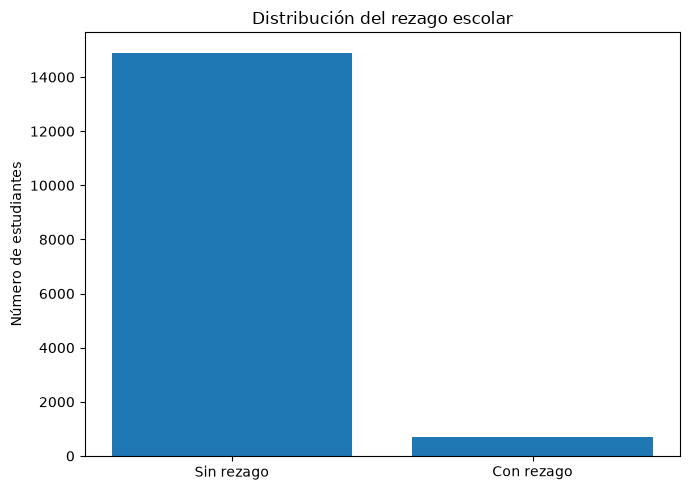

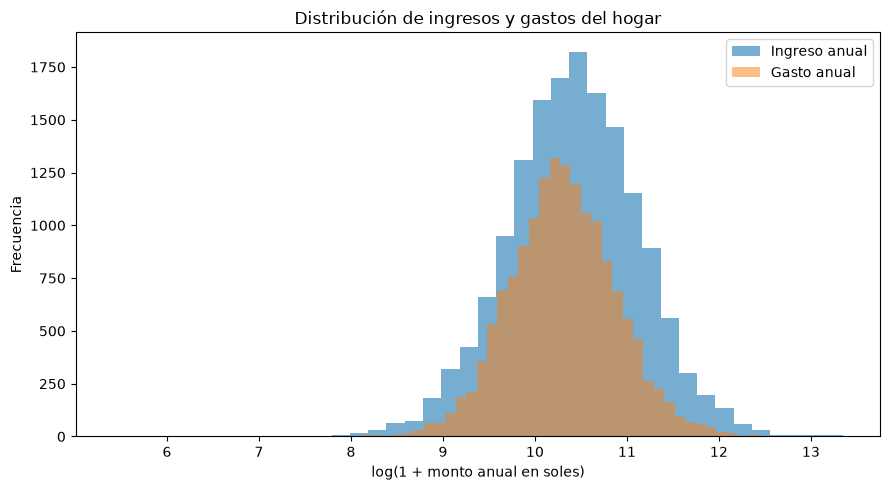

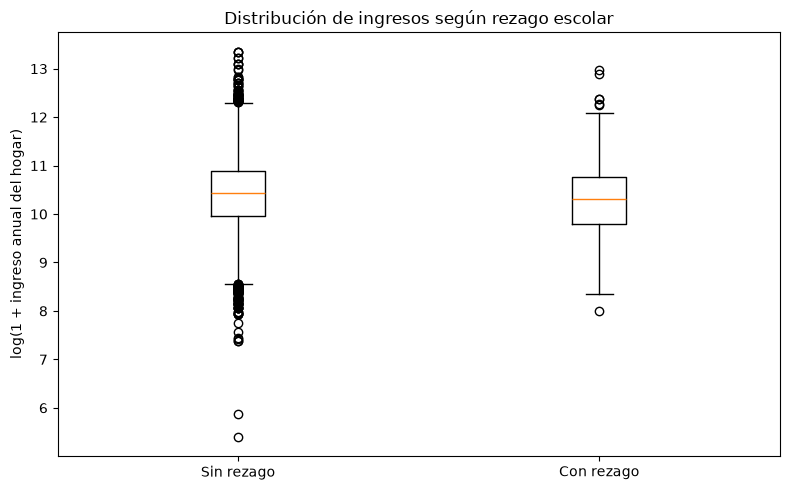

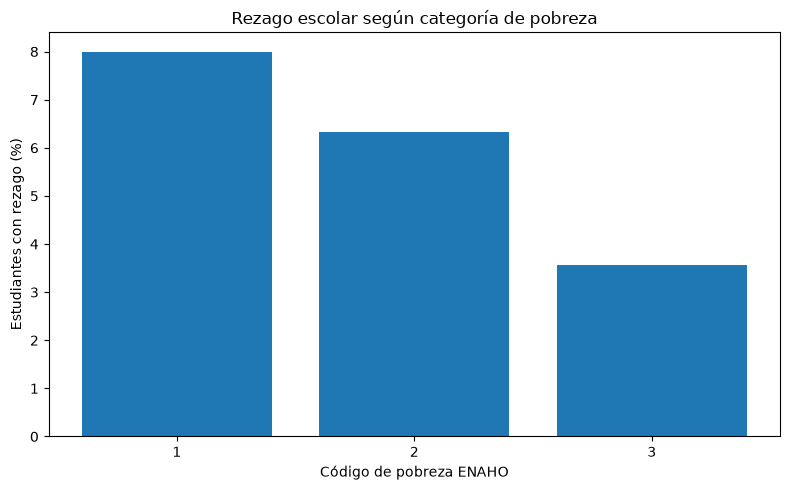

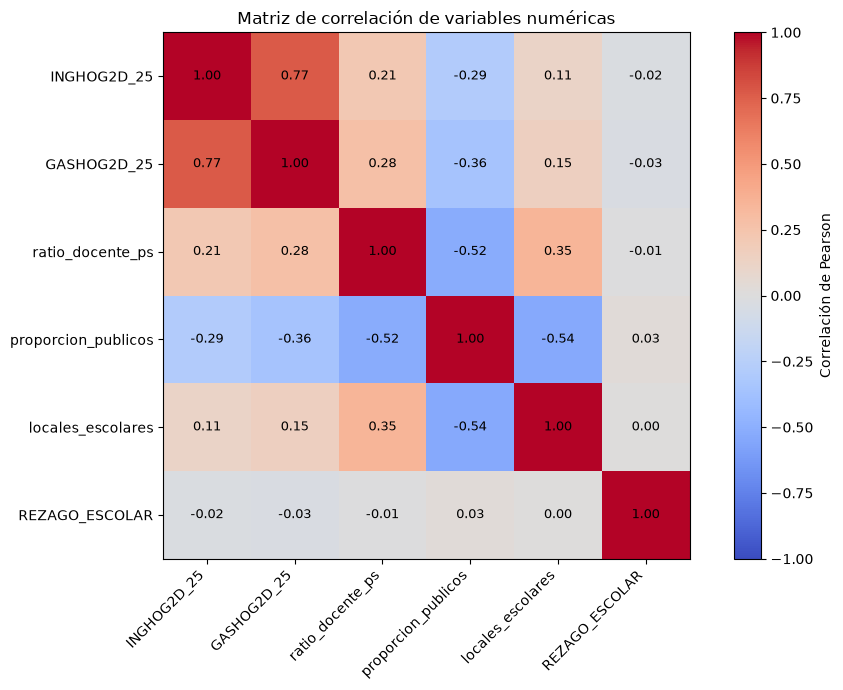

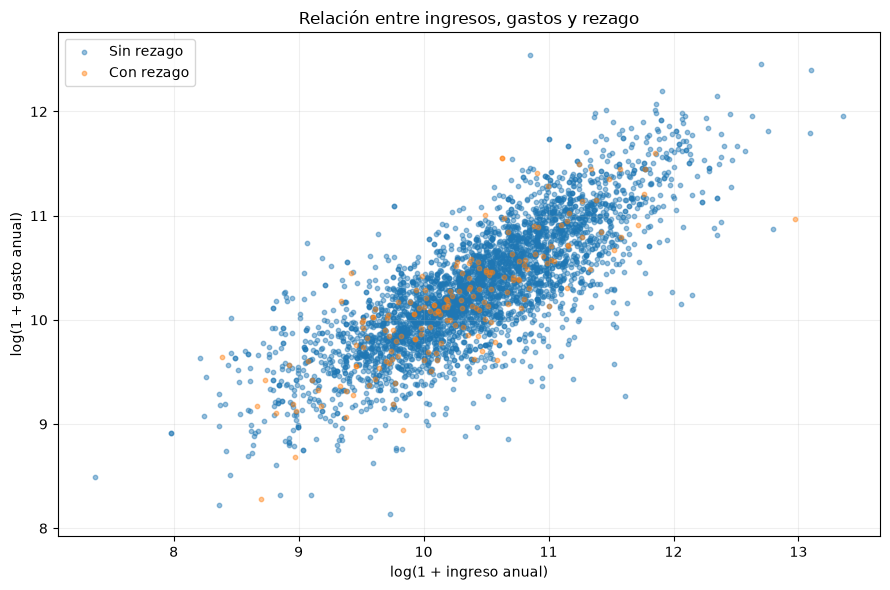


SEIS FIGURAS EDA GUARDADAS
Ubicación: D:\Proyectos Grandes Curos 2026-2\Examen de Inteligencia Artificial\Entrega_Final_IA\resultados\reproducido\figuras\eda
Datos originales y modelo definitivo intactos.


In [31]:

# ============================================================
# 8.2.2 VISUALIZACIONES DEL ANÁLISIS EXPLORATORIO
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# 1. Distribución de clases
fig, ax = plt.subplots(figsize=(7, 5))

ax.bar(
    ["Sin rezago", "Con rezago"],
    [
        int((df_eda["REZAGO_ESCOLAR"] == 0).sum()),
        int((df_eda["REZAGO_ESCOLAR"] == 1).sum())
    ]
)

ax.set_title("Distribución del rezago escolar")
ax.set_ylabel("Número de estudiantes")

fig.tight_layout()
fig.savefig(
    carpeta_eda_figuras / "eda_01_clases.png", dpi=200
)
plt.show()

# 2. Distribuciones económicas
fig, ax = plt.subplots(figsize=(9, 5))

ax.hist(
    np.log1p(df_eda["INGHOG2D_25"]),
    bins=40, alpha=0.6, label="Ingreso anual"
)

ax.hist(
    np.log1p(df_eda["GASHOG2D_25"]),
    bins=40, alpha=0.5, label="Gasto anual"
)

ax.set_title("Distribución de ingresos y gastos del hogar")
ax.set_xlabel("log(1 + monto anual en soles)")
ax.set_ylabel("Frecuencia")
ax.legend()

fig.tight_layout()
fig.savefig(
    carpeta_eda_figuras / "eda_02_economia.png", dpi=200
)
plt.show()

# 3. Diagrama de caja: ingreso y rezago
sin_rezago = np.log1p(
    df_eda.loc[
        df_eda["REZAGO_ESCOLAR"] == 0, "INGHOG2D_25"
    ]
)

con_rezago = np.log1p(
    df_eda.loc[
        df_eda["REZAGO_ESCOLAR"] == 1, "INGHOG2D_25"
    ]
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.boxplot(
    [sin_rezago, con_rezago],
    tick_labels=["Sin rezago", "Con rezago"]
)

ax.set_title("Distribución de ingresos según rezago escolar")
ax.set_ylabel("log(1 + ingreso anual del hogar)")

fig.tight_layout()
fig.savefig(
    carpeta_eda_figuras / "eda_03_ingreso_rezago.png",
    dpi=200
)
plt.show()

# 4. Porcentaje de rezago según categoría de pobreza
fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    tabla_pobreza_eda["POBREZA_25"].astype(str),
    tabla_pobreza_eda["Tasa_rezago"]
)

ax.set_title("Rezago escolar según categoría de pobreza")
ax.set_xlabel("Código de pobreza ENAHO")
ax.set_ylabel("Estudiantes con rezago (%)")

fig.tight_layout()
fig.savefig(
    carpeta_eda_figuras / "eda_04_pobreza_rezago.png",
    dpi=200
)
plt.show()

# 5. Mapa de calor de correlaciones
fig, ax = plt.subplots(figsize=(10, 7))

matriz = matriz_correlacion_eda.to_numpy()

imagen = ax.imshow(
    matriz, cmap="coolwarm",
    vmin=-1, vmax=1
)

nombres = matriz_correlacion_eda.columns.tolist()

ax.set_xticks(range(len(nombres)))
ax.set_yticks(range(len(nombres)))

ax.set_xticklabels(nombres, rotation=45, ha="right")
ax.set_yticklabels(nombres)

for i in range(len(nombres)):
    for j in range(len(nombres)):
        ax.text(
            j, i, f"{matriz[i, j]:.2f}",
            ha="center", va="center", fontsize=9
        )

fig.colorbar(imagen, ax=ax, label="Correlación de Pearson")
ax.set_title("Matriz de correlación de variables numéricas")

fig.tight_layout()
fig.savefig(
    carpeta_eda_figuras / "eda_05_correlacion.png",
    dpi=200, bbox_inches="tight"
)
plt.show()

# 6. Dispersión económica según rezago
muestra_eda = df_eda.sample(
    n=min(4000, len(df_eda)),
    random_state=42
)

fig, ax = plt.subplots(figsize=(9, 6))

for clase, nombre in [(0, "Sin rezago"), (1, "Con rezago")]:

    datos = muestra_eda[
        muestra_eda["REZAGO_ESCOLAR"] == clase
    ]

    ax.scatter(
        np.log1p(datos["INGHOG2D_25"]),
        np.log1p(datos["GASHOG2D_25"]),
        s=10, alpha=0.45, label=nombre
    )

ax.set_title("Relación entre ingresos, gastos y rezago")
ax.set_xlabel("log(1 + ingreso anual)")
ax.set_ylabel("log(1 + gasto anual)")
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(
    carpeta_eda_figuras / "eda_06_ingresos_gastos.png",
    dpi=200
)
plt.show()

print("\nSEIS FIGURAS EDA GUARDADAS")
print("Ubicación:", carpeta_eda_figuras)
print("Datos originales y modelo definitivo intactos.")


### 4.8. Códigos estructurales y consistencia de la etiqueta

En el diccionario panel 2025, P1121=1 indica electricidad y P1144=1 conexión a internet;
el código 0 se etiqueta como pase. Se conservan los códigos como categorías originales,
sin equiparar automáticamente 0 con una respuesta negativa confirmada. La interpretación
de disponibilidad requiere el contexto de las preguntas multirrespuesta 112 y 114.

El clustering refinado excluye esos indicadores para evitar particiones dominadas por
códigos estructurales; el clasificador conserva las categorías del experimento original.
P300A distingue lengua materna, incluidas categorías como no escucha/no habla y lengua
de señas, que no se recodifican como lenguas originarias. P306/P307 tienen códigos sí/no,
mientras los blancos educativos pueden corresponder a saltos. Las auditorías y la
sensibilidad del rezago se conservan; no se imputan grados ni etiquetas ausentes.


In [32]:
# ============================================================
# CÓDIGOS ESTRUCTURALES Y CONSISTENCIA DEL OBJETIVO
# ============================================================

import numpy as np
import pandas as pd

filas_codigos = []
for variable_codigo, positivos_codigo in [("P1121_25", "Electricidad declarada"), ("P1144_25", "Conexión a internet declarada")]:
    codigos_serie = df_modelo[variable_codigo].astype("string").str.strip().replace("", pd.NA)
    assert codigos_serie.dropna().isin(["0", "1"]).all()
    for valor_codigo, cantidad_codigo in codigos_serie.value_counts(dropna=False).items():
        significado_codigo = positivos_codigo if valor_codigo == "1" else "Pase / alternativa no marcada; no se recodifica como negativo confirmado"
        filas_codigos.append({"Variable": variable_codigo, "Código": valor_codigo,
                              "Registros": int(cantidad_codigo), "Descripción": significado_codigo})
tabla_codigos_estructurales = pd.DataFrame(filas_codigos)
display(tabla_codigos_estructurales)

edad_control = pd.to_numeric(df_modelo["P208A_25"], errors="raise")
normativa_control = pd.to_numeric(df_modelo["EDAD_NORMATIVA"], errors="raise")
objetivo_control = pd.to_numeric(df_modelo["REZAGO_ESCOLAR"], errors="raise").astype(int)
assert np.array_equal((edad_control >= normativa_control+2).astype(int).to_numpy(), objetivo_control.to_numpy())
assert edad_control.between(6,17).all()
assert df_modelo["P306_25"].astype("string").str.strip().eq("1").all()
display(pd.DataFrame({"Control": ["Registros válidos", "Rezago con umbral +2", "Sin rezago con umbral +2"],
                      "Cantidad": [len(df_modelo), int(objetivo_control.sum()), int(objetivo_control.eq(0).sum())]}))
print("Se conserva el umbral de dos años; la edad a la entrevista aproxima la referencia escolar al 31 de marzo.")


,Variable,Código,Registros,Descripción
0,P1121_25,1,18082,Electricidad declarada
1,P1121_25,0,1408,Pase / alternativa no marcada; no se recodific...
2,P1144_25,1,18652,Conexión a internet declarada
3,P1144_25,0,838,Pase / alternativa no marcada; no se recodific...


,Control,Cantidad
0,Registros válidos,19490
1,Rezago con umbral +2,852
2,Sin rezago con umbral +2,18638


Se conserva el umbral de dos años; la edad a la entrevista aproxima la referencia escolar al 31 de marzo.


### 4.9. Ponderación descriptiva del dominio de personas

El diccionario panel 2025 identifica FACPOB07 como factor anual de población del
módulo 200 y FACTOR07 como factor anual en Sumaria. Dado que cada fila representa
una persona, se utiliza FACPOB07 para una descripción complementaria de residentes
habituales matriculados y con grado válido dentro del entrenamiento. Se conserva
FACTOR07 del hogar para trazabilidad y se distingue de `class_weight` y `scale_pos_weight`.

Se recuperan únicamente nueve columnas del módulo 200. El criterio de residencia
sigue la [metodología de INEI](https://www.inei.gob.pe/media/MenuRecursivo/publicaciones_digitales/Est/Lib1244/Libro.pdf):
(P204=1 y P205=2) o (P204=2 y P206=1). Se requieren pesos personales positivos y finitos.
Las tasas son razones ponderadas de la submuestra de entrenamiento; la suma de sus
pesos no se interpreta como población nacional y no se estiman intervalos del diseño complejo.

La clasificación original se mantiene como comparación predictiva no ponderada de
la muestra. El complemento no convierte sus métricas en estimaciones poblacionales
ni demuestra equivalencia con una base anual independiente de 2025.


In [33]:
# ============================================================
# DESCRIPCIÓN COMPLEMENTARIA CON FACTOR ANUAL DE PERSONAS
# ============================================================

import numpy as np
import pandas as pd

campos_factor = {"AÑO_25", "CONGLOME_25", "VIVIENDA_25", "HOGAR_25",
                 "CODPERSO_25", "FACPOB07_25", "P204_25", "P205_25", "P206_25"}
ruta_factor_personas = next(
    (raiz / "data/raw").glob("factores_personas_2025.csv"), None
)
if ruta_factor_personas is None:
    raise FileNotFoundError("Se requiere el módulo 200 para auditar el factor de personas")
bloques_factor = []
for bloque_factor in pd.read_csv(
    ruta_factor_personas, encoding="utf-8-sig", dtype="string",
    usecols=lambda c: c.strip().upper() in campos_factor, chunksize=25000
):
    bloque_factor.columns = bloque_factor.columns.str.strip().str.upper()
    corte_factor = bloque_factor["AÑO_25"].str.strip().eq("2025").fillna(False)
    bloques_factor.append(bloque_factor.loc[corte_factor].copy())
factor_personas_2025 = pd.concat(bloques_factor, ignore_index=True)
for columna_factor in campos_factor:
    factor_personas_2025[columna_factor] = (
        factor_personas_2025[columna_factor].str.strip().replace("", pd.NA)
    )
llaves_factor = ["CONGLOME_25", "VIVIENDA_25", "HOGAR_25", "CODPERSO_25"]
assert not factor_personas_2025[llaves_factor].isna().any().any()
assert not factor_personas_2025.duplicated(llaves_factor).any()

# La extensión no modifica df_modelo, X, y, ni sus particiones.
auditoria_factor = df_modelo.merge(
    factor_personas_2025[llaves_factor + ["FACPOB07_25", "P204_25", "P205_25", "P206_25"]],
    on=llaves_factor, how="left", validate="one_to_one", indicator="_cruce_factor"
)
assert len(auditoria_factor) == len(df_modelo)
assert auditoria_factor["_cruce_factor"].eq("both").all()
auditoria_factor["RESIDENTE_HABITUAL"] = (
    (auditoria_factor["P204_25"].eq("1") & auditoria_factor["P205_25"].eq("2"))
    | (auditoria_factor["P204_25"].eq("2") & auditoria_factor["P206_25"].eq("1"))
).fillna(False)
auditoria_factor["PESO_PERSONA"] = pd.to_numeric(auditoria_factor["FACPOB07_25"], errors="coerce")
auditoria_factor["PESO_HOGAR_REFERENCIA"] = pd.to_numeric(auditoria_factor["FACTOR07_25"], errors="coerce")
auditoria_factor["REZAGO_ESCOLAR"] = pd.to_numeric(auditoria_factor["REZAGO_ESCOLAR"], errors="raise")
estrato_factor = pd.to_numeric(auditoria_factor["ESTRATO_25"], errors="coerce")
auditoria_factor["AREA_ENAHO"] = pd.Series(pd.NA, index=auditoria_factor.index, dtype="string")
auditoria_factor.loc[estrato_factor.between(1,5), "AREA_ENAHO"] = "Urbana"
auditoria_factor.loc[estrato_factor.between(6,8), "AREA_ENAHO"] = "Rural"
pesos_validos = np.isfinite(auditoria_factor["PESO_PERSONA"].astype(float)) & auditoria_factor["PESO_PERSONA"].gt(0)
auditoria_factor["ES_ENTRENAMIENTO"] = False
auditoria_factor.loc[train_idx, "ES_ENTRENAMIENTO"] = True
dominio_descriptivo = auditoria_factor.loc[
    auditoria_factor["RESIDENTE_HABITUAL"] & pesos_validos & auditoria_factor["ES_ENTRENAMIENTO"]
].copy()
assert len(dominio_descriptivo) > 0
resumen_factor = pd.DataFrame({
    "Control": ["Cohorte de clasificación", "Residentes habituales de la cohorte", "Entrenamiento residente con peso personal positivo"],
    "Registros": [len(auditoria_factor), int(auditoria_factor["RESIDENTE_HABITUAL"].sum()), len(dominio_descriptivo)]
})
filas_ponderadas = []
for area_factor in ["Total", "Urbana", "Rural"]:
    dominio_area = dominio_descriptivo if area_factor == "Total" else dominio_descriptivo.loc[dominio_descriptivo["AREA_ENAHO"].eq(area_factor)]
    if dominio_area.empty:
        continue
    w = dominio_area["PESO_PERSONA"].astype(float)
    z = dominio_area["REZAGO_ESCOLAR"].astype(float)
    filas_ponderadas.append({
        "Área": area_factor, "Registros": len(dominio_area), "Suma de pesos de la submuestra": float(w.sum()),
        "Rezago muestral (%)": float(z.mean()*100),
        "Rezago ponderado FACPOB07 (%)": float(np.average(z, weights=w)*100)
    })
tabla_descriptiva_ponderada = pd.DataFrame(filas_ponderadas)
display(resumen_factor)
display(tabla_descriptiva_ponderada.round(4))
print("FACTOR07 se conserva como referencia del hogar; FACPOB07 pondera esta descripción de personas.")
print("Los pesos de clase y las métricas predictivas originales permanecen sin modificación.")


,Control,Registros
0,Cohorte de clasificación,19490
1,Residentes habituales de la cohorte,19286
2,Entrenamiento residente con peso personal posi...,15448


,Área,Registros,Suma de pesos de la submuestra,Rezago muestral (%),Rezago ponderado FACPOB07 (%)
0,Total,15448,4.891486e+06,4.4731,4.1602
1,Urbana,9828,3.876795e+06,3.8970,3.8890
2,Rural,5620,1.014691e+06,5.4804,5.1964


FACTOR07 se conserva como referencia del hogar; FACPOB07 pondera esta descripción de personas.
Los pesos de clase y las métricas predictivas originales permanecen sin modificación.


### 4.10. Contexto educativo complementario por distrito y área

AREA_CENSO=1/2 y DAREACENSO permiten distinguir Urbana/Rural en ESCALE.
El diccionario ENAHO define ESTRATO 1–5 para centros urbanos de al menos 2 000
habitantes y 6–8 para los estratos rurales. La correspondencia se verifica sin
imputar área a códigos desconocidos.

Se agregan servicios activos de primaria (B0) y secundaria (F0) por CODGEO y área,
comprobando unicidad de COD_MOD–ANEXO. Se incluyen alumnos, docentes, secciones,
locales únicos, proporción de servicios públicos y coordenadas válidas. El ratio se
calcula como suma de alumnos / suma de docentes; los denominadores cero quedan ausentes.
El cruce conserva una fila por persona y expone su cobertura sin sustituir indicadores
del experimento original. El área de residencia y el área del servicio educativo
describen contexto; no identifican la escuela individual a la que asiste el estudiante.


In [34]:
# ============================================================
# ESCALE COMPLEMENTARIO POR DISTRITO Y ÁREA URBANA/RURAL
# ============================================================

import numpy as np
import pandas as pd
from dbfread import DBF

campos_area = ["CODGEO", "COD_MOD", "ANEXO", "CODLOCAL", "NIV_MOD", "ESTADO",
               "AREA_CENSO", "DAREACENSO", "GESTION", "TALUM", "TDOC", "TSEC", "NLAT_IE", "NLONG_IE"]
padron_area_complementario = pd.DataFrame.from_records(
    ({c: r.get(c) for c in campos_area}
     for r in DBF(str(raiz / "data/interim/Padron.dbf"), encoding="latin1", load=False)),
    columns=campos_area
)
for c_area in ["CODGEO", "COD_MOD", "ANEXO", "CODLOCAL", "NIV_MOD", "ESTADO", "AREA_CENSO", "GESTION"]:
    padron_area_complementario[c_area] = padron_area_complementario[c_area].astype("string").str.strip().replace("", pd.NA)
seleccion_area = padron_area_complementario.loc[
    padron_area_complementario["ESTADO"].eq("1")
    & padron_area_complementario["NIV_MOD"].isin(["B0", "F0"])
    & padron_area_complementario["CODGEO"].str.fullmatch(r"\d{6}", na=False)
].copy()
assert not seleccion_area.duplicated(["COD_MOD", "ANEXO"]).any()
seleccion_area["AREA_ESCALE"] = seleccion_area["AREA_CENSO"].map({"1": "Urbana", "2": "Rural"}).astype("string")
assert seleccion_area["AREA_ESCALE"].notna().all()
assert seleccion_area["AREA_ESCALE"].str.casefold().eq(
    seleccion_area["DAREACENSO"].astype("string").str.strip().str.casefold()
).all()
for c_area in ["TALUM", "TDOC", "TSEC", "NLAT_IE", "NLONG_IE"]:
    seleccion_area[c_area] = pd.to_numeric(seleccion_area[c_area], errors="coerce")
for c_area in ["TALUM", "TDOC", "TSEC"]:
    assert seleccion_area[c_area].notna().all()
    assert seleccion_area[c_area].ge(0).all()
coordenadas_area_validas = (
    seleccion_area["NLAT_IE"].between(-19,0)
    & seleccion_area["NLONG_IE"].between(-82,-68)
)
seleccion_area.loc[~coordenadas_area_validas, ["NLAT_IE", "NLONG_IE"]] = np.nan
assert seleccion_area["GESTION"].isin(["1", "2", "3"]).all()
seleccion_area["PUBLICO_AREA"] = seleccion_area["GESTION"].isin(["1", "2"]).astype(int)
escale_distrito_area_complementario = seleccion_area.groupby(
    ["CODGEO", "AREA_ESCALE"], as_index=False
).agg(
    servicios_ps_area=("COD_MOD", "size"), locales_ps_area=("CODLOCAL", "nunique"),
    alumnos_ps_area=("TALUM", "sum"), docentes_ps_area=("TDOC", "sum"),
    secciones_ps_area=("TSEC", "sum"), publicos_ps_area=("PUBLICO_AREA", "sum"),
    latitud_media_ps_area=("NLAT_IE", "mean"), longitud_media_ps_area=("NLONG_IE", "mean")
)
escale_distrito_area_complementario["ratio_docente_ps_area"] = (
    escale_distrito_area_complementario["alumnos_ps_area"]
    / escale_distrito_area_complementario["docentes_ps_area"].replace(0,np.nan)
)
escale_distrito_area_complementario["proporcion_publicos_ps_area"] = (
    escale_distrito_area_complementario["publicos_ps_area"]
    / escale_distrito_area_complementario["servicios_ps_area"]
)
modelo_area_complementario = df_modelo.copy()
estrato_area = pd.to_numeric(modelo_area_complementario["ESTRATO_25"], errors="coerce")
modelo_area_complementario["AREA_ENAHO"] = pd.Series(pd.NA, index=modelo_area_complementario.index, dtype="string")
modelo_area_complementario.loc[estrato_area.between(1,5), "AREA_ENAHO"] = "Urbana"
modelo_area_complementario.loc[estrato_area.between(6,8), "AREA_ENAHO"] = "Rural"
assert modelo_area_complementario["AREA_ENAHO"].notna().all()
modelo_area_complementario = modelo_area_complementario.merge(
    escale_distrito_area_complementario,
    left_on=["UBIGEO_25_P200", "AREA_ENAHO"], right_on=["CODGEO", "AREA_ESCALE"],
    how="left", validate="many_to_one", suffixes=("", "_AREA"), indicator="_cruce_escale_area"
)
assert len(modelo_area_complementario) == len(df_modelo)
tabla_cobertura_area = modelo_area_complementario.groupby(
    "AREA_ENAHO", as_index=False
).agg(
    Registros=("AREA_ENAHO", "size"),
    Coincidencias=("_cruce_escale_area", lambda s: int(s.eq("both").sum())),
    Ratio_disponible=("ratio_docente_ps_area", "count")
)
display(tabla_cobertura_area)
display(escale_distrito_area_complementario.head(10))
print("La unión conserva una fila por persona y no sustituye los predictores del experimento original.")


,AREA_ENAHO,Registros,Coincidencias,Ratio_disponible
0,Rural,7012,6961,6961
1,Urbana,12478,12152,12152


,CODGEO,AREA_ESCALE,servicios_ps_area,locales_ps_area,alumnos_ps_area,docentes_ps_area,secciones_ps_area,publicos_ps_area,latitud_media_ps_area,longitud_media_ps_area,ratio_docente_ps_area,proporcion_publicos_ps_area
0,010101,Rural,5,5,48,6,20,5,-6.255944,-77.858378,8.000000,1.000000
1,010101,Urbana,24,15,8276,482,322,20,-6.227534,-77.869223,17.170124,0.833333
2,010102,Rural,3,3,10,3,7,3,-5.997633,-77.732124,3.333333,1.000000
3,010103,Rural,12,11,298,32,54,12,-6.812315,-77.971735,9.312500,1.000000
4,010104,Rural,4,3,102,14,20,4,-6.264025,-77.704250,7.285714,1.000000
5,010105,Rural,6,6,47,8,27,6,-6.086107,-77.777661,5.875000,1.000000
6,010106,Rural,16,13,394,48,76,16,-6.929089,-77.780280,8.208333,1.000000
7,010107,Rural,4,3,94,11,17,4,-6.152325,-77.655800,8.545455,1.000000
8,010108,Rural,1,1,17,2,5,1,-6.174300,-77.863600,8.500000,1.000000
9,010109,Rural,16,14,695,64,85,16,-6.507543,-77.744175,10.859375,1.000000


La unión conserva una fila por persona y no sustituye los predictores del experimento original.


### 4.11. Lectura de los análisis complementarios

La descripción ponderada incluye 15 448 residentes habituales del entrenamiento con
peso personal válido. En ese mismo dominio, el rezago muestral es 4.4731 % y la razón
ponderada es 4.1602 %. La diferencia no es una prueba de significancia ni una corrección
de las métricas predictivas, que corresponden a la cohorte original de entrenamiento.

La unión distrito–área encuentra correspondencia para 19 113 de las 19 490 personas:
quedan 51 casos rurales y 326 urbanos sin equivalente en el agregado seleccionado.
Se mantienen identificados como faltantes del complemento; no se rellenan con un
indicador distrital ni se sustituyen silenciosamente los predictores originales.



## 5. Clasificación supervisada

### 5.1. Regresión Logística: comparación con y sin balanceo

Se entrena un modelo de Regresión Logística como línea base para predecir el rezago escolar.

Se comparan dos configuraciones: sin ponderación de clases y con ponderación balanceada.

La evaluación utiliza validación cruzada GroupKFold de tres particiones sobre los datos de entrenamiento, manteniendo separados los conglomerados.

El preprocesamiento se incorpora dentro de un Pipeline para evitar fuga de datos durante la imputación, codificación y normalización.

Se comparan F1 macro, F1 de la clase minoritaria, recall, Average Precision y ROC-AUC. El conjunto de prueba final permanece reservado.


In [35]:

# ============================================================
# 4.3 REGRESIÓN LOGÍSTICA NORMAL VS. BALANCEADA
# ============================================================

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.metrics import make_scorer, f1_score, recall_score

# 1. Preparar las variables numéricas
# Imputamos con la mediana y después normalizamos
procesamiento_numerico = Pipeline([
    ("imputador", SimpleImputer(strategy="median")),
    ("escalador", StandardScaler())
])

# 2. Preparar las variables categóricas
# Imputamos la moda y aplicamos One-Hot Encoding
procesamiento_categorico = Pipeline([
    ("imputador", SimpleImputer(strategy="most_frequent")),
    ("codificador", OneHotEncoder(handle_unknown="ignore"))
])

# 3. Integrar ambos tratamientos en un preprocesador
# Se ajustará por separado dentro de cada fold
preprocesador = ColumnTransformer([
    ("numericas", procesamiento_numerico, numericas),
    ("categoricas", procesamiento_categorico, categoricas)
])

# 4. Obtener los conglomerados del entrenamiento
grupos_cv = grupos.iloc[train_idx]

# 5. Crear las mismas tres particiones para ambos modelos
validacion = GroupKFold(n_splits=3)

particiones = list(
    validacion.split(
        X_train,
        y_train,
        groups=grupos_cv
    )
)

print("VALIDACIÓN CRUZADA POR CONGLOMERADO")

# Confirmar que no existen grupos compartidos
for numero, (idx_ent, idx_val) in enumerate(particiones, 1):

    grupos_ent = set(grupos_cv.iloc[idx_ent])
    grupos_val = set(grupos_cv.iloc[idx_val])

    assert grupos_ent.isdisjoint(grupos_val)

    print(
        f"Fold {numero}: "
        f"{len(idx_ent)} entrenamiento, "
        f"{len(idx_val)} validación, "
        f"{int(y_train.iloc[idx_val].sum())} positivos"
    )

# 6. Definir métricas
metricas = {
    "f1_macro": "f1_macro",
    "f1_rezago": make_scorer(
        f1_score,
        pos_label=1,
        zero_division=0
    ),
    "recall_rezago": make_scorer(
        recall_score,
        pos_label=1,
        zero_division=0
    ),
    "average_precision": "average_precision",
    "roc_auc": "roc_auc"
}

# 7. Comparar las dos configuraciones
configuraciones = {
    "Regresión Logística Normal": None,
    "Regresión Logística Balanceada": "balanced"
}

resultados_logistica = []

for nombre, peso in configuraciones.items():

    # Crear un modelo independiente con su propio Pipeline
    modelo = Pipeline([
        ("preprocesamiento", preprocesador),
        ("clasificador", LogisticRegression(
            class_weight=peso,
            max_iter=1500,
            random_state=42
        ))
    ])

    print(f"\nEntrenando: {nombre}")

    # Evaluar únicamente con validación cruzada
    evaluacion = cross_validate(
        modelo,
        X_train,
        y_train,
        cv=particiones,
        scoring=metricas,
        n_jobs=1,
        error_score="raise"
    )

    # Almacenar el promedio de las tres rondas
    fila = {"Modelo": nombre}

    for metrica in metricas:
        valores = evaluacion[f"test_{metrica}"]

        fila[metrica] = round(
            float(np.mean(valores)), 4
        )

    resultados_logistica.append(fila)

# 8. Mostrar comparación
tabla_logistica = pd.DataFrame(resultados_logistica)

print("\nRESULTADOS DE VALIDACIÓN CRUZADA")
display(tabla_logistica)

print("\nEl conjunto de prueba final NO se ha utilizado.")


VALIDACIÓN CRUZADA POR CONGLOMERADO
Fold 1: 10406 entrenamiento, 5204 validación, 222 positivos
Fold 2: 10407 entrenamiento, 5203 validación, 261 positivos
Fold 3: 10407 entrenamiento, 5203 validación, 218 positivos

Entrenando: Regresión Logística Normal



Entrenando: Regresión Logística Balanceada



RESULTADOS DE VALIDACIÓN CRUZADA


,Modelo,f1_macro,f1_rezago,recall_rezago,average_precision,roc_auc
0,Regresión Logística Normal,0.4885,0.0000,0.0000,0.0874,0.6351
1,Regresión Logística Balanceada,0.4405,0.1166,0.5461,0.0886,0.6340



El conjunto de prueba final NO se ha utilizado.



### 5.2. Random Forest: comparación con y sin balanceo

Se compara Random Forest sin ponderación y con ponderación balanceada de clases.

Los valores económicos extremos se conservan porque el diagnóstico no demuestra que sean errores. La variable REZAGO_ESCOLAR mantiene el umbral de dos o más años, conforme al criterio de atraso escolar de ESCALE, aunque la edad de ENAHO constituye una aproximación a la edad de referencia oficial.

Se utiliza GroupKFold de tres particiones, las mismas que en Regresión Logística. El preprocesamiento se ajusta dentro de cada fold y los datos de prueba final permanecen reservados.


In [36]:

# ============================================================
# 4.4 RANDOM FOREST NORMAL VS. BALANCEADO
# ============================================================

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate
from sklearn.base import clone

# 1. Configuraciones del experimento
configuraciones_rf = {
    "Random Forest Normal": None,
    "Random Forest Balanceado": "balanced"
}

resultados_rf = []

# 2. Entrenar y validar ambas configuraciones
for nombre, peso in configuraciones_rf.items():

    print(f"\nEntrenando: {nombre}")

    # Crear un bosque de 120 árboles
    bosque = RandomForestClassifier(
        n_estimators=120,
        max_depth=12,
        min_samples_leaf=4,
        class_weight=peso,
        random_state=42,
        n_jobs=-1
    )

    # Preprocesamiento dentro de cada fold
    modelo_rf = Pipeline([
        ("preprocesamiento", clone(preprocesador)),
        ("clasificador", bosque)
    ])

    # Usar las mismas particiones de Regresión Logística
    evaluacion = cross_validate(
        modelo_rf,
        X_train,
        y_train,
        cv=particiones,
        scoring=metricas,
        n_jobs=1,
        error_score="raise"
    )

    # Promedio de las tres rondas
    fila = {"Modelo": nombre}

    for metrica in metricas:
        valores = evaluacion[f"test_{metrica}"]

        fila[metrica] = round(
            float(np.mean(valores)), 4
        )

    resultados_rf.append(fila)

# 3. Mostrar resultados de Random Forest
tabla_rf = pd.DataFrame(resultados_rf)

print("\nRESULTADOS DE RANDOM FOREST")
display(tabla_rf)

# 4. Comparar contra Regresión Logística
comparacion_actual = pd.concat(
    [tabla_logistica, tabla_rf],
    ignore_index=True
)

print("\nCOMPARACIÓN DE CUATRO CONFIGURACIONES")
display(comparacion_actual)

print("\nEl conjunto de prueba final NO se ha utilizado.")



Entrenando: Random Forest Normal



Entrenando: Random Forest Balanceado



RESULTADOS DE RANDOM FOREST


,Modelo,f1_macro,f1_rezago,recall_rezago,average_precision,roc_auc
0,Random Forest Normal,0.4885,0.0000,0.0000,0.0737,0.6273
1,Random Forest Balanceado,0.5158,0.1155,0.2232,0.0719,0.6070



COMPARACIÓN DE CUATRO CONFIGURACIONES


,Modelo,f1_macro,f1_rezago,recall_rezago,average_precision,roc_auc
0,Regresión Logística Normal,0.4885,0.0000,0.0000,0.0874,0.6351
1,Regresión Logística Balanceada,0.4405,0.1166,0.5461,0.0886,0.6340
2,Random Forest Normal,0.4885,0.0000,0.0000,0.0737,0.6273
3,Random Forest Balanceado,0.5158,0.1155,0.2232,0.0719,0.6070



El conjunto de prueba final NO se ha utilizado.



### 5.3. Regresión Logística con sobremuestreo aleatorio

Se realiza un tercer experimento de Regresión Logística mediante Random Oversampling para analizar el efecto de equilibrar las cantidades de estudiantes con y sin rezago escolar.

En cada partición GroupKFold se duplican aleatoriamente, con reemplazo, observaciones de la clase minoritaria hasta igualar el número de observaciones de la clase mayoritaria.

El sobremuestreo se aplica exclusivamente a los datos de entrenamiento de cada fold. Los conjuntos de validación y prueba mantienen su distribución original, evitando fuga de datos.

Los resultados se comparan con la Regresión Logística normal y con ponderación de clases.


In [37]:

# ============================================================
# 4.5.1 SOBREMUESTREO ALEATORIO DE LA CLASE MINORITARIA
# ============================================================

import numpy as np
import pandas as pd

def aplicar_oversampling(X_fold, y_fold, semilla=42):

    # Identificar índices de estudiantes sin y con rezago
    etiquetas = y_fold.to_numpy()

    indices_negativos = np.flatnonzero(etiquetas == 0)
    indices_positivos = np.flatnonzero(etiquetas == 1)

    assert len(indices_positivos) > 0
    assert len(indices_negativos) >= len(indices_positivos)

    # Calcular cuántos ejemplos positivos adicionales faltan
    faltantes = (
        len(indices_negativos) - len(indices_positivos)
    )

    # Repetir aleatoriamente ejemplos de la clase minoritaria
    generador = np.random.default_rng(semilla)

    indices_extra = generador.choice(
        indices_positivos,
        size=faltantes,
        replace=True
    )

    # Conservar los originales y añadir las repeticiones
    indices_finales = np.concatenate([
        np.arange(len(y_fold)),
        indices_extra
    ])

    generador.shuffle(indices_finales)

    return (
        X_fold.iloc[indices_finales].copy(),
        y_fold.iloc[indices_finales].copy()
    )


# Demostración utilizando solo el entrenamiento del Fold 1
indices_entrenamiento, indices_validacion = particiones[0]

X_fold = X_train.iloc[indices_entrenamiento]
y_fold = y_train.iloc[indices_entrenamiento]

X_balanceado, y_balanceado = aplicar_oversampling(
    X_fold,
    y_fold,
    semilla=42
)

print("DISTRIBUCIÓN ORIGINAL DEL FOLD 1")
display(y_fold.value_counts().sort_index().to_frame("Cantidad"))

print("\nDISTRIBUCIÓN BALANCEADA DEL FOLD 1")
display(
    y_balanceado.value_counts()
    .sort_index()
    .to_frame("Cantidad")
)

assert y_balanceado.value_counts().nunique() == 1

print("\nBalanceo comprobado correctamente.")
print("Validación y prueba permanecen intactas.")


DISTRIBUCIÓN ORIGINAL DEL FOLD 1


,Cantidad
REZAGO_ESCOLAR,
0,9927
1,479



DISTRIBUCIÓN BALANCEADA DEL FOLD 1


,Cantidad
REZAGO_ESCOLAR,
0,9927
1,9927



Balanceo comprobado correctamente.
Validación y prueba permanecen intactas.



### 5.3.1. Entrenamiento y validación cruzada con Random Oversampling

Se entrena una Regresión Logística utilizando sobremuestreo aleatorio de la clase minoritaria en cada partición de GroupKFold.

El sobremuestreo se aplica exclusivamente a los datos de entrenamiento de cada fold, mientras que los registros de validación conservan su distribución original.

Se calculan F1 macro, F1 de rezago, recall, Average Precision y ROC-AUC. Posteriormente se comparan estos resultados con la Regresión Logística normal y la Regresión Logística con ponderación balanceada.

El conjunto de prueba final permanece reservado.


In [38]:

# ============================================================
# 4.5.2 REGRESIÓN LOGÍSTICA CON OVERSAMPLING Y GROUPKFOLD
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score,
    recall_score,
    average_precision_score,
    roc_auc_score
)

resultados_ros = []

# 1. Recorrer las tres particiones GroupKFold
for numero, (idx_ent, idx_val) in enumerate(particiones, 1):

    print(f"\nENTRENAMIENTO DEL FOLD {numero}")

    # Separar los registros correspondientes al fold
    X_ent = X_train.iloc[idx_ent]
    y_ent = y_train.iloc[idx_ent]

    X_val = X_train.iloc[idx_val]
    y_val = y_train.iloc[idx_val]

    # Verificar que no compartan conglomerados
    grupos_ent = set(grupos_cv.iloc[idx_ent])
    grupos_val = set(grupos_cv.iloc[idx_val])

    assert grupos_ent.isdisjoint(grupos_val)

    # 2. Balancear únicamente los datos de entrenamiento
    X_ros, y_ros = aplicar_oversampling(
        X_ent,
        y_ent,
        semilla=42 + numero
    )

    print("Antes:", y_ent.value_counts().to_dict())
    print("Después:", y_ros.value_counts().to_dict())

    # 3. Crear el Pipeline de Regresión Logística
    modelo_ros = Pipeline([
        ("preprocesamiento", clone(preprocesador)),
        ("clasificador", LogisticRegression(
            class_weight=None,
            max_iter=1500,
            random_state=42
        ))
    ])

    # 4. Entrenar con los datos sobremuestreados
    modelo_ros.fit(X_ros, y_ros)

    # 5. Evaluar con datos de validación originales
    predicciones = modelo_ros.predict(X_val)
    probabilidades = modelo_ros.predict_proba(X_val)[:, 1]

    # 6. Calcular métricas
    resultados_ros.append({
        "Fold": numero,
        "f1_macro": f1_score(
            y_val, predicciones,
            average="macro",
            zero_division=0
        ),
        "f1_rezago": f1_score(
            y_val, predicciones,
            pos_label=1,
            zero_division=0
        ),
        "recall_rezago": recall_score(
            y_val, predicciones,
            pos_label=1,
            zero_division=0
        ),
        "average_precision": average_precision_score(
            y_val, probabilidades
        ),
        "roc_auc": roc_auc_score(
            y_val, probabilidades
        )
    })

# 7. Mostrar resultados individuales
tabla_folds_ros = pd.DataFrame(resultados_ros)

print("\nRESULTADOS POR FOLD")
display(tabla_folds_ros.round(4))

# 8. Calcular los promedios
columnas_metricas = [
    "f1_macro",
    "f1_rezago",
    "recall_rezago",
    "average_precision",
    "roc_auc"
]

promedios = tabla_folds_ros[columnas_metricas].mean()

tabla_ros = pd.DataFrame([{
    "Modelo": "Regresión Logística Oversampling",
    **{
        columna: round(float(promedios[columna]), 4)
        for columna in columnas_metricas
    }
}])

# 9. Comparar las tres configuraciones
comparacion_logistica = pd.concat(
    [tabla_logistica, tabla_ros],
    ignore_index=True
)

print("\nCOMPARACIÓN DE REGRESIÓN LOGÍSTICA")
display(comparacion_logistica)

print("\nLa prueba final NO se ha utilizado.")



ENTRENAMIENTO DEL FOLD 1
Antes: {0: 9927, 1: 479}
Después: {1: 9927, 0: 9927}



ENTRENAMIENTO DEL FOLD 2
Antes: {0: 9967, 1: 440}
Después: {1: 9967, 0: 9967}



ENTRENAMIENTO DEL FOLD 3
Antes: {0: 9924, 1: 483}
Después: {0: 9924, 1: 9924}



RESULTADOS POR FOLD


,Fold,f1_macro,f1_rezago,recall_rezago,average_precision,roc_auc
0,1,0.4454,0.1073,0.4910,0.0852,0.6217
1,2,0.4491,0.1321,0.5594,0.1018,0.6464
2,3,0.4270,0.1058,0.5550,0.0806,0.6307



COMPARACIÓN DE REGRESIÓN LOGÍSTICA


,Modelo,f1_macro,f1_rezago,recall_rezago,average_precision,roc_auc
0,Regresión Logística Normal,0.4885,0.0000,0.0000,0.0874,0.6351
1,Regresión Logística Balanceada,0.4405,0.1166,0.5461,0.0886,0.6340
2,Regresión Logística Oversampling,0.4405,0.1151,0.5351,0.0892,0.6329



La prueba final NO se ha utilizado.



### 5.4. Random Forest con sobremuestreo aleatorio

Se evalúa Random Forest utilizando Random Oversampling para equilibrar las clases durante el entrenamiento.

En cada partición GroupKFold, el sobremuestreo se aplica únicamente a los registros de entrenamiento, manteniendo intacta la distribución de los registros de validación.

Se conservan los mismos hiperparámetros utilizados en Random Forest normal y balanceado, con el objetivo de estudiar exclusivamente el efecto del método de tratamiento del desbalance.

Se comparan F1 macro, F1 de rezago, recall, Average Precision y ROC-AUC. El conjunto de prueba final permanece reservado.


In [39]:

# ============================================================
# 4.6 RANDOM FOREST CON OVERSAMPLING Y GROUPKFOLD
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    f1_score,
    recall_score,
    average_precision_score,
    roc_auc_score
)

# 1. Almacenar resultados por partición
resultados_rf_ros = []

# 2. Ejecutar los tres folds
for numero, (idx_ent, idx_val) in enumerate(particiones, 1):

    print(f"\nENTRENAMIENTO RANDOM FOREST - FOLD {numero}")

    # Separar datos del fold
    X_ent = X_train.iloc[idx_ent]
    y_ent = y_train.iloc[idx_ent]

    X_val = X_train.iloc[idx_val]
    y_val = y_train.iloc[idx_val]

    # Verificar separación de conglomerados
    grupos_ent = set(grupos_cv.iloc[idx_ent])
    grupos_val = set(grupos_cv.iloc[idx_val])

    assert grupos_ent.isdisjoint(grupos_val)

    # 3. Balancear solo los registros de entrenamiento
    X_ros, y_ros = aplicar_oversampling(
        X_ent,
        y_ent,
        semilla=42 + numero
    )

    print("Antes:", y_ent.value_counts().to_dict())
    print("Después:", y_ros.value_counts().to_dict())

    # 4. Mantener los parámetros del Random Forest anterior
    modelo_rf_ros = Pipeline([
        ("preprocesamiento", clone(preprocesador)),
        ("clasificador", RandomForestClassifier(
            n_estimators=120,
            max_depth=12,
            min_samples_leaf=4,
            class_weight=None,
            random_state=42,
            n_jobs=-1
        ))
    ])

    # 5. Entrenar con los registros balanceados
    modelo_rf_ros.fit(X_ros, y_ros)

    # 6. Evaluar con los registros originales de validación
    predicciones = modelo_rf_ros.predict(X_val)
    probabilidades = modelo_rf_ros.predict_proba(X_val)[:, 1]

    # 7. Registrar las métricas
    resultados_rf_ros.append({
        "Fold": numero,
        "f1_macro": f1_score(
            y_val, predicciones,
            average="macro", zero_division=0
        ),
        "f1_rezago": f1_score(
            y_val, predicciones,
            pos_label=1, zero_division=0
        ),
        "recall_rezago": recall_score(
            y_val, predicciones,
            pos_label=1, zero_division=0
        ),
        "average_precision": average_precision_score(
            y_val, probabilidades
        ),
        "roc_auc": roc_auc_score(
            y_val, probabilidades
        )
    })

# 8. Mostrar los resultados de los tres folds
tabla_folds_rf_ros = pd.DataFrame(resultados_rf_ros)

print("\nRESULTADOS POR FOLD")
display(tabla_folds_rf_ros.round(4))

# 9. Calcular promedios
columnas_metricas = [
    "f1_macro",
    "f1_rezago",
    "recall_rezago",
    "average_precision",
    "roc_auc"
]

promedios_rf_ros = tabla_folds_rf_ros[columnas_metricas].mean()

tabla_rf_ros = pd.DataFrame([{
    "Modelo": "Random Forest Oversampling",
    **{
        columna: round(float(promedios_rf_ros[columna]), 4)
        for columna in columnas_metricas
    }
}])

# 10. Comparar las tres versiones de Random Forest
comparacion_rf = pd.concat(
    [tabla_rf, tabla_rf_ros],
    ignore_index=True
)

print("\nCOMPARACIÓN DE RANDOM FOREST")
display(comparacion_rf)

# 11. Comparar todos los experimentos supervisados
comparacion_general = pd.concat(
    [tabla_logistica, tabla_ros, tabla_rf, tabla_rf_ros],
    ignore_index=True
)

print("\nCOMPARACIÓN GENERAL DE MODELOS")
display(comparacion_general)

print("\nEl conjunto de prueba final NO se ha utilizado.")



ENTRENAMIENTO RANDOM FOREST - FOLD 1
Antes: {0: 9927, 1: 479}
Después: {1: 9927, 0: 9927}



ENTRENAMIENTO RANDOM FOREST - FOLD 2
Antes: {0: 9967, 1: 440}
Después: {1: 9967, 0: 9967}



ENTRENAMIENTO RANDOM FOREST - FOLD 3
Antes: {0: 9924, 1: 483}
Después: {0: 9924, 1: 9924}



RESULTADOS POR FOLD


,Fold,f1_macro,f1_rezago,recall_rezago,average_precision,roc_auc
0,1,0.5089,0.0871,0.1441,0.0636,0.5734
1,2,0.5267,0.1239,0.1839,0.0731,0.5916
2,3,0.5156,0.1012,0.1743,0.0635,0.5902



COMPARACIÓN DE RANDOM FOREST


,Modelo,f1_macro,f1_rezago,recall_rezago,average_precision,roc_auc
0,Random Forest Normal,0.4885,0.0000,0.0000,0.0737,0.6273
1,Random Forest Balanceado,0.5158,0.1155,0.2232,0.0719,0.6070
2,Random Forest Oversampling,0.5171,0.1040,0.1675,0.0667,0.5851



COMPARACIÓN GENERAL DE MODELOS


,Modelo,f1_macro,f1_rezago,recall_rezago,average_precision,roc_auc
0,Regresión Logística Normal,0.4885,0.0000,0.0000,0.0874,0.6351
1,Regresión Logística Balanceada,0.4405,0.1166,0.5461,0.0886,0.6340
2,Regresión Logística Oversampling,0.4405,0.1151,0.5351,0.0892,0.6329
3,Random Forest Normal,0.4885,0.0000,0.0000,0.0737,0.6273
4,Random Forest Balanceado,0.5158,0.1155,0.2232,0.0719,0.6070
5,Random Forest Oversampling,0.5171,0.1040,0.1675,0.0667,0.5851



El conjunto de prueba final NO se ha utilizado.


In [40]:
import importlib.util
assert importlib.util.find_spec('xgboost') is not None, "Instale las dependencias de requirements.txt"



### 5.5. XGBoost: comparación con y sin balanceo de clases

Se implementa XGBoost como segundo algoritmo avanzado de clasificación para predecir el rezago escolar.

Se comparan dos configuraciones: XGBoost normal y XGBoost con ponderación de la clase minoritaria mediante scale_pos_weight.

El peso se calcula exclusivamente con las etiquetas del entrenamiento de cada fold. Se mantienen las tres particiones GroupKFold utilizadas en los experimentos anteriores.

Se calculan F1 macro, F1 de rezago, recall, Average Precision y ROC-AUC. El conjunto de prueba final no interviene en la selección de modelos.


In [41]:

# ============================================================
# 4.7 XGBOOST NORMAL VS. BALANCEADO CON GROUPKFOLD
# ============================================================

import numpy as np
import pandas as pd

from xgboost import XGBClassifier
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    f1_score,
    recall_score,
    average_precision_score,
    roc_auc_score
)

# 1. Definir las dos configuraciones
configuraciones_xgb = {
    "XGBoost Normal": False,
    "XGBoost Balanceado": True
}

resultados_xgb = []
resultados_folds_xgb = []

# ============================================================
# 2. ENTRENAR CADA CONFIGURACIÓN
# ============================================================

for nombre, usar_balanceo in configuraciones_xgb.items():

    print(f"\nENTRENANDO: {nombre}")

    resultados_temporales = []

    # Utilizar los mismos tres folds de los modelos anteriores
    for numero, (idx_ent, idx_val) in enumerate(particiones, 1):

        # Separar entrenamiento y validación
        X_ent = X_train.iloc[idx_ent]
        y_ent = y_train.iloc[idx_ent]

        X_val = X_train.iloc[idx_val]
        y_val = y_train.iloc[idx_val]

        # Comprobar que los conglomerados no se mezclan
        grupos_ent = set(grupos_cv.iloc[idx_ent])
        grupos_val = set(grupos_cv.iloc[idx_val])

        assert grupos_ent.isdisjoint(grupos_val)

        # ====================================================
        # 3. CALCULAR EL PESO SOLO CON EL ENTRENAMIENTO
        # ====================================================

        negativos = int((y_ent == 0).sum())
        positivos = int((y_ent == 1).sum())

        assert positivos > 0

        if usar_balanceo:
            peso_positivo = negativos / positivos
        else:
            peso_positivo = 1.0

        print(
            f"Fold {numero} | "
            f"Negativos: {negativos} | "
            f"Positivos: {positivos} | "
            f"Peso: {peso_positivo:.2f}"
        )

        # ====================================================
        # 4. CREAR EL MODELO XGBOOST
        # ====================================================

        modelo_xgb = Pipeline([
            ("preprocesamiento", clone(preprocesador)),
            ("clasificador", XGBClassifier(
                n_estimators=150,
                max_depth=4,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="binary:logistic",
                eval_metric="logloss",
                scale_pos_weight=peso_positivo,
                tree_method="hist",
                random_state=42,
                n_jobs=4
            ))
        ])

        # ====================================================
        # 5. ENTRENAR Y VALIDAR
        # ====================================================

        modelo_xgb.fit(X_ent, y_ent)

        predicciones = modelo_xgb.predict(X_val)
        probabilidades = modelo_xgb.predict_proba(X_val)[:, 1]

        # Calcular métricas
        fila = {
            "Modelo": nombre,
            "Fold": numero,
            "f1_macro": f1_score(
                y_val, predicciones,
                average="macro",
                zero_division=0
            ),
            "f1_rezago": f1_score(
                y_val, predicciones,
                pos_label=1,
                zero_division=0
            ),
            "recall_rezago": recall_score(
                y_val, predicciones,
                pos_label=1,
                zero_division=0
            ),
            "average_precision": average_precision_score(
                y_val, probabilidades
            ),
            "roc_auc": roc_auc_score(
                y_val, probabilidades
            )
        }

        resultados_temporales.append(fila)
        resultados_folds_xgb.append(fila)

    # ========================================================
    # 6. PROMEDIAR LOS RESULTADOS DE LOS TRES FOLDS
    # ========================================================

    tabla_temporal = pd.DataFrame(resultados_temporales)

    columnas_metricas = [
        "f1_macro",
        "f1_rezago",
        "recall_rezago",
        "average_precision",
        "roc_auc"
    ]

    promedios = tabla_temporal[columnas_metricas].mean()

    resultados_xgb.append({
        "Modelo": nombre,
        **{
            columna: round(float(promedios[columna]), 4)
            for columna in columnas_metricas
        }
    })

# ============================================================
# 7. MOSTRAR RESULTADOS
# ============================================================

tabla_folds_xgb = pd.DataFrame(resultados_folds_xgb)
tabla_xgb = pd.DataFrame(resultados_xgb)

print("\nRESULTADOS DE XGBOOST POR FOLD")
display(tabla_folds_xgb.round(4))

print("\nCOMPARACIÓN DE XGBOOST")
display(tabla_xgb)

# ============================================================
# 8. COMPARACIÓN CON LOS EXPERIMENTOS ANTERIORES
# ============================================================

comparacion_general = pd.concat(
    [
        tabla_logistica,
        tabla_ros,
        tabla_rf,
        tabla_rf_ros,
        tabla_xgb
    ],
    ignore_index=True
)

print("\nCOMPARACIÓN GENERAL DE MODELOS")
display(comparacion_general)

print("\nEl conjunto de prueba final NO se ha utilizado.")



ENTRENANDO: XGBoost Normal
Fold 1 | Negativos: 9927 | Positivos: 479 | Peso: 1.00


Fold 2 | Negativos: 9967 | Positivos: 440 | Peso: 1.00


Fold 3 | Negativos: 9924 | Positivos: 483 | Peso: 1.00



ENTRENANDO: XGBoost Balanceado
Fold 1 | Negativos: 9927 | Positivos: 479 | Peso: 20.72


Fold 2 | Negativos: 9967 | Positivos: 440 | Peso: 22.65


...


COMPARACIÓN DE XGBOOST


,Modelo,f1_macro,f1_rezago,recall_rezago,average_precision,roc_auc
0,XGBoost Normal,0.4885,0.0000,0.0000,0.0735,0.6182
1,XGBoost Balanceado,0.4809,0.1203,0.4081,0.0774,0.6152



COMPARACIÓN GENERAL DE MODELOS


,Modelo,f1_macro,f1_rezago,recall_rezago,average_precision,roc_auc
0,Regresión Logística Normal,0.4885,0.0000,0.0000,0.0874,0.6351
1,Regresión Logística Balanceada,0.4405,0.1166,0.5461,0.0886,0.6340
2,Regresión Logística Oversampling,0.4405,0.1151,0.5351,0.0892,0.6329
3,Random Forest Normal,0.4885,0.0000,0.0000,0.0737,0.6273
4,Random Forest Balanceado,0.5158,0.1155,0.2232,0.0719,0.6070
5,Random Forest Oversampling,0.5171,0.1040,0.1675,0.0667,0.5851
6,XGBoost Normal,0.4885,0.0000,0.0000,0.0735,0.6182
7,XGBoost Balanceado,0.4809,0.1203,0.4081,0.0774,0.6152



El conjunto de prueba final NO se ha utilizado.


In [42]:
import importlib.util
assert importlib.util.find_spec('lightgbm') is not None, "Instale las dependencias de requirements.txt"


### 5.6. LightGBM normal y balanceado

Se comparan las dos configuraciones sobre los mismos folds por conglomerado.
El peso de la clase positiva se obtiene únicamente del entrenamiento de cada fold;
el preprocesamiento se ajusta dentro del Pipeline. Se conservan las configuraciones
originales, sin añadir sobremuestreo ni utilizar prueba para seleccionar parámetros.


In [43]:

# ============================================================
# 4.8 LIGHTGBM NORMAL VS. BALANCEADO CON GROUPKFOLD
# ============================================================

import numpy as np
import pandas as pd

from lightgbm import LGBMClassifier
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    f1_score,
    recall_score,
    average_precision_score,
    roc_auc_score
)

# 1. Configuraciones del experimento
configuraciones_lgbm = {
    "LightGBM Normal": False,
    "LightGBM Balanceado": True
}

resultados_lgbm = []
resultados_folds_lgbm = []

# ============================================================
# 2. ENTRENAMIENTO DE LAS DOS CONFIGURACIONES
# ============================================================

for nombre, usar_balanceo in configuraciones_lgbm.items():

    print(f"\nENTRENANDO: {nombre}")

    resultados_temporales = []

    for numero, (idx_ent, idx_val) in enumerate(particiones, 1):

        # 3. Separar entrenamiento y validación
        X_ent = X_train.iloc[idx_ent]
        y_ent = y_train.iloc[idx_ent]

        X_val = X_train.iloc[idx_val]
        y_val = y_train.iloc[idx_val]

        # Comprobar separación por conglomerado
        grupos_ent = set(grupos_cv.iloc[idx_ent])
        grupos_val = set(grupos_cv.iloc[idx_val])

        assert grupos_ent.isdisjoint(grupos_val)

        # ====================================================
        # 4. CALCULAR EL PESO DENTRO DEL FOLD
        # ====================================================

        negativos = int((y_ent == 0).sum())
        positivos = int((y_ent == 1).sum())

        assert positivos > 0

        if usar_balanceo:
            peso_positivo = negativos / positivos
        else:
            peso_positivo = 1.0

        print(
            f"Fold {numero} | "
            f"Negativos: {negativos} | "
            f"Positivos: {positivos} | "
            f"Peso: {peso_positivo:.2f}"
        )

        # ====================================================
        # 5. CREAR EL PIPELINE CON LIGHTGBM
        # ====================================================

        modelo_lgbm = Pipeline([
            ("preprocesamiento", clone(preprocesador)),
            ("clasificador", LGBMClassifier(
                objective="binary",
                n_estimators=150,
                learning_rate=0.05,
                num_leaves=15,
                max_depth=-1,
                min_child_samples=30,
                subsample=0.8,
                subsample_freq=1,
                colsample_bytree=0.8,
                scale_pos_weight=peso_positivo,
                random_state=42,
                n_jobs=4,
                verbosity=-1
            ))
        ])

        # ====================================================
        # 6. ENTRENAR Y VALIDAR
        # ====================================================

        modelo_lgbm.fit(X_ent, y_ent)

        predicciones = modelo_lgbm.predict(X_val)
        probabilidades = modelo_lgbm.predict_proba(X_val)[:, 1]

        # 7. Registrar las métricas
        fila = {
            "Modelo": nombre,
            "Fold": numero,
            "f1_macro": f1_score(
                y_val, predicciones,
                average="macro",
                zero_division=0
            ),
            "f1_rezago": f1_score(
                y_val, predicciones,
                pos_label=1,
                zero_division=0
            ),
            "recall_rezago": recall_score(
                y_val, predicciones,
                pos_label=1,
                zero_division=0
            ),
            "average_precision": average_precision_score(
                y_val, probabilidades
            ),
            "roc_auc": roc_auc_score(
                y_val, probabilidades
            )
        }

        resultados_temporales.append(fila)
        resultados_folds_lgbm.append(fila)

    # ========================================================
    # 8. PROMEDIAR LOS TRES FOLDS
    # ========================================================

    tabla_temporal = pd.DataFrame(resultados_temporales)

    columnas_metricas = [
        "f1_macro",
        "f1_rezago",
        "recall_rezago",
        "average_precision",
        "roc_auc"
    ]

    promedios = tabla_temporal[columnas_metricas].mean()

    resultados_lgbm.append({
        "Modelo": nombre,
        **{
            columna: round(float(promedios[columna]), 4)
            for columna in columnas_metricas
        }
    })

# ============================================================
# 9. MOSTRAR RESULTADOS
# ============================================================

tabla_folds_lgbm = pd.DataFrame(resultados_folds_lgbm)
tabla_lgbm = pd.DataFrame(resultados_lgbm)

print("\nRESULTADOS DE LIGHTGBM POR FOLD")
display(tabla_folds_lgbm.round(4))

print("\nCOMPARACIÓN DE LIGHTGBM")
display(tabla_lgbm)

# ============================================================
# 10. COMPARACIÓN GENERAL DE LOS CUATRO ALGORITMOS
# ============================================================

comparacion_general = pd.concat(
    [
        tabla_logistica,
        tabla_ros,
        tabla_rf,
        tabla_rf_ros,
        tabla_xgb,
        tabla_lgbm
    ],
    ignore_index=True
)

print("\nCOMPARACIÓN GENERAL DE CLASIFICACIÓN")
display(comparacion_general)

print("\nEl conjunto de prueba final NO se ha utilizado.")



ENTRENANDO: LightGBM Normal
Fold 1 | Negativos: 9927 | Positivos: 479 | Peso: 1.00


Fold 2 | Negativos: 9967 | Positivos: 440 | Peso: 1.00


Fold 3 | Negativos: 9924 | Positivos: 483 | Peso: 1.00



ENTRENANDO: LightGBM Balanceado
Fold 1 | Negativos: 9927 | Positivos: 479 | Peso: 20.72


Fold 2 | Negativos: 9967 | Positivos: 440 | Peso: 22.65


...


COMPARACIÓN DE LIGHTGBM


,Modelo,f1_macro,f1_rezago,recall_rezago,average_precision,roc_auc
0,LightGBM Normal,0.4885,0.0000,0.0000,0.0713,0.6076
1,LightGBM Balanceado,0.4885,0.1133,0.3377,0.0725,0.6054



COMPARACIÓN GENERAL DE CLASIFICACIÓN


,Modelo,f1_macro,f1_rezago,recall_rezago,average_precision,roc_auc
0,Regresión Logística Normal,0.4885,0.0000,0.0000,0.0874,0.6351
1,Regresión Logística Balanceada,0.4405,0.1166,0.5461,0.0886,0.6340
2,Regresión Logística Oversampling,0.4405,0.1151,0.5351,0.0892,0.6329
3,Random Forest Normal,0.4885,0.0000,0.0000,0.0737,0.6273
4,Random Forest Balanceado,0.5158,0.1155,0.2232,0.0719,0.6070
5,Random Forest Oversampling,0.5171,0.1040,0.1675,0.0667,0.5851
6,XGBoost Normal,0.4885,0.0000,0.0000,0.0735,0.6182
7,XGBoost Balanceado,0.4809,0.1203,0.4081,0.0774,0.6152
8,LightGBM Normal,0.4885,0.0000,0.0000,0.0713,0.6076
9,LightGBM Balanceado,0.4885,0.1133,0.3377,0.0725,0.6054



El conjunto de prueba final NO se ha utilizado.



## 6. Aprendizaje no supervisado: clustering de perfiles estudiantiles

### 6.1. Preparación y transformación de variables

Se analiza la población escolar incluida en el entrenamiento para identificar perfiles socioeconómicos y educativos mediante aprendizaje no supervisado.

Se emplean ingresos y gastos anuales del hogar, indicadores distritales de infraestructura escolar, códigos de servicios de vivienda y años de desfase respecto a la edad normativa.

Las variables económicas y el número de locales escolares se transforman mediante log(1+x) para reducir la influencia de valores extremos positivos. Posteriormente se estandarizan las variables y se codifican las categorías.

El clustering no utiliza REZAGO_ESCOLAR como etiqueta de entrenamiento. La evaluación del número de grupos se realiza mediante Silhouette, Davies-Bouldin y Calinski-Harabasz.


In [44]:
# ============================================================
# 5.1 PREPARACIÓN DE DATOS PARA CLUSTERING
# ============================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Utilizar únicamente registros de entrenamiento
datos_cluster = df_modelo.iloc[train_idx].copy()

# 2. Variables numéricas socioeconómicas y educativas
columnas_numericas_cluster = [
    "INGHOG2D_25",
    "GASHOG2D_25",
    "ratio_docente_ps",
    "proporcion_publicos",
    "locales_escolares"
]

columnas_categoricas_cluster = [
    "P1121_25",
    "P1144_25"
]

X_cluster = datos_cluster[
    columnas_numericas_cluster +
    columnas_categoricas_cluster
].copy()

# 3. Obtener años de desfase escolar
edad = pd.to_numeric(
    datos_cluster["P208A_25"], errors="coerce"
)

edad_normativa = pd.to_numeric(
    datos_cluster["EDAD_NORMATIVA"], errors="coerce"
)

X_cluster["desfase_anios"] = edad - edad_normativa

# 4. Convertir variables numéricas
columnas_numericas_cluster.append("desfase_anios")

for columna in columnas_numericas_cluster:
    X_cluster[columna] = pd.to_numeric(
        X_cluster[columna], errors="coerce"
    )

# 5. Transformación logarítmica de variables positivas
columnas_log = [
    "INGHOG2D_25",
    "GASHOG2D_25",
    "locales_escolares"
]

for columna in columnas_log:
    assert (X_cluster[columna].dropna() >= 0).all()

    X_cluster[columna] = np.log1p(
        X_cluster[columna]
    )

# 6. Codificación categórica sin asumir el significado de 0
for columna in columnas_categoricas_cluster:
    X_cluster[columna] = (
        X_cluster[columna]
        .astype("string")
        .str.strip()
        .fillna("SIN_DATO")
    )

X_cluster = pd.get_dummies(
    X_cluster,
    columns=columnas_categoricas_cluster,
    dtype=float
)


In [45]:

# ============================================================
# 7. CONVERSIÓN Y VALIDACIÓN DE DATOS PARA CLUSTERING
# ============================================================

# Convertir todas las variables transformadas a float64
X_cluster = X_cluster.astype("float64")

# Comprobar cantidad de registros
assert len(X_cluster) == 15610

# Comprobar ausencia de valores nulos
assert X_cluster.notna().all().all()

# Comprobar ausencia de valores infinitos
assert np.isfinite(
    X_cluster.to_numpy(dtype=np.float64)
).all()

print("Tipos de datos:")
print(X_cluster.dtypes.value_counts())

# ============================================================
# 8. ESTANDARIZACIÓN DE VARIABLES
# ============================================================

escalador_cluster = StandardScaler()

X_cluster_escalado = escalador_cluster.fit_transform(
    X_cluster
)

# ============================================================
# 9. REDUCCIÓN DE DIMENSIONALIDAD CON PCA
# ============================================================

pca_cluster = PCA(
    n_components=2,
    random_state=42
)

X_cluster_pca = pca_cluster.fit_transform(
    X_cluster_escalado
)

# ============================================================
# 10. VERIFICACIÓN FINAL
# ============================================================

print("\nREGISTROS:", X_cluster_escalado.shape[0])
print("VARIABLES:", X_cluster_escalado.shape[1])

print(
    "VARIANZA EXPLICADA POR PCA:",
    round(
        pca_cluster.explained_variance_ratio_.sum() * 100,
        2
    ),
    "%"
)

print("\nPREPARACIÓN PARA CLUSTERING COMPLETADA")


Tipos de datos:
float64    10
Name: count, dtype: int64

REGISTROS: 15610
VARIABLES: 10
VARIANZA EXPLICADA POR PCA: 51.73 %

PREPARACIÓN PARA CLUSTERING COMPLETADA



### 6.2. Entrenamiento y comparación de K-Means y Gaussian Mixture Models

Se implementan dos algoritmos de aprendizaje no supervisado: K-Means y Gaussian Mixture Models (GMM).

Para cada algoritmo se experimenta con diferentes números de grupos (k = 2, 3, 4, 5 y 6), manteniendo una semilla aleatoria fija para garantizar reproducibilidad.

La calidad de los agrupamientos se compara mediante Silhouette Score, Davies-Bouldin Index y Calinski-Harabasz Index.

Para controlar el costo computacional, Silhouette se estima sobre una muestra reproducible de 1200 registros. Las otras métricas utilizan la totalidad de los registros del clustering.

La elección final considerará tanto los indicadores cuantitativos como la interpretación socioeducativa de los perfiles.


In [46]:

# ============================================================
# 5.2 ENTRENAMIENTO Y EVALUACIÓN DE K-MEANS Y GMM
# ============================================================

import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# 1. Configurar los experimentos
valores_k = range(2, 7)

resultados_clusters = []

# 2. Comparar los dos algoritmos
for algoritmo in ["K-Means", "GMM"]:

    for k in valores_k:

        print(f"\nEntrenando {algoritmo} con k={k}")

        # 3. Construir el algoritmo
        if algoritmo == "K-Means":

            modelo_cluster = KMeans(
                n_clusters=k,
                n_init=10,
                random_state=42
            )

        else:

            modelo_cluster = GaussianMixture(
                n_components=k,
                covariance_type="diag",
                n_init=2,
                reg_covar=1e-5,
                max_iter=200,
                random_state=42
            )

        # 4. Entrenar y obtener las etiquetas
        etiquetas = modelo_cluster.fit_predict(
            X_cluster_escalado
        )

        # 5. Comprobar los grupos
        cantidad_grupos = np.unique(etiquetas).size

        if cantidad_grupos < 2:
            print("No se encontraron suficientes grupos.")
            continue

        # 6. Métricas de calidad
        silueta = silhouette_score(
            X_cluster_escalado,
            etiquetas,
            sample_size=1200,
            random_state=42
        )

        davies = davies_bouldin_score(
            X_cluster_escalado,
            etiquetas
        )

        calinski = calinski_harabasz_score(
            X_cluster_escalado,
            etiquetas
        )

        # 7. Tamaño de los grupos
        tamaños = pd.Series(etiquetas).value_counts()

        # 8. Guardar resultados
        resultados_clusters.append({
            "Algoritmo": algoritmo,
            "k": k,
            "Silhouette": round(silueta, 4),
            "Davies-Bouldin": round(davies, 4),
            "Calinski-Harabasz": round(calinski, 2),
            "Grupo menor": int(tamaños.min()),
            "Grupo mayor": int(tamaños.max())
        })

# ============================================================
# 9. TABLA COMPARATIVA
# ============================================================

tabla_clusters = pd.DataFrame(resultados_clusters)

print("\nCOMPARACIÓN DE CLUSTERING")
display(tabla_clusters)

# ============================================================
# 10. ORDENAR SEGÚN SILHOUETTE
# ============================================================

print("\nORDENADOS POR SILHOUETTE")
display(
    tabla_clusters.sort_values(
        by="Silhouette",
        ascending=False
    ).reset_index(drop=True)
)

print("\nENTRENAMIENTO DE CLUSTERING FINALIZADO")



Entrenando K-Means con k=2



Entrenando K-Means con k=3

Entrenando K-Means con k=4



Entrenando K-Means con k=5



Entrenando K-Means con k=6



Entrenando GMM con k=2

Entrenando GMM con k=3


...


COMPARACIÓN DE CLUSTERING


,Algoritmo,k,Silhouette,Davies-Bouldin,Calinski-Harabasz,Grupo menor,Grupo mayor
0,K-Means,2,0.5155,0.9866,4475.95,1072,14538
1,K-Means,3,0.2574,1.3779,5150.21,1477,7839
2,K-Means,4,0.2920,1.0694,6219.01,645,7840
3,K-Means,5,0.2295,1.3065,5653.17,645,5625
4,K-Means,6,0.2242,1.2917,5270.23,645,3931
5,GMM,2,0.5243,1.3535,4796.64,1477,14133
6,GMM,3,0.5039,0.7755,4823.81,645,14133
7,GMM,4,0.2212,1.1616,5030.95,645,10304
8,GMM,5,0.1848,1.4753,5088.75,645,5311
9,GMM,6,0.1622,7.4875,3512.66,645,6764



ORDENADOS POR SILHOUETTE


,Algoritmo,k,Silhouette,Davies-Bouldin,Calinski-Harabasz,Grupo menor,Grupo mayor
0,GMM,2,0.5243,1.3535,4796.64,1477,14133
1,K-Means,2,0.5155,0.9866,4475.95,1072,14538
2,GMM,3,0.5039,0.7755,4823.81,645,14133
3,K-Means,4,0.2920,1.0694,6219.01,645,7840
4,K-Means,3,0.2574,1.3779,5150.21,1477,7839
5,K-Means,5,0.2295,1.3065,5653.17,645,5625
6,K-Means,6,0.2242,1.2917,5270.23,645,3931
7,GMM,4,0.2212,1.1616,5030.95,645,10304
8,GMM,5,0.1848,1.4753,5088.75,645,5311
9,GMM,6,0.1622,7.4875,3512.66,645,6764



ENTRENAMIENTO DE CLUSTERING FINALIZADO



### 6.3. Caracterización e interpretación de los clústeres

Se estudian tres configuraciones candidatas: K-Means con dos grupos, GMM con dos grupos y GMM con tres grupos.

Para cada configuración se analizan el tamaño de los grupos, los ingresos y gastos del hogar, el ratio alumnos/docente, el desfase escolar y los códigos de servicios de vivienda.

Se inspecciona particularmente si los grupos están determinados por categorías especiales o códigos de pase de la encuesta, para evitar interpretaciones socioeducativas incorrectas.

La selección final del algoritmo tendrá en cuenta las métricas cuantitativas y la coherencia de los perfiles.


In [47]:

# ============================================================
# 5.3 CARACTERIZACIÓN DE LOS CLÚSTERES CANDIDATOS
# ============================================================

import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

# 1. Definir las tres configuraciones candidatas
modelos_candidatos = {
    "KMeans_k2": KMeans(
        n_clusters=2,
        n_init=10,
        random_state=42
    ),
    "GMM_k2": GaussianMixture(
        n_components=2,
        covariance_type="diag",
        n_init=2,
        reg_covar=1e-5,
        max_iter=200,
        random_state=42
    ),
    "GMM_k3": GaussianMixture(
        n_components=3,
        covariance_type="diag",
        n_init=2,
        reg_covar=1e-5,
        max_iter=200,
        random_state=42
    )
}

# 2. Entrenar los candidatos con los mismos datos escalados
etiquetas_candidatos = {}

for nombre, modelo in modelos_candidatos.items():

    etiquetas = modelo.fit_predict(X_cluster_escalado)
    etiquetas_candidatos[nombre] = etiquetas

    print(f"\nMODELO: {nombre}")
    print("Tamaños de grupos:")
    print(pd.Series(etiquetas).value_counts().sort_index())

# ============================================================
# 3. GENERAR PERFILES DE CADA CONFIGURACIÓN
# ============================================================

columnas_perfil = [
    "INGHOG2D_25",
    "GASHOG2D_25",
    "ratio_docente_ps",
    "proporcion_publicos",
    "locales_escolares"
]

# Copiar los datos originales, no los transformados con log
perfiles = datos_cluster[columnas_perfil].copy()

for columna in columnas_perfil:
    perfiles[columna] = pd.to_numeric(
        perfiles[columna],
        errors="coerce"
    )

# Incorporar el desfase escolar
perfiles["desfase_anios"] = (
    pd.to_numeric(datos_cluster["P208A_25"])
    - pd.to_numeric(datos_cluster["EDAD_NORMATIVA"])
)

# Incorporar los códigos categóricos sin cambiar su significado
perfiles["P1121_25"] = (
    datos_cluster["P1121_25"].astype("string").str.strip()
)

perfiles["P1144_25"] = (
    datos_cluster["P1144_25"].astype("string").str.strip()
)

# ============================================================
# 4. COMPARAR PERFILES Y CÓDIGOS DE PASE
# ============================================================

tablas_perfiles = {}

for nombre, etiquetas in etiquetas_candidatos.items():

    temporal = perfiles.copy()
    temporal["Cluster"] = etiquetas

    resumen = temporal.groupby("Cluster").agg(
        Estudiantes=("Cluster", "size"),
        Ingreso_mediano=("INGHOG2D_25", "median"),
        Gasto_mediano=("GASHOG2D_25", "median"),
        Ratio_docente=("ratio_docente_ps", "median"),
        Locales_escolares=("locales_escolares", "median"),
        Desfase_mediano=("desfase_anios", "median")
    ).round(2)

    tablas_perfiles[nombre] = resumen

    print(f"\n{'=' * 50}")
    print("PERFILES:", nombre)
    display(resumen)

    # Comprobar si un código de pase define algún grupo
    for variable in ["P1121_25", "P1144_25"]:

        print(f"\n{variable}: distribución dentro de cada cluster")

        tabla_codigos = pd.crosstab(
            temporal["Cluster"],
            temporal[variable],
            normalize="index"
        ).mul(100).round(2)

        display(tabla_codigos)

print("\nCARACTERIZACIÓN COMPLETADA")



MODELO: KMeans_k2
Tamaños de grupos:
0    14538
1     1072
Name: count, dtype: int64

MODELO: GMM_k2
Tamaños de grupos:
0     1477
1    14133
Name: count, dtype: int64



MODELO: GMM_k3
Tamaños de grupos:
0    14133
1      645
2      832
Name: count, dtype: int64

PERFILES: KMeans_k2


,Estudiantes,Ingreso_mediano,Gasto_mediano,Ratio_docente,Locales_escolares,Desfase_mediano
Cluster,,,,,,
0,14538,34775.85,30355.05,15.93,77.0,0.0
1,1072,22580.73,22332.27,13.34,87.0,0.0



P1121_25: distribución dentro de cada cluster


P1121_25,0,1
Cluster,,
0,0.0,100.0
1,100.0,0.0


...


P1121_25: distribución dentro de cada cluster


P1121_25,0,1
Cluster,,
0,0.00,100.00
1,37.21,62.79
2,100.00,0.00



P1144_25: distribución dentro de cada cluster


P1144_25,0,1
Cluster,,
0,0.0,100.0
1,100.0,0.0
2,0.0,100.0



CARACTERIZACIÓN COMPLETADA



### 6.4. Refinamiento del clustering y control de códigos de pase

La caracterización inicial mostró que las agrupaciones estaban fuertemente determinadas por las variables P1121_25 y P1144_25, cuyos códigos incluyen respuestas estructurales de pase.

Para evitar que estos códigos dominen artificialmente la formación de perfiles, se realiza un segundo experimento excluyendo ambas variables del espacio de agrupamiento.

Se conservan las seis variables cuantitativas socioeconómicas y educativas, junto con las transformaciones logarítmicas aplicadas anteriormente.

Se vuelven a comparar K-Means y GMM con k entre 2 y 6 mediante Silhouette, Davies-Bouldin y Calinski-Harabasz. El conjunto de prueba supervisada permanece reservado.


In [48]:

# ============================================================
# 5.3.1 CLUSTERING SIN CÓDIGOS ESTRUCTURALES DE PASE
# ============================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# 1. Identificar las columnas categóricas que causaron
# agrupaciones dominadas por códigos de pase
columnas_pase = [
    columna for columna in X_cluster.columns
    if columna.startswith("P1121_25_")
    or columna.startswith("P1144_25_")
]

print("Variables excluidas del clustering:")
print(columnas_pase)

assert len(columnas_pase) == 4

# 2. Crear una copia sin las variables de pase
# El dataset original se conserva sin modificaciones
X_cluster_refinado = X_cluster.drop(
    columns=columnas_pase
).copy()

assert np.isfinite(
    X_cluster_refinado.to_numpy(dtype=float)
).all()

# 3. Estandarizar nuevamente las variables seleccionadas
escalador_refinado = StandardScaler()

X_cluster_refinado_escalado = (
    escalador_refinado.fit_transform(
        X_cluster_refinado
    )
)

# 4. Preparar PCA con las variables refinadas
pca_refinado = PCA(
    n_components=2,
    random_state=42
)

X_cluster_refinado_pca = pca_refinado.fit_transform(
    X_cluster_refinado_escalado
)

print("\nRegistros:", len(X_cluster_refinado))
print("Variables:", X_cluster_refinado.shape[1])
print("Columnas:", X_cluster_refinado.columns.tolist())

print(
    "Varianza PCA:",
    round(
        pca_refinado.explained_variance_ratio_.sum() * 100,
        2
    ),
    "%"
)

# ============================================================
# 5. ENTRENAMIENTO DE K-MEANS Y GMM
# ============================================================

resultados_refinados = []
etiquetas_refinadas = {}
modelos_refinados = {}

for algoritmo in ["K-Means", "GMM"]:

    for k in range(2, 7):

        print(f"\nEntrenando {algoritmo}, k={k}")

        if algoritmo == "K-Means":

            modelo = KMeans(
                n_clusters=k,
                n_init=10,
                random_state=42
            )

        else:

            modelo = GaussianMixture(
                n_components=k,
                covariance_type="diag",
                n_init=2,
                reg_covar=1e-5,
                max_iter=200,
                random_state=42
            )

        # Ajustar el modelo y obtener sus grupos
        etiquetas = modelo.fit_predict(
            X_cluster_refinado_escalado
        )

        # Calcular métricas comparables con el experimento inicial
        silueta = silhouette_score(
            X_cluster_refinado_escalado,
            etiquetas,
            sample_size=1200,
            random_state=42
        )

        davies = davies_bouldin_score(
            X_cluster_refinado_escalado,
            etiquetas
        )

        calinski = calinski_harabasz_score(
            X_cluster_refinado_escalado,
            etiquetas
        )

        tamaños = pd.Series(etiquetas).value_counts()

        nombre = f"{algoritmo}_k{k}"

        etiquetas_refinadas[nombre] = etiquetas
        modelos_refinados[nombre] = modelo

        resultados_refinados.append({
            "Algoritmo": algoritmo,
            "k": k,
            "Silhouette": round(silueta, 4),
            "Davies-Bouldin": round(davies, 4),
            "Calinski-Harabasz": round(calinski, 2),
            "Grupo menor": int(tamaños.min()),
            "Grupo mayor": int(tamaños.max())
        })

# ============================================================
# 6. MOSTRAR LA COMPARACIÓN
# ============================================================

tabla_clusters_refinados = pd.DataFrame(
    resultados_refinados
)

print("\nCOMPARACIÓN DEL CLUSTERING REFINADO")
display(tabla_clusters_refinados)

print("\nORDENADOS POR SILHOUETTE")
display(
    tabla_clusters_refinados.sort_values(
        "Silhouette",
        ascending=False
    ).reset_index(drop=True)
)

print("\nEXPERIMENTO REFINADO FINALIZADO")
print("No se modificaron los datos originales.")


Variables excluidas del clustering:
['P1121_25_0', 'P1121_25_1', 'P1144_25_0', 'P1144_25_1']

Registros: 15610
Variables: 6
Columnas: ['INGHOG2D_25', 'GASHOG2D_25', 'ratio_docente_ps', 'proporcion_publicos', 'locales_escolares', 'desfase_anios']
Varianza PCA: 63.76 %

Entrenando K-Means, k=2



Entrenando K-Means, k=3



Entrenando K-Means, k=4



Entrenando K-Means, k=5



Entrenando K-Means, k=6


...


COMPARACIÓN DEL CLUSTERING REFINADO


,Algoritmo,k,Silhouette,Davies-Bouldin,Calinski-Harabasz,Grupo menor,Grupo mayor
0,K-Means,2,0.2681,1.4293,6725.00,7300,8310
1,K-Means,3,0.1983,1.7108,4907.57,4019,5945
2,K-Means,4,0.1869,1.6118,4292.90,3304,4319
3,K-Means,5,0.1833,1.4886,3934.47,2662,3869
4,K-Means,6,0.1826,1.5040,3723.33,2292,3313
5,GMM,2,0.1836,1.6762,3895.56,4653,10957
6,GMM,3,0.1426,2.1887,3916.39,4651,6125
7,GMM,4,0.1204,2.2091,3288.85,2785,4661
8,GMM,5,0.1198,3.8064,1547.23,309,7274
9,GMM,6,0.1099,5.1331,1299.65,158,7239



ORDENADOS POR SILHOUETTE


,Algoritmo,k,Silhouette,Davies-Bouldin,Calinski-Harabasz,Grupo menor,Grupo mayor
0,K-Means,2,0.2681,1.4293,6725.00,7300,8310
1,K-Means,3,0.1983,1.7108,4907.57,4019,5945
2,K-Means,4,0.1869,1.6118,4292.90,3304,4319
3,GMM,2,0.1836,1.6762,3895.56,4653,10957
4,K-Means,5,0.1833,1.4886,3934.47,2662,3869
5,K-Means,6,0.1826,1.5040,3723.33,2292,3313
6,GMM,3,0.1426,2.1887,3916.39,4651,6125
7,GMM,4,0.1204,2.2091,3288.85,2785,4661
8,GMM,5,0.1198,3.8064,1547.23,309,7274
9,GMM,6,0.1099,5.1331,1299.65,158,7239



EXPERIMENTO REFINADO FINALIZADO
No se modificaron los datos originales.



### 6.5. Caracterización socioeducativa y visualización PCA

Se selecciona K-Means con k=2 como configuración de referencia, considerando las métricas de agrupamiento y la distribución de estudiantes entre los grupos.

Se caracterizan los clústeres utilizando los valores originales de ingresos, gastos e infraestructura, además del desfase escolar. La frecuencia de rezago se utiliza únicamente para describir los grupos, no para entrenarlos.

Finalmente, se visualizan los resultados mediante PCA en dos dimensiones. La agrupación original se realizó con las seis variables estandarizadas, no con las dos componentes PCA.


CARACTERIZACIÓN FINAL DE LOS CLÚSTERES


,Estudiantes,Ingreso_mediano,Gasto_mediano,Ratio_docente,Proporcion_publicos,Locales_escolares,Desfase_promedio,Rezago_porcentaje
Cluster,,,,,,,,
0,8310,47505.88,40020.64,17.67,0.59,126.0,0.38,3.84
1,7300,22591.46,21410.77,12.00,1.00,44.0,0.45,5.23


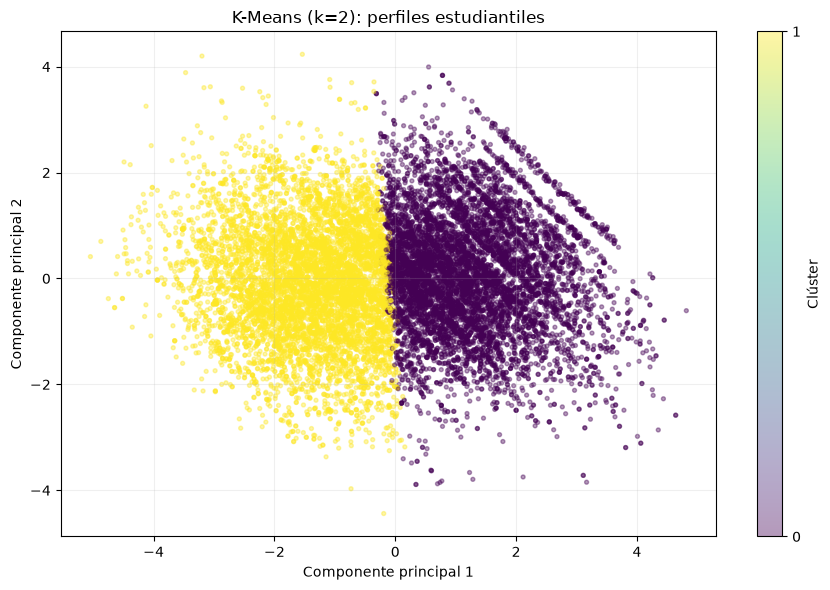


Tabla guardada: D:\Proyectos Grandes Curos 2026-2\Examen de Inteligencia Artificial\Entrega_Final_IA\resultados\reproducido\perfiles_clusters.csv
Figura PCA guardada: D:\Proyectos Grandes Curos 2026-2\Examen de Inteligencia Artificial\Entrega_Final_IA\resultados\reproducido\figuras\clustering_kmeans_pca.png


In [49]:

# ============================================================
# 5.4 PERFILES SOCIOEDUCATIVOS Y VISUALIZACIÓN PCA
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# 1. Recuperar el clustering refinado seleccionado
etiquetas_finales = etiquetas_refinadas["K-Means_k2"]

# 2. Utilizar valores originales para interpretar los grupos
perfil_final = datos_cluster.reset_index(drop=True).copy()

perfil_final["Cluster"] = etiquetas_finales

# 3. Convertir variables de interpretación a números
variables_perfil = [
    "INGHOG2D_25",
    "GASHOG2D_25",
    "ratio_docente_ps",
    "proporcion_publicos",
    "locales_escolares",
    "P208A_25",
    "EDAD_NORMATIVA",
    "REZAGO_ESCOLAR"
]

for variable in variables_perfil:
    perfil_final[variable] = pd.to_numeric(
        perfil_final[variable],
        errors="coerce"
    )

# 4. Calcular desfase escolar
perfil_final["desfase_anios"] = (
    perfil_final["P208A_25"]
    - perfil_final["EDAD_NORMATIVA"]
)

# 5. Caracterizar ambos grupos
tabla_perfiles_final = perfil_final.groupby("Cluster").agg(
    Estudiantes=("Cluster", "size"),
    Ingreso_mediano=("INGHOG2D_25", "median"),
    Gasto_mediano=("GASHOG2D_25", "median"),
    Ratio_docente=("ratio_docente_ps", "median"),
    Proporcion_publicos=("proporcion_publicos", "median"),
    Locales_escolares=("locales_escolares", "median"),
    Desfase_promedio=("desfase_anios", "mean"),
    Rezago_porcentaje=("REZAGO_ESCOLAR", "mean")
)

tabla_perfiles_final["Rezago_porcentaje"] *= 100

tabla_perfiles_final = tabla_perfiles_final.round(2)

print("CARACTERIZACIÓN FINAL DE LOS CLÚSTERES")
display(tabla_perfiles_final)

# 6. Crear carpeta de resultados
carpeta_figuras = Path(
    str(RAIZ_PROYECTO / 'resultados/reproducido/figuras')
)

carpeta_figuras.mkdir(parents=True, exist_ok=True)

# 7. Guardar tabla de perfiles
ruta_tabla = carpeta_figuras.parent / "perfiles_clusters.csv"

tabla_perfiles_final.to_csv(
    ruta_tabla,
    encoding="utf-8-sig"
)

# ============================================================
# 8. GRÁFICO PCA
# ============================================================

plt.figure(figsize=(9, 6))

grafico = plt.scatter(
    X_cluster_refinado_pca[:, 0],
    X_cluster_refinado_pca[:, 1],
    c=etiquetas_finales,
    cmap="viridis",
    s=8,
    alpha=0.4
)

plt.colorbar(
    grafico,
    ticks=[0, 1],
    label="Clúster"
)

plt.title("K-Means (k=2): perfiles estudiantiles")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")

plt.grid(alpha=0.2)
plt.tight_layout()

ruta_pca = carpeta_figuras / "clustering_kmeans_pca.png"

plt.savefig(
    ruta_pca,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\nTabla guardada:", ruta_tabla)
print("Figura PCA guardada:", ruta_pca)



### 6.6. Visualización del coeficiente de silueta

Se genera un gráfico de silueta para el modelo K-Means refinado con k=2.

La visualización utiliza una muestra aleatoria reproducible de 1200 registros. El gráfico permite evaluar la cohesión y separación de los grupos y detectar observaciones con silueta negativa.

Esta figura complementa las métricas cuantitativas utilizadas en la selección del algoritmo.


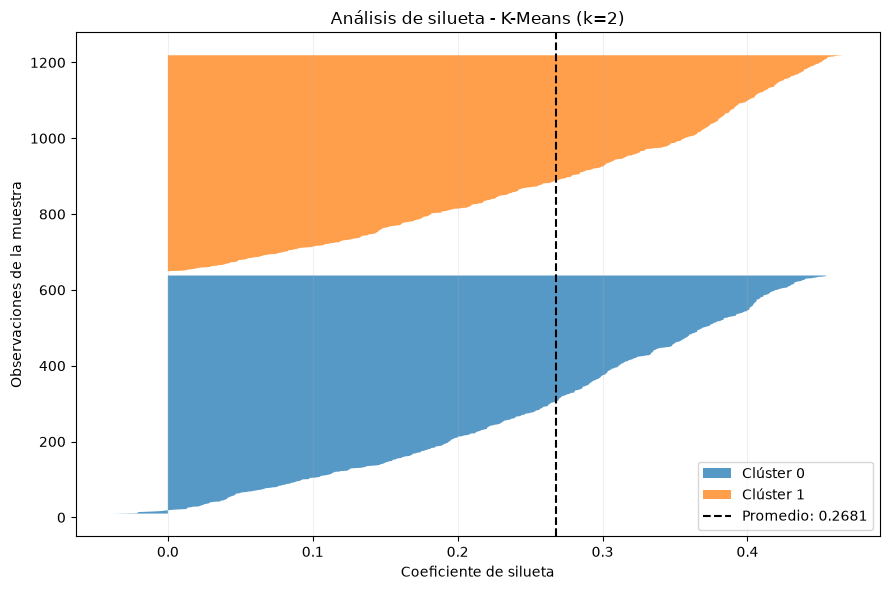

SILUETA PROMEDIO: 0.2681
Figura guardada: D:\Proyectos Grandes Curos 2026-2\Examen de Inteligencia Artificial\Entrega_Final_IA\resultados\reproducido\figuras\clustering_kmeans_silueta.png

GRÁFICOS DE CLUSTERING GENERADOS


In [50]:

# ============================================================
# 5.5 GRÁFICO DE SILUETA DE K-MEANS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import silhouette_samples

# 1. Seleccionar la misma cantidad usada en la evaluación
generador = np.random.RandomState(42)

indices_muestra = generador.choice(
    len(etiquetas_finales),
    size=1200,
    replace=False
)

X_muestra = X_cluster_refinado_escalado[indices_muestra]
etiquetas_muestra = np.asarray(
    etiquetas_finales
)[indices_muestra]

# 2. Calcular silueta de cada observación
siluetas = silhouette_samples(
    X_muestra,
    etiquetas_muestra
)

silueta_promedio = siluetas.mean()

# 3. Dibujar gráfico
plt.figure(figsize=(9, 6))

limite_inferior = 10

for grupo in np.unique(etiquetas_muestra):

    valores = np.sort(
        siluetas[etiquetas_muestra == grupo]
    )

    tamaño = len(valores)
    limite_superior = limite_inferior + tamaño

    plt.fill_betweenx(
        np.arange(limite_inferior, limite_superior),
        0,
        valores,
        alpha=0.75,
        label=f"Clúster {grupo}"
    )

    limite_inferior = limite_superior + 10

# 4. Línea del promedio
plt.axvline(
    x=silueta_promedio,
    color="black",
    linestyle="--",
    label=f"Promedio: {silueta_promedio:.4f}"
)

plt.title("Análisis de silueta - K-Means (k=2)")
plt.xlabel("Coeficiente de silueta")
plt.ylabel("Observaciones de la muestra")

plt.legend()
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()

# 5. Guardar figura
ruta_silueta = (
    carpeta_figuras / "clustering_kmeans_silueta.png"
)

plt.savefig(
    ruta_silueta,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("SILUETA PROMEDIO:", round(silueta_promedio, 4))
print("Figura guardada:", ruta_silueta)

print("\nGRÁFICOS DE CLUSTERING GENERADOS")


In [51]:

# Mostrar los perfiles que ya calculamos
display(tabla_perfiles_final)


,Estudiantes,Ingreso_mediano,Gasto_mediano,Ratio_docente,Proporcion_publicos,Locales_escolares,Desfase_promedio,Rezago_porcentaje
Cluster,,,,,,,,
0,8310,47505.88,40020.64,17.67,0.59,126.0,0.38,3.84
1,7300,22591.46,21410.77,12.00,1.00,44.0,0.45,5.23


### 6.7. Interpretación de los perfiles socioeducativos

El clúster 0 reúne 8 310 escolares y se caracteriza por mayor ingreso mediano del hogar
(S/ 47 505.88 anuales), un contexto con menor proporción mediana de servicios públicos
(0.59) y 3.84 % de rezago en la muestra de entrenamiento. Se denomina **Mayor capacidad
económica y contexto de gestión educativa mixta**.

El clúster 1 comprende 7 300 escolares, con ingreso mediano de S/ 22 591.46,
proporción pública mediana de 1.00 y 5.23 % de rezago. Se denomina **Menor capacidad
económica y contexto predominantemente público**. Estas denominaciones describen
asociaciones del conjunto analizado y no identifican por sí solas ruralidad ni aislamiento digital.

La silueta refinada de 0.2681 indica separación limitada de los perfiles. La reducción
respecto del experimento inicial se interpreta junto con la eliminación de agrupaciones
dominadas por códigos estructurales. El desfase escolar forma parte del espacio de
clustering; por ello, la diferencia de rezago entre grupos no constituye una validación
externa independiente. El objetivo binario no se utilizó como etiqueta supervisada del clustering.



## 7. Selección, entrenamiento y evaluación final del clasificador

### 7.1. Selección del modelo mediante validación cruzada

Se selecciona la configuración con mayor F1 de la clase positiva entre las diez configuraciones evaluadas mediante GroupKFold.

La elección se realiza exclusivamente con resultados de validación cruzada del entrenamiento. Se reconoce que las diferencias observadas son pequeñas y que los resultados predictivos muestran limitaciones.

### 7.2. Entrenamiento definitivo y evaluación de prueba

Una vez seleccionada la configuración, se entrena utilizando los 15,610 registros del entrenamiento completo.

El modelo se evalúa una sola vez en los 3,880 registros reservados, utilizando F1 macro, F1 de rezago, precisión, recall, ROC-AUC y Average Precision.

Se conservan los mismos hiperparámetros y las mismas variables de los experimentos previos. El conjunto de prueba no se utiliza para cambiar parámetros ni escoger otro modelo.


In [52]:

# ============================================================
# 6.1 Y 6.2 SELECCIÓN Y ENTRENAMIENTO DEFINITIVO
# ============================================================

import numpy as np
import pandas as pd
import joblib

from pathlib import Path
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

# 1. Elegir el modelo según el F1 de rezago
ranking = comparacion_general.sort_values(
    by="f1_rezago",
    ascending=False
)

print("TRES MEJORES CONFIGURACIONES SEGÚN F1 DE REZAGO")
display(ranking.head(3))

ganador = ranking.iloc[0]["Modelo"]
print("\nMODELO SELECCIONADO:", ganador)

assert ganador == "XGBoost Balanceado"

# 2. Verificar que entrenamiento y prueba estén separados
grupos_entrenamiento = set(grupos.iloc[train_idx])
grupos_prueba = set(grupos.iloc[test_idx])

assert grupos_entrenamiento.isdisjoint(grupos_prueba)

assert len(X_train) == 15610
assert len(X_test) == 3880

# 3. Calcular el peso con el entrenamiento completo
negativos = int((y_train == 0).sum())
positivos = int((y_train == 1).sum())

peso_final = negativos / positivos

print("\nNegativos:", negativos)
print("Positivos:", positivos)
print("Peso positivo:", round(peso_final, 4))

# 4. Conservar exactamente los parámetros comparados
modelo_final = Pipeline([
    ("preprocesamiento", clone(preprocesador)),
    ("clasificador", XGBClassifier(
        n_estimators=150,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=peso_final,
        tree_method="hist",
        random_state=42,
        n_jobs=4
    ))
])

# 5. Entrenar con TODOS los registros de entrenamiento
modelo_final.fit(X_train, y_train)

print("\nENTRENAMIENTO DEFINITIVO COMPLETADO")

# 6. Guardar el Pipeline completo
carpeta_modelos = Path(
    str(RAIZ_PROYECTO / 'resultados/reproducido/modelos')
)

carpeta_modelos.mkdir(parents=True, exist_ok=True)

ruta_modelo = carpeta_modelos / "xgboost_balanceado_final.joblib"

joblib.dump(modelo_final, ruta_modelo)

print("MODELO GUARDADO:", ruta_modelo)
print("Los datos de prueba todavía no se han evaluado.")


TRES MEJORES CONFIGURACIONES SEGÚN F1 DE REZAGO


,Modelo,f1_macro,f1_rezago,recall_rezago,average_precision,roc_auc
7,XGBoost Balanceado,0.4809,0.1203,0.4081,0.0774,0.6152
1,Regresión Logística Balanceada,0.4405,0.1166,0.5461,0.0886,0.6340
4,Random Forest Balanceado,0.5158,0.1155,0.2232,0.0719,0.6070



MODELO SELECCIONADO: XGBoost Balanceado

Negativos: 14909
Positivos: 701
Peso positivo: 21.2682



ENTRENAMIENTO DEFINITIVO COMPLETADO
MODELO GUARDADO: D:\Proyectos Grandes Curos 2026-2\Examen de Inteligencia Artificial\Entrega_Final_IA\resultados\reproducido\modelos\xgboost_balanceado_final.joblib
Los datos de prueba todavía no se han evaluado.


In [53]:

# ============================================================
# 6.2.1 VERIFICACIÓN DEL PIPELINE DEFINITIVO
# ============================================================

print("ETAPAS DEL PIPELINE:")
print(modelo_final.named_steps.keys())

print("\nMODELO:")
print(type(modelo_final.named_steps["clasificador"]).__name__)

print("\nÁRBOLES ENTRENADOS:")
print(modelo_final.named_steps["clasificador"].n_estimators)

print("\nARCHIVO GUARDADO:")
print(ruta_modelo)

print("\nEXISTE EN DISCO:", ruta_modelo.is_file())


ETAPAS DEL PIPELINE:
dict_keys(['preprocesamiento', 'clasificador'])

MODELO:
XGBClassifier

ÁRBOLES ENTRENADOS:
150

ARCHIVO GUARDADO:
D:\Proyectos Grandes Curos 2026-2\Examen de Inteligencia Artificial\Entrega_Final_IA\resultados\reproducido\modelos\xgboost_balanceado_final.joblib

EXISTE EN DISCO: True



### 7.3. Evaluación definitiva sobre el conjunto de prueba

El modelo XGBoost balanceado, seleccionado previamente mediante validación cruzada GroupKFold, se evalúa sobre los 3880 registros del conjunto de prueba reservado.

Se calculan accuracy, precisión y recall de la clase positiva, F1 de rezago, F1 macro, ROC-AUC, Average Precision, área bajo la curva precisión-recall y Brier Score.

Asimismo, se obtiene la matriz de confusión para analizar los falsos positivos y falsos negativos.

El conjunto de prueba se utiliza únicamente para la evaluación final y no para modificar el modelo, seleccionar nuevos hiperparámetros o cambiar el umbral de clasificación.


In [54]:

# ============================================================
# 6.3 EVALUACIÓN DEFINITIVA DEL MODELO XGBOOST
# ============================================================

import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    auc,
    brier_score_loss,
    confusion_matrix,
    classification_report
)

# 1. Verificar que utilizamos los datos de prueba reservados
assert len(X_test) == 3880
assert len(y_test) == 3880
assert set(y_test.unique()) == {0, 1}

# 2. Predecir utilizando el Pipeline definitivo ya entrenado
predicciones_finales = modelo_final.predict(X_test)

probabilidades_finales = (
    modelo_final.predict_proba(X_test)[:, 1]
)

# 3. Obtener la curva Precision-Recall
precision_curva, recall_curva, umbrales_pr = (
    precision_recall_curve(
        y_test,
        probabilidades_finales
    )
)

# 4. Calcular las métricas
metricas_finales = {
    "Accuracy": accuracy_score(
        y_test, predicciones_finales
    ),
    "Precision rezago": precision_score(
        y_test, predicciones_finales,
        zero_division=0
    ),
    "Recall rezago": recall_score(
        y_test, predicciones_finales,
        zero_division=0
    ),
    "F1 rezago": f1_score(
        y_test, predicciones_finales,
        zero_division=0
    ),
    "F1 macro": f1_score(
        y_test, predicciones_finales,
        average="macro",
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test, probabilidades_finales
    ),
    "Average Precision": average_precision_score(
        y_test, probabilidades_finales
    ),
    "PR-AUC": auc(
        recall_curva, precision_curva
    ),
    "Brier Score": brier_score_loss(
        y_test, probabilidades_finales
    )
}

tabla_metricas_finales = pd.DataFrame(
    list(metricas_finales.items()),
    columns=["Métrica", "Resultado"]
)

print("RESULTADOS FINALES DE PRUEBA")
display(tabla_metricas_finales.round(4))

# ============================================================
# 5. MATRIZ DE CONFUSIÓN
# ============================================================

matriz_final = confusion_matrix(
    y_test,
    predicciones_finales,
    labels=[0, 1]
)

tabla_matriz_final = pd.DataFrame(
    matriz_final,
    index=["Real sin rezago", "Real con rezago"],
    columns=["Predicho sin rezago", "Predicho con rezago"]
)

print("\nMATRIZ DE CONFUSIÓN")
display(tabla_matriz_final)

# 6. Identificar los cuatro resultados de clasificación
TN, FP, FN, TP = matriz_final.ravel()

print("\nVERDADEROS NEGATIVOS:", TN)
print("FALSOS POSITIVOS:", FP)
print("FALSOS NEGATIVOS:", FN)
print("VERDADEROS POSITIVOS:", TP)

# 7. Reporte de clasificación
print("\nREPORTE DE CLASIFICACIÓN")
print(
    classification_report(
        y_test,
        predicciones_finales,
        target_names=["Sin rezago", "Con rezago"],
        zero_division=0
    )
)

print("\nEVALUACIÓN FINAL COMPLETADA")


RESULTADOS FINALES DE PRUEBA


,Métrica,Resultado
0,Accuracy,0.7361
1,Precision rezago,0.0648
2,Recall rezago,0.4305
3,F1 rezago,0.1127
4,F1 macro,0.4788
5,ROC-AUC,0.6250
6,Average Precision,0.0921
7,PR-AUC,0.0898
8,Brier Score,0.1890



MATRIZ DE CONFUSIÓN


,Predicho sin rezago,Predicho con rezago
Real sin rezago,2791,938
Real con rezago,86,65



VERDADEROS NEGATIVOS: 2791
FALSOS POSITIVOS: 938
FALSOS NEGATIVOS: 86
VERDADEROS POSITIVOS: 65

REPORTE DE CLASIFICACIÓN
              precision    recall  f1-score   support

  Sin rezago       0.97      0.75      0.84      3729
  Con rezago       0.06      0.43      0.11       151

    accuracy                           0.74      3880
   macro avg       0.52      0.59      0.48      3880
weighted avg       0.93      0.74      0.82      3880


EVALUACIÓN FINAL COMPLETADA



### 7.4. Visualización de resultados y análisis de errores

Se presentan los resultados del modelo definitivo XGBoost balanceado mediante una matriz de confusión, una curva ROC, una curva Precision-Recall y una curva de calibración.

La evaluación utiliza los 3880 registros del conjunto de prueba reservado. Se analizan los falsos positivos y falsos negativos, así como la capacidad de discriminación y la confiabilidad de las probabilidades estimadas.

El modelo presenta limitaciones para identificar el rezago escolar, especialmente por la elevada cantidad de falsos positivos. Los resultados se reportan sin realizar nuevos ajustes sobre el conjunto de prueba.


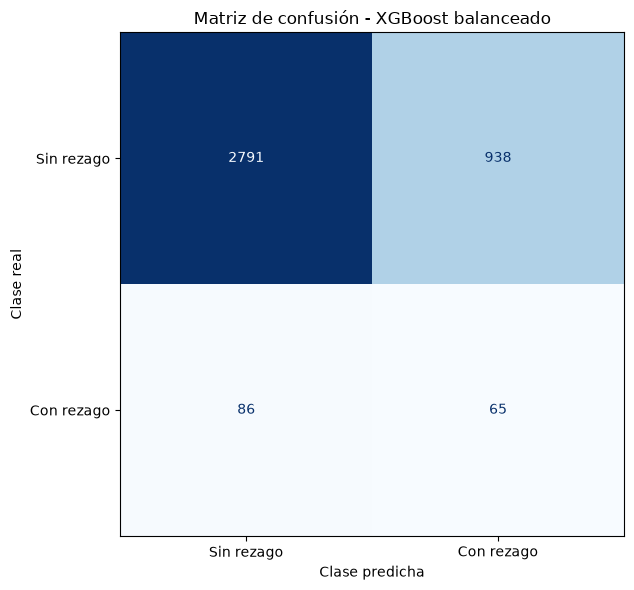

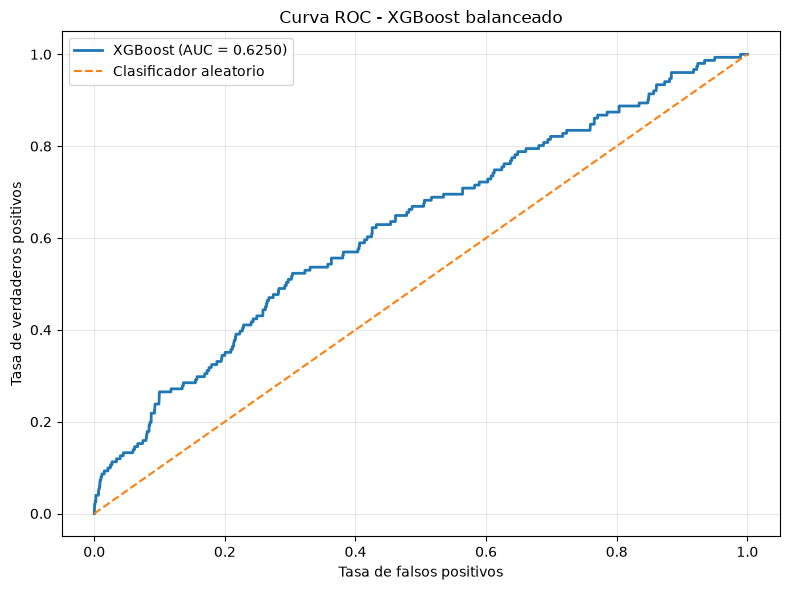

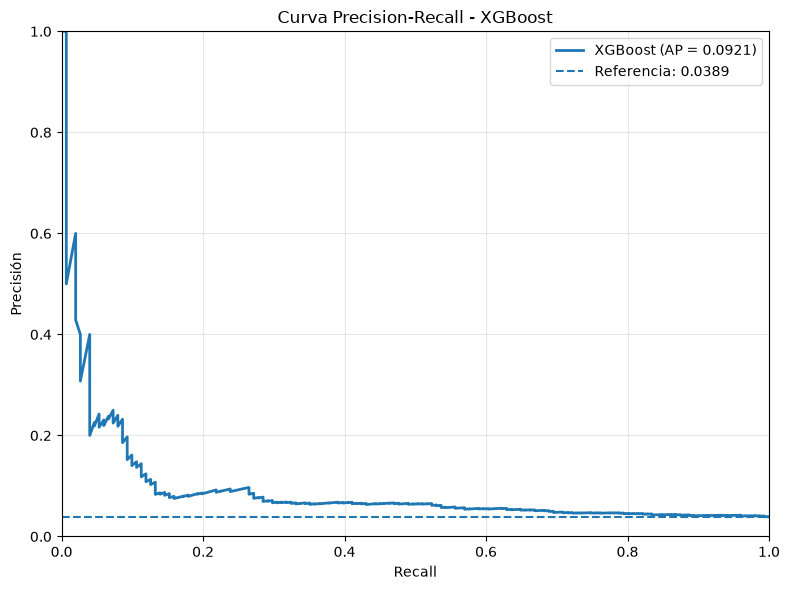

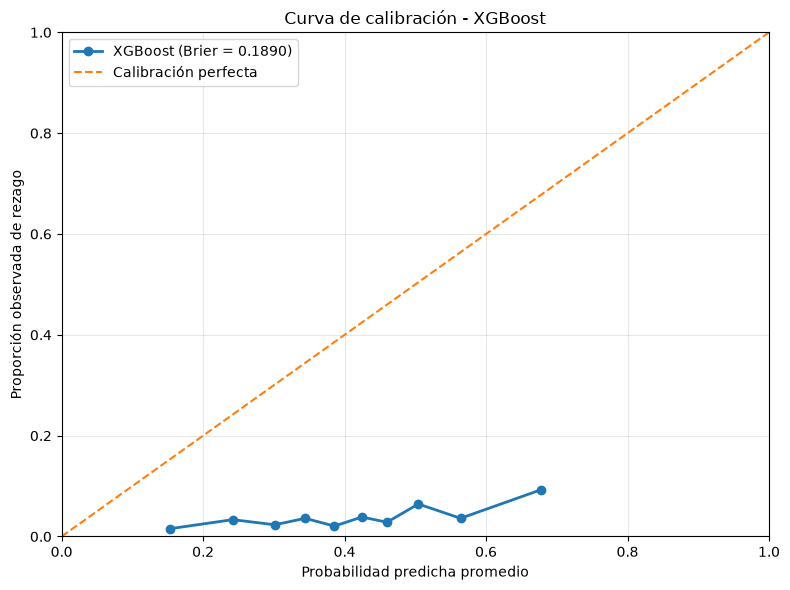


FIGURAS GENERADAS Y GUARDADAS: D:\Proyectos Grandes Curos 2026-2\Examen de Inteligencia Artificial\Entrega_Final_IA\resultados\reproducido\figuras
ROC-AUC: 0.625
Average Precision: 0.0921
PR-AUC: 0.0898
Brier Score: 0.189

SECCIÓN 6.4 COMPLETADA


In [55]:

# ============================================================
# 6.4 GRÁFICOS DE EVALUACIÓN FINAL DE XGBOOST
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
    auc,
    brier_score_loss
)

from sklearn.calibration import calibration_curve

# 1. Preparar carpeta para las figuras del artículo
carpeta_figuras = Path(
    str(RAIZ_PROYECTO / 'resultados/reproducido/figuras')
)

carpeta_figuras.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. MATRIZ DE CONFUSIÓN
# ============================================================

fig, ax = plt.subplots(figsize=(7, 6))

visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz_final,
    display_labels=["Sin rezago", "Con rezago"]
)

visualizacion.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Matriz de confusión - XGBoost balanceado")
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")

fig.tight_layout()

fig.savefig(
    carpeta_figuras / "06_matriz_confusion.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 3. CURVA ROC
# ============================================================

fpr, tpr, umbrales_roc = roc_curve(
    y_test,
    probabilidades_finales
)

valor_roc = roc_auc_score(
    y_test,
    probabilidades_finales
)

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"XGBoost (AUC = {valor_roc:.4f})"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Clasificador aleatorio"
)

ax.set_title("Curva ROC - XGBoost balanceado")
ax.set_xlabel("Tasa de falsos positivos")
ax.set_ylabel("Tasa de verdaderos positivos")
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()

fig.savefig(
    carpeta_figuras / "07_curva_roc.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 4. CURVA PRECISION-RECALL
# ============================================================

precision, recall, umbrales_pr = precision_recall_curve(
    y_test,
    probabilidades_finales
)

ap = average_precision_score(
    y_test,
    probabilidades_finales
)

pr_auc = auc(recall, precision)

prevalencia = float(y_test.mean())

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    recall,
    precision,
    linewidth=2,
    label=f"XGBoost (AP = {ap:.4f})"
)

ax.axhline(
    y=prevalencia,
    linestyle="--",
    label=f"Referencia: {prevalencia:.4f}"
)

ax.set_title("Curva Precision-Recall - XGBoost")
ax.set_xlabel("Recall")
ax.set_ylabel("Precisión")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()

fig.savefig(
    carpeta_figuras / "08_curva_precision_recall.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 5. CURVA DE CALIBRACIÓN
# ============================================================

fraccion_positivos, probabilidad_media = calibration_curve(
    y_test,
    probabilidades_finales,
    n_bins=10,
    strategy="quantile"
)

valor_brier = brier_score_loss(
    y_test,
    probabilidades_finales
)

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    probabilidad_media,
    fraccion_positivos,
    marker="o",
    linewidth=2,
    label=f"XGBoost (Brier = {valor_brier:.4f})"
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Calibración perfecta"
)

ax.set_title("Curva de calibración - XGBoost")
ax.set_xlabel("Probabilidad predicha promedio")
ax.set_ylabel("Proporción observada de rezago")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()

fig.savefig(
    carpeta_figuras / "09_curva_calibracion.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# 6. GUARDAR EVIDENCIAS NUMÉRICAS
# ============================================================

carpeta_resultados = carpeta_figuras.parent

tabla_metricas_finales.to_csv(
    carpeta_resultados / "metricas_finales.csv",
    index=False,
    encoding="utf-8-sig"
)

tabla_matriz_final.to_csv(
    carpeta_resultados / "matriz_confusion_final.csv",
    encoding="utf-8-sig"
)

print("\nFIGURAS GENERADAS Y GUARDADAS:", carpeta_figuras)
print("ROC-AUC:", round(valor_roc, 4))
print("Average Precision:", round(ap, 4))
print("PR-AUC:", round(pr_auc, 4))
print("Brier Score:", round(valor_brier, 4))
print("\nSECCIÓN 6.4 COMPLETADA")


### 7.5. Alcance predictivo y calibración

En prueba, XGBoost balanceado alcanza ROC-AUC 0.6250, F1 macro 0.4788 y F1 de
rezago 0.1127. Detecta 65 de los 151 casos con rezago, omite 86 y produce 938 falsos
positivos. La precisión positiva de 0.0648 limita su uso como identificación individual
automática, aunque el recall de 0.4305 permite describir el intercambio entre sensibilidad
y falsas alarmas del umbral conservado.

La curva de calibración y Brier Score de 0.1890 se interpretan junto con el desbalance
y los pesos de clase; los scores no se asumen probabilidades poblacionales bien calibradas.
No se cambia el umbral ni se seleccionan hiperparámetros usando los resultados de prueba.


In [56]:
import importlib.util
assert importlib.util.find_spec('shap') is not None, "Instale las dependencias de requirements.txt"



## 8. Explicabilidad del modelo mediante SHAP

### 8.1. Cálculo de contribuciones SHAP

Se aplica Tree SHAP al modelo definitivo XGBoost balanceado para estudiar la contribución de las variables predictoras.

Para el análisis global se utiliza una muestra reproducible de 300 registros de entrenamiento. Se obtienen las contribuciones de las variables después del preprocesamiento, conservando sus nombres.

Se comprueba que la suma de las contribuciones y el valor base reproduzca la predicción del modelo en escala log-odds.

### 8.1.1. Alcance de las visualizaciones globales e individuales

Se generan cinco visualizaciones: un Summary Plot tipo beeswarm, dos gráficos de dependencia y dos waterfall.

Las explicaciones individuales corresponden a un verdadero positivo de alta probabilidad estimada y un verdadero negativo de baja probabilidad estimada, seleccionados para ilustrar el comportamiento del modelo sin modificarlo.

Los valores SHAP explican contribuciones predictivas, no relaciones causales.


In [57]:

# ============================================================
# 7.1 PREPARACIÓN DE CONTRIBUCIONES TREE SHAP
# ============================================================

import numpy as np
import pandas as pd
import shap
import xgboost as xgb

from scipy import sparse
from scipy.special import expit

# 1. Recuperar las partes del Pipeline definitivo
prepro_final = modelo_final.named_steps["preprocesamiento"]
xgb_final = modelo_final.named_steps["clasificador"]

# 2. Seleccionar una muestra reproducible de entrenamiento
rng_shap = np.random.default_rng(42)

indices_shap = rng_shap.choice(
    len(X_train),
    size=300,
    replace=False
)

X_shap_original = X_train.iloc[indices_shap]

# 3. Aplicar el preprocesador YA entrenado
X_shap_transformado = prepro_final.transform(
    X_shap_original
)

# 4. Recuperar los nombres de las variables
nombres_shap = list(
    prepro_final.get_feature_names_out()
)

# 5. Calcular contribuciones SHAP nativas de XGBoost
booster = xgb_final.get_booster()

matriz_shap = xgb.DMatrix(X_shap_transformado)

contribuciones = booster.predict(
    matriz_shap,
    pred_contribs=True
)

# 6. Separar contribuciones y valor base
valores_shap = contribuciones[:, :-1]
valores_base = contribuciones[:, -1]

# 7. Convertir la matriz a formato numérico para los gráficos
if sparse.issparse(X_shap_transformado):
    valores_variables = X_shap_transformado.toarray()
else:
    valores_variables = np.asarray(X_shap_transformado)

# 8. Verificar dimensiones
assert valores_shap.shape[1] == len(nombres_shap)
assert valores_variables.shape == valores_shap.shape

# 9. Verificar que SHAP reconstruya las predicciones
probabilidades_reconstruidas = expit(
    contribuciones.sum(axis=1)
)

probabilidades_modelo = modelo_final.predict_proba(
    X_shap_original
)[:, 1]

np.testing.assert_allclose(
    probabilidades_reconstruidas,
    probabilidades_modelo,
    rtol=1e-4,
    atol=1e-5
)

# 10. Crear el objeto SHAP Explanation
explicacion_shap = shap.Explanation(
    values=valores_shap,
    base_values=valores_base,
    data=valores_variables,
    feature_names=nombres_shap
)

print("SHAP CALCULADO CORRECTAMENTE")
print("Observaciones:", valores_shap.shape[0])
print("Variables transformadas:", valores_shap.shape[1])
print("Reconstrucción de predicciones: CORRECTA")


D:\Proyectos Grandes Curos 2026-2\Inteligencia Artificial\Sesion 3 con Ciencia de datos\envprueba\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP CALCULADO CORRECTAMENTE
Observaciones: 300
Variables transformadas: 35
Reconstrucción de predicciones: CORRECTA



### 8.2. Análisis global y dependencia de variables mediante SHAP

Se genera un gráfico SHAP Beeswarm para identificar las diez características transformadas con mayor contribución a las predicciones del modelo XGBoost balanceado.

También se elaboran dos gráficos de dependencia utilizando las variables numéricas de mayor importancia SHAP.

Las visualizaciones utilizan 300 registros del entrenamiento y permiten estudiar contribuciones predictivas e interacciones aparentes, sin establecer relaciones causales.


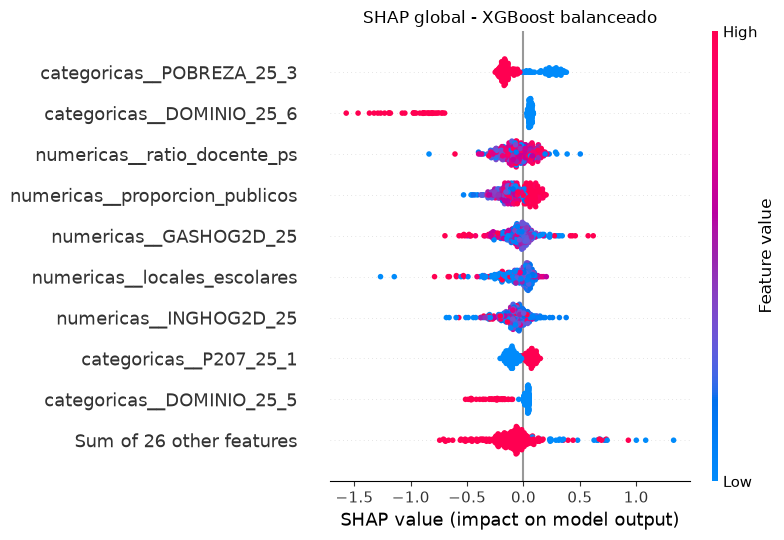

Gráfico Beeswarm generado.

VARIABLES SELECCIONADAS PARA DEPENDENCIA:
numericas__ratio_docente_ps | Importancia: 0.121
numericas__proporcion_publicos | Importancia: 0.1208


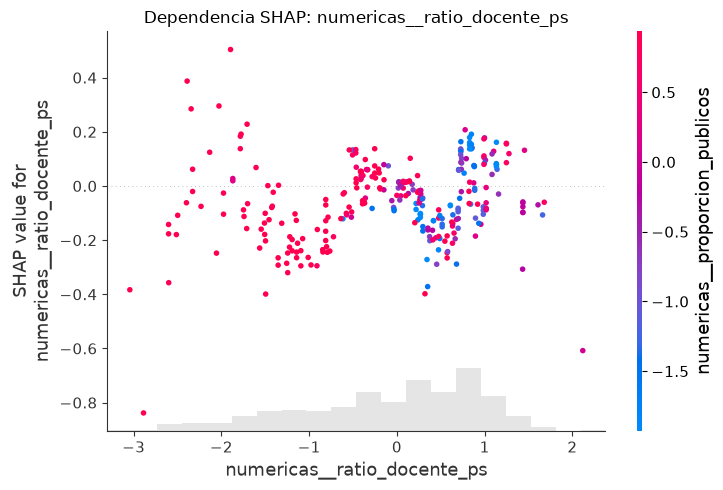

Dependencia SHAP guardada: numericas__ratio_docente_ps


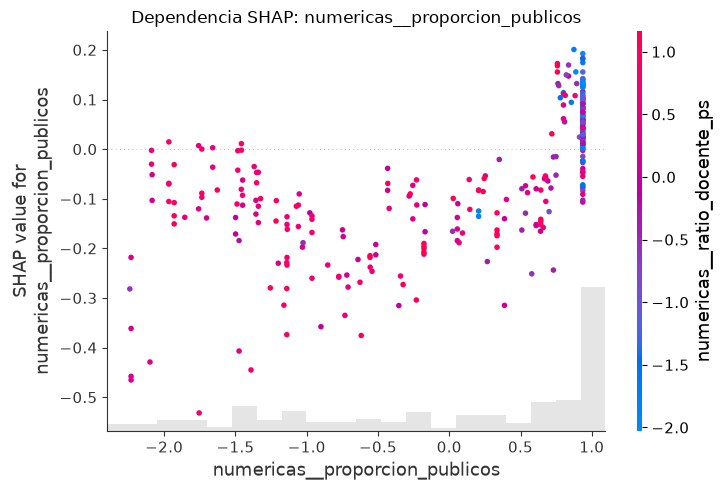

Dependencia SHAP guardada: numericas__proporcion_publicos

BEESWARM Y DOS DEPENDENCIAS GUARDADOS


In [58]:

# ============================================================
# 7.2 BEESWARM Y DOS GRÁFICOS DE DEPENDENCIA SHAP
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import shap

# ============================================================
# 1. GRÁFICO GLOBAL SHAP BEESWARM
# ============================================================

shap.plots.beeswarm(
    explicacion_shap,
    max_display=10,
    show=False
)

plt.title("SHAP global - XGBoost balanceado")
plt.tight_layout()

plt.savefig(
    carpeta_figuras / "10_shap_beeswarm.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("Gráfico Beeswarm generado.")

# ============================================================
# 2. IDENTIFICAR VARIABLES NUMÉRICAS MÁS INFLUYENTES
# ============================================================

# Importancia promedio absoluta de cada característica
importancias_shap = np.abs(valores_shap).mean(axis=0)

# Identificar las variables numéricas originales transformadas
indices_numericos = [
    i for i, nombre in enumerate(nombres_shap)
    if nombre.startswith("numericas__")
]

# Seleccionar las dos más importantes
indices_dependencia = sorted(
    indices_numericos,
    key=lambda i: importancias_shap[i],
    reverse=True
)[:2]

assert len(indices_dependencia) == 2

print("\nVARIABLES SELECCIONADAS PARA DEPENDENCIA:")

for indice in indices_dependencia:
    print(
        nombres_shap[indice],
        "| Importancia:",
        round(float(importancias_shap[indice]), 4)
    )

# ============================================================
# 3. DOS GRÁFICOS DE DEPENDENCIA
# ============================================================

for numero, indice in enumerate(indices_dependencia, 1):

    indice_color = indices_dependencia[1 - (numero - 1)]

    nombre_variable = nombres_shap[indice]

    shap.plots.scatter(
        explicacion_shap[:, indice],
        color=explicacion_shap[:, indice_color],
        show=False
    )

    plt.title(f"Dependencia SHAP: {nombre_variable}")
    plt.tight_layout()

    plt.savefig(
        carpeta_figuras / f"1{numero}_shap_dependencia.png",
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    print("Dependencia SHAP guardada:", nombre_variable)

print("\nBEESWARM Y DOS DEPENDENCIAS GUARDADOS")


### 8.2.1. Visualización global ampliada

Se representan diez características transformadas individuales y una fila adicional
que agrupa las restantes. La visualización de referencia anterior se conserva con sus
resultados originales; la ampliación utiliza las mismas 300 observaciones y contribuciones,
sin modificar el modelo ni recalcular su entrenamiento.


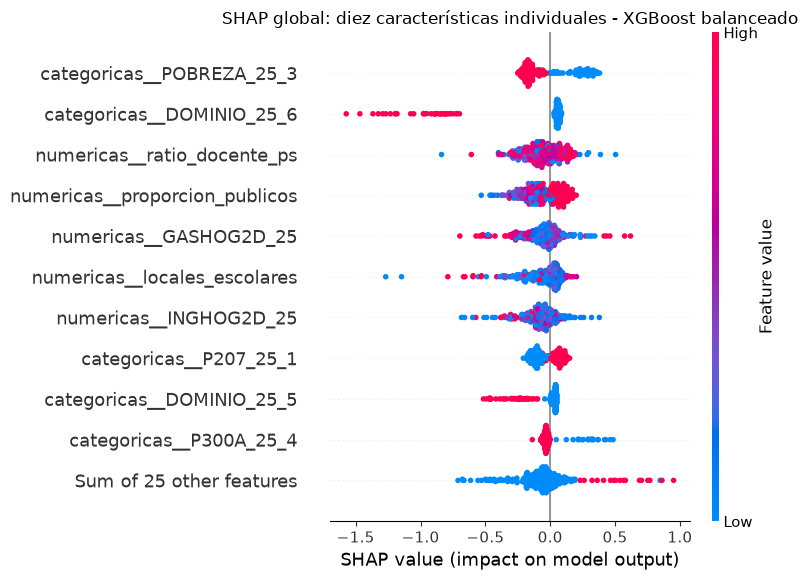

In [59]:
# ============================================================
# SHAP GLOBAL: DIEZ CARACTERÍSTICAS INDIVIDUALES Y RESTO
# ============================================================

import matplotlib.pyplot as plt
import shap

shap.plots.beeswarm(explicacion_shap, max_display=11, show=False)
plt.title("SHAP global: diez características individuales - XGBoost balanceado")
plt.tight_layout()
plt.savefig(carpeta_figuras / "10_shap_beeswarm_diez_caracteristicas.png",
            dpi=200, bbox_inches="tight")
plt.show()



### 8.3. Explicación individual de predicciones mediante SHAP Waterfall

Se generan dos gráficos SHAP Waterfall para interpretar predicciones individuales del modelo definitivo XGBoost balanceado.

El primer caso corresponde a un verdadero positivo con alta probabilidad estimada de rezago escolar. El segundo corresponde a un verdadero negativo con baja probabilidad estimada de rezago.

Se emplean las contribuciones SHAP en escala log-odds. Los casos se seleccionan únicamente para explicar las predicciones ya obtenidas, sin modificar ni volver a entrenar el modelo.


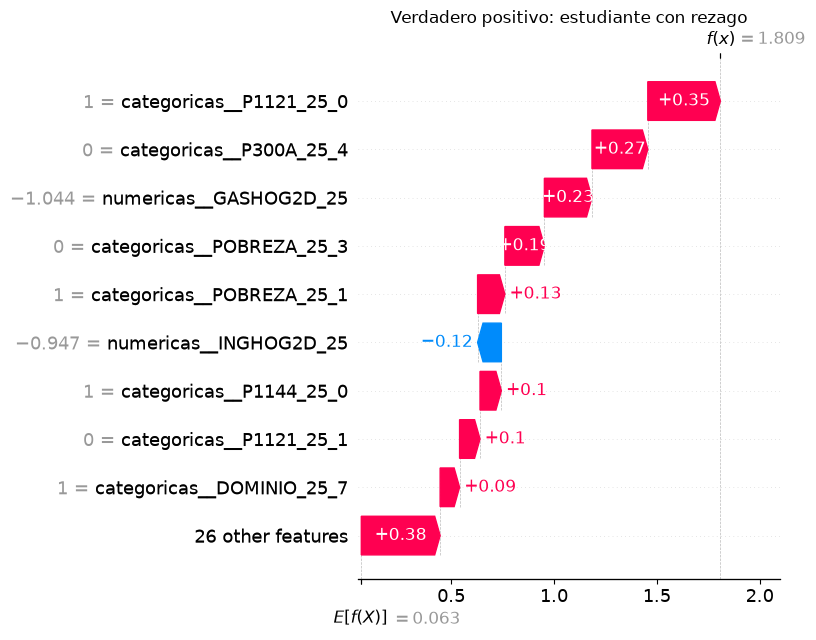


CASO: Verdadero positivo: estudiante con rezago
Probabilidad estimada de rezago: 0.8592
Figura guardada: D:\Proyectos Grandes Curos 2026-2\Examen de Inteligencia Artificial\Entrega_Final_IA\resultados\reproducido\figuras\13_shap_waterfall_alto.png


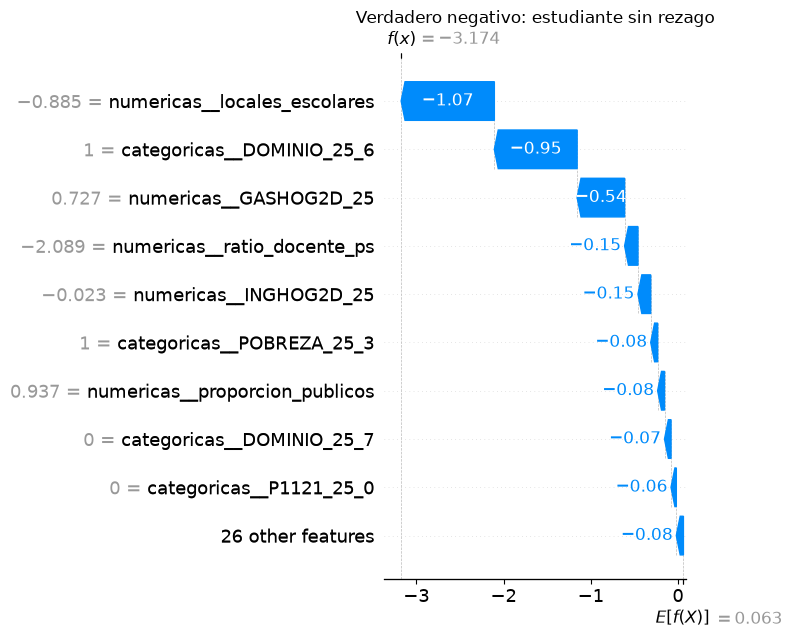


CASO: Verdadero negativo: estudiante sin rezago
Probabilidad estimada de rezago: 0.0402
Figura guardada: D:\Proyectos Grandes Curos 2026-2\Examen de Inteligencia Artificial\Entrega_Final_IA\resultados\reproducido\figuras\14_shap_waterfall_bajo.png

RESUMEN DE EXPLICACIONES


,Caso,Clase real,Clase predicha,Probabilidad de rezago
0,Verdadero positivo,1,1,0.8592
1,Verdadero negativo,0,0,0.0402



CINCO FIGURAS SHAP GENERADAS
Ubicación: D:\Proyectos Grandes Curos 2026-2\Examen de Inteligencia Artificial\Entrega_Final_IA\resultados\reproducido\figuras


In [60]:

# ============================================================
# 7.3 DOS GRÁFICOS SHAP WATERFALL
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import xgboost as xgb

from scipy import sparse
from scipy.special import expit

# ============================================================
# 1. IDENTIFICAR DOS PREDICCIONES CORRECTAS
# ============================================================

etiquetas_reales = y_test.to_numpy()

verdaderos_positivos = np.flatnonzero(
    (etiquetas_reales == 1) &
    (predicciones_finales == 1)
)

verdaderos_negativos = np.flatnonzero(
    (etiquetas_reales == 0) &
    (predicciones_finales == 0)
)

assert len(verdaderos_positivos) > 0
assert len(verdaderos_negativos) > 0

# Seleccionar un caso positivo con probabilidad alta
indice_alto = verdaderos_positivos[
    np.argmax(probabilidades_finales[verdaderos_positivos])
]

# Seleccionar un caso negativo con probabilidad baja
indice_bajo = verdaderos_negativos[
    np.argmin(probabilidades_finales[verdaderos_negativos])
]

# ============================================================
# 2. RECUPERAR LOS DOS REGISTROS
# ============================================================

indices_casos = [indice_alto, indice_bajo]

X_casos = X_test.iloc[indices_casos].copy()

# Utilizar el preprocesador definitivo ya entrenado
X_casos_transformados = (
    modelo_final.named_steps["preprocesamiento"]
    .transform(X_casos)
)

# ============================================================
# 3. CALCULAR CONTRIBUCIONES TREE SHAP
# ============================================================

booster = (
    modelo_final.named_steps["clasificador"]
    .get_booster()
)

contrib_casos = booster.predict(
    xgb.DMatrix(X_casos_transformados),
    pred_contribs=True
)

if sparse.issparse(X_casos_transformados):
    valores_casos = X_casos_transformados.toarray()
else:
    valores_casos = np.asarray(X_casos_transformados)

# Verificar que SHAP reconstruya las probabilidades
probabilidades_shap = expit(
    contrib_casos.sum(axis=1)
)

np.testing.assert_allclose(
    probabilidades_shap,
    probabilidades_finales[indices_casos],
    rtol=1e-4,
    atol=1e-5
)

# ============================================================
# 4. CREAR LAS EXPLICACIONES INDIVIDUALES
# ============================================================

explicacion_casos = shap.Explanation(
    values=contrib_casos[:, :-1],
    base_values=contrib_casos[:, -1],
    data=valores_casos,
    feature_names=nombres_shap
)

# ============================================================
# 5. GENERAR LOS DOS GRÁFICOS WATERFALL
# ============================================================

casos = [
    (
        "Verdadero positivo: estudiante con rezago",
        "13_shap_waterfall_alto.png"
    ),
    (
        "Verdadero negativo: estudiante sin rezago",
        "14_shap_waterfall_bajo.png"
    )
]

for numero, (titulo, archivo) in enumerate(casos):

    shap.plots.waterfall(
        explicacion_casos[numero],
        max_display=10,
        show=False
    )

    plt.title(titulo)
    plt.tight_layout()

    ruta = carpeta_figuras / archivo

    plt.savefig(
        ruta,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    print("\nCASO:", titulo)
    print(
        "Probabilidad estimada de rezago:",
        round(float(
            probabilidades_finales[indices_casos[numero]]
        ), 4)
    )
    print("Figura guardada:", ruta)

# ============================================================
# 6. RESUMEN DE LOS CASOS EXPLICADOS
# ============================================================

resumen_casos = pd.DataFrame({
    "Caso": [
        "Verdadero positivo",
        "Verdadero negativo"
    ],
    "Clase real": etiquetas_reales[indices_casos],
    "Clase predicha": predicciones_finales[indices_casos],
    "Probabilidad de rezago": (
        probabilidades_finales[indices_casos]
    )
})

print("\nRESUMEN DE EXPLICACIONES")
display(resumen_casos.round(4))

print("\nCINCO FIGURAS SHAP GENERADAS")
print("Ubicación:", carpeta_figuras)


### 8.4. Interpretación de las contribuciones predictivas

En la muestra global, la categoría no pobre (POBREZA=3) tiende a contribuir hacia
menor puntuación de rezago cuando está presente. El indicador DOMINIO=6 también
muestra contribuciones predominantemente negativas en los casos donde está activo.
Son asociaciones condicionadas al modelo y a la muestra explicada, no efectos causales.

El ratio alumnos/docente y la proporción de servicios públicos presentan contribuciones
heterogéneas; los gráficos de dependencia permiten examinar su variación conjunta,
sin sostener una relación monotónica universal. Sus ejes numéricos corresponden a las
variables estandarizadas por el preprocesador. Las variables categóricas aparecen
desagregadas en indicadores One-Hot, por lo que su importancia no equivale sin agregación
a un ranking de variables originales.

Los Waterfall conservan un verdadero positivo con probabilidad 0.8592 y un verdadero
negativo con 0.0402. Las contribuciones se suman en log-odds, y la transformación
logística reconstruye las probabilidades. Los ejemplos ilustran predicciones correctas
extremas y no representan la tasa de éxito general del modelo.



## 9. Consolidación de resultados y preparación de entregables

### 9.1. Exportación de evidencias experimentales

Se exportan las tablas de comparación supervisada, evaluación de clustering, perfiles estudiantiles, métricas de prueba y matriz de confusión.

Los resultados corresponden a las ejecuciones realizadas en Jupyter, manteniendo el modelo definitivo seleccionado mediante validación cruzada y sin efectuar nuevos entrenamientos.

Se verifica también la existencia de las figuras generadas para el artículo científico.


In [61]:

# ============================================================
# 8.1 CONSOLIDACIÓN DE EVIDENCIAS DEL EXAMEN
# ============================================================

from pathlib import Path
import pandas as pd
import json

# 1. Directorio del proyecto
raiz = Path(
    str(RAIZ_PROYECTO)
)

carpeta_tablas = raiz / "resultados" / "reproducido" / "tablas"
carpeta_figuras = raiz / "resultados" / "reproducido" / "figuras"

carpeta_tablas.mkdir(parents=True, exist_ok=True)

# 2. Reunir todas las tablas científicas
tablas = {
    "01_comparacion_clasificacion.csv":
        comparacion_general,

    "02_comparacion_clustering.csv":
        tabla_clusters_refinados,

    "03_perfiles_clustering.csv":
        tabla_perfiles_final.reset_index(),

    "04_metricas_prueba.csv":
        tabla_metricas_finales,

    "05_matriz_confusion.csv":
        tabla_matriz_final.reset_index()
}

# 3. Exportar las tablas
for nombre, tabla in tablas.items():

    ruta = carpeta_tablas / nombre

    tabla.to_csv(
        ruta,
        index=False,
        encoding="utf-8-sig"
    )

    print("TABLA GUARDADA:", nombre)

# 4. Guardar información metodológica
metadatos = {
    "algoritmo_final": "XGBoost Balanceado",
    "criterio_seleccion": "F1 de rezago en GroupKFold",
    "semilla": 42,
    "folds": 3,
    "entrenamiento": len(X_train),
    "prueba": len(X_test),
    "variables_originales": list(predictores),
    "umbral_prediccion": 0.5,
    "factor_expansion": "Conservado, no utilizado para ponderar",
    "fuente_enaho": "Corte 2025 de archivos panel 2021-2025",
    "escale": "Indicadores contextuales agregados por distrito",
    "rezago": "Aproximacion con 2 o mas años de desfase"
}

ruta_metadatos = carpeta_tablas / "06_metadatos_experimento.json"

with open(ruta_metadatos, "w", encoding="utf-8") as archivo:
    json.dump(
        metadatos,
        archivo,
        ensure_ascii=False,
        indent=4
    )

# 5. Verificar las once figuras esperadas
figuras = [
    "clustering_kmeans_pca.png",
    "clustering_kmeans_silueta.png",
    "06_matriz_confusion.png",
    "07_curva_roc.png",
    "08_curva_precision_recall.png",
    "09_curva_calibracion.png",
    "10_shap_beeswarm.png",
    "11_shap_dependencia.png",
    "12_shap_dependencia.png",
    "13_shap_waterfall_alto.png",
    "14_shap_waterfall_bajo.png"
]

faltantes = []

for nombre in figuras:
    ruta = carpeta_figuras / nombre

    if not ruta.is_file():
        faltantes.append(nombre)

print("\nFIGURAS ENCONTRADAS:", len(figuras) - len(faltantes))
print("FIGURAS ESPERADAS:", len(figuras))

if faltantes:
    print("FIGURAS FALTANTES:", faltantes)
else:
    print("TODAS LAS FIGURAS ESTÁN GUARDADAS")

# 6. Comprobar el modelo
ruta_modelo = (
    raiz / "resultados" / "reproducido" / "modelos"
    / "xgboost_balanceado_final.joblib"
)

print("\nMODELO GUARDADO:", ruta_modelo.is_file())
print("TABLAS GUARDADAS:", len(tablas) + 1)

print("\nCONSOLIDACIÓN FINALIZADA")


TABLA GUARDADA: 01_comparacion_clasificacion.csv
TABLA GUARDADA: 02_comparacion_clustering.csv
TABLA GUARDADA: 03_perfiles_clustering.csv
TABLA GUARDADA: 04_metricas_prueba.csv
TABLA GUARDADA: 05_matriz_confusion.csv

FIGURAS ENCONTRADAS: 11
FIGURAS ESPERADAS: 11
TODAS LAS FIGURAS ESTÁN GUARDADAS

MODELO GUARDADO: True
TABLAS GUARDADAS: 6

CONSOLIDACIÓN FINALIZADA


### 9.2. Fuentes metodológicas y límites de reproducción

Se utiliza la guía de evaluación local, la ficha técnica panel 2021–2025, el diccionario
panel (páginas PDF 588–590, 654, 657–658 y 660–662) y los cuestionarios ENAHO 2025.
La definición de atraso de [ESCALE](https://escale.minedu.gob.pe/tendencias-2016-portlet/servlet/tendencias/archivo?idCuadro=14&tipo=meta)
y el criterio de residentes y factor personal de [INEI](https://www.inei.gob.pe/media/MenuRecursivo/publicaciones_digitales/Est/Lib1244/Libro.pdf)
se emplean con las limitaciones del corte y del dominio analizado.

La preparación de clustering se recupera de la ejecución original 43 de la sesión 66
de Jupyter. Se conserva la secuencia de transformaciones y después se aplica la
conversión float64 del procedimiento original. Las salidas experimentales guardadas
son evidencia de la ejecución de referencia; una comprobación selectiva de integridad
no equivale a ejecutar nuevamente los diez entrenamientos ni a certificar un Run All completo.
